#  Model of  fatty acid de novo synthesis 


<img src="scheme.svg" width=800 height=600/>

    
In this part we investigate the search of parameters to reproduce the data from *Topolska et al. 2020*.

We consider the simple description of the invitro experiment of the paper where Acetyl-CoA, malonyl-CoA and NADPH are incubated in presence of Fatty acid synthase. 
    
   Total volume  =  200 $\mu L$,
   NADPH = 200 $\mu M$,
   Acetyl-CoA =  50 $\mu M$,
   Malonyl-CoA = 80 $\mu M$,
   Mass FASN =  16.5 $\mu g$,
   We calculated the concentration of FASN which yields to $3.06 \mu M$.
    
  We modify the previous version of the model by adding an additional step where the free FASN first attached to acetyl-CoA to form and intermediate that we call $EC2$ (complex enzyme substrate), the EC2 received the malonyl-CoA and NADPH to fom the next complex that we term as $EC4$. In the subsequent steps, the couple malonyl-CoA NADPH are added to form a complex enzyme substrate $EC_{2i}$, where $2i$ represent the number of carbon. Every complex from EC4 to EC18 are sujected to two additional reaction apart from the elongation reaction. Those reaction are:
* The formation of $C_{2i}FA$ with a rate $K_{di}$.
* An influx resulting from the association of the free enzyme with a $C_{2i}FA$. This reactions occurs with the rate $k_{ai}$

<!-- $AceylC0A$ + $n$ $MalonylCoA$ + $2n$ $(NADPH + H^{+})$ $\longrightarrow$ $n$ $CO_2$ +$(n+1)$ $COA$ + $2n$ $NADP^{+}$ + $CH_{3}(CH_{2})_{n}COOH$

<img src="FADNS_full.pdf" width=800 height=400/>


The model considers mass action kinetics where fix amount of Acetyl-CoACarboxylase 1 and Fatty acid synthetase are given as well are rducing equivalents, which are considered to be conserved. The process each processes are represented step-wise and  the individual reactions are considered to be irreversible. all the external metabolites are considered as parameters. 

We further suppose that there is a compound in the cell that produce $ATP$ from $ADP$ and $Pi$, we can further suppose that there is no limitation of $Pi$. Subsequently, we make a similar consideration for the production of  and $NADPH$ following  

<span style="color:red"> $$ ADP + Pi \longrightarrow ATP, \qquad   v_{adp\rightarrow atp} =  \dfrac{V_{max_{adp}}\cdot ADP}{K_{m_{adp}} + ADP} $$ </span>

<span style="color:red">  $$NADP^{+} +H^{+} \longrightarrow NADPH, \qquad   v_{nadp\rightarrow nadph} = \dfrac{V_{max_{nadp}} \cdot NADP^{+}}{ K_{m_{nadp}}+ NADP^{+}}$$ </span>


### 10.09.2021


After verifications, we dont't need to produce ATP via ADP as the conservation relation warranty the availability of the conserve quatities. However, it is important to check on the initial conditions to make sure that it doesn't violate the conservation relations. -->

In [1]:
import json
import random as rd
import sys
import time
from collections import ChainMap
from concurrent.futures import ProcessPoolExecutor
from math import ceil, erf, log10
from pathlib import Path
from typing import Callable, Tuple

import matplotlib._color_data as mcd
import matplotlib.lines as lines
import matplotlib.patches as mpatch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.integrate as sp
import scipy.stats
import seaborn as sns
from assimulo.problem import Explicit_Problem
from assimulo.solvers import CVode
from lmfit import Parameter, Parameters, minimize, report_fit
from matplotlib import cm
from mpl_toolkits.mplot3d import axes3d
from SALib.analyze import morris, sobol
from SALib.plotting.bar import plot as barplot
from SALib.sample import saltelli
from SALib.test_functions import Ishigami
from scipy.interpolate import lagrange
from scipy.linalg import null_space
from tqdm import tqdm, trange

from model import *
from read_and_convert_topolska_data import read_and_convert_data

plt.style.use("default")


plt.rcParams["font.family"] = "serif"
# plt.rcParams["font.weight"] = "bold"
# plt.rcParams["axes.labelweight"] = "bold"
# plt.rcParams['axes.titlepad'] = 23


colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
cols = [f"{color}" for color in colors]


RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)


In [2]:
(
    initial_phase_data,
    time_nefas1_simulation,
    total_nefas1,
) = read_and_convert_data()


time_initial_phase = initial_phase_data[:, 0]
data_initial_phase = initial_phase_data[:, 1:]
max_time_nefas1_simulation = time_nefas1_simulation[-1]

total_C14 = (1.5 / 100) * (100 / 115.5) * total_nefas1
total_C16 = (100 / 115.5) * total_nefas1
total_C18 = (14 / 100) * (100 / 115.5) * total_nefas1
topolska_long_run_data = np.array([total_C14, total_C16, total_C18]).T


# Plot the data 

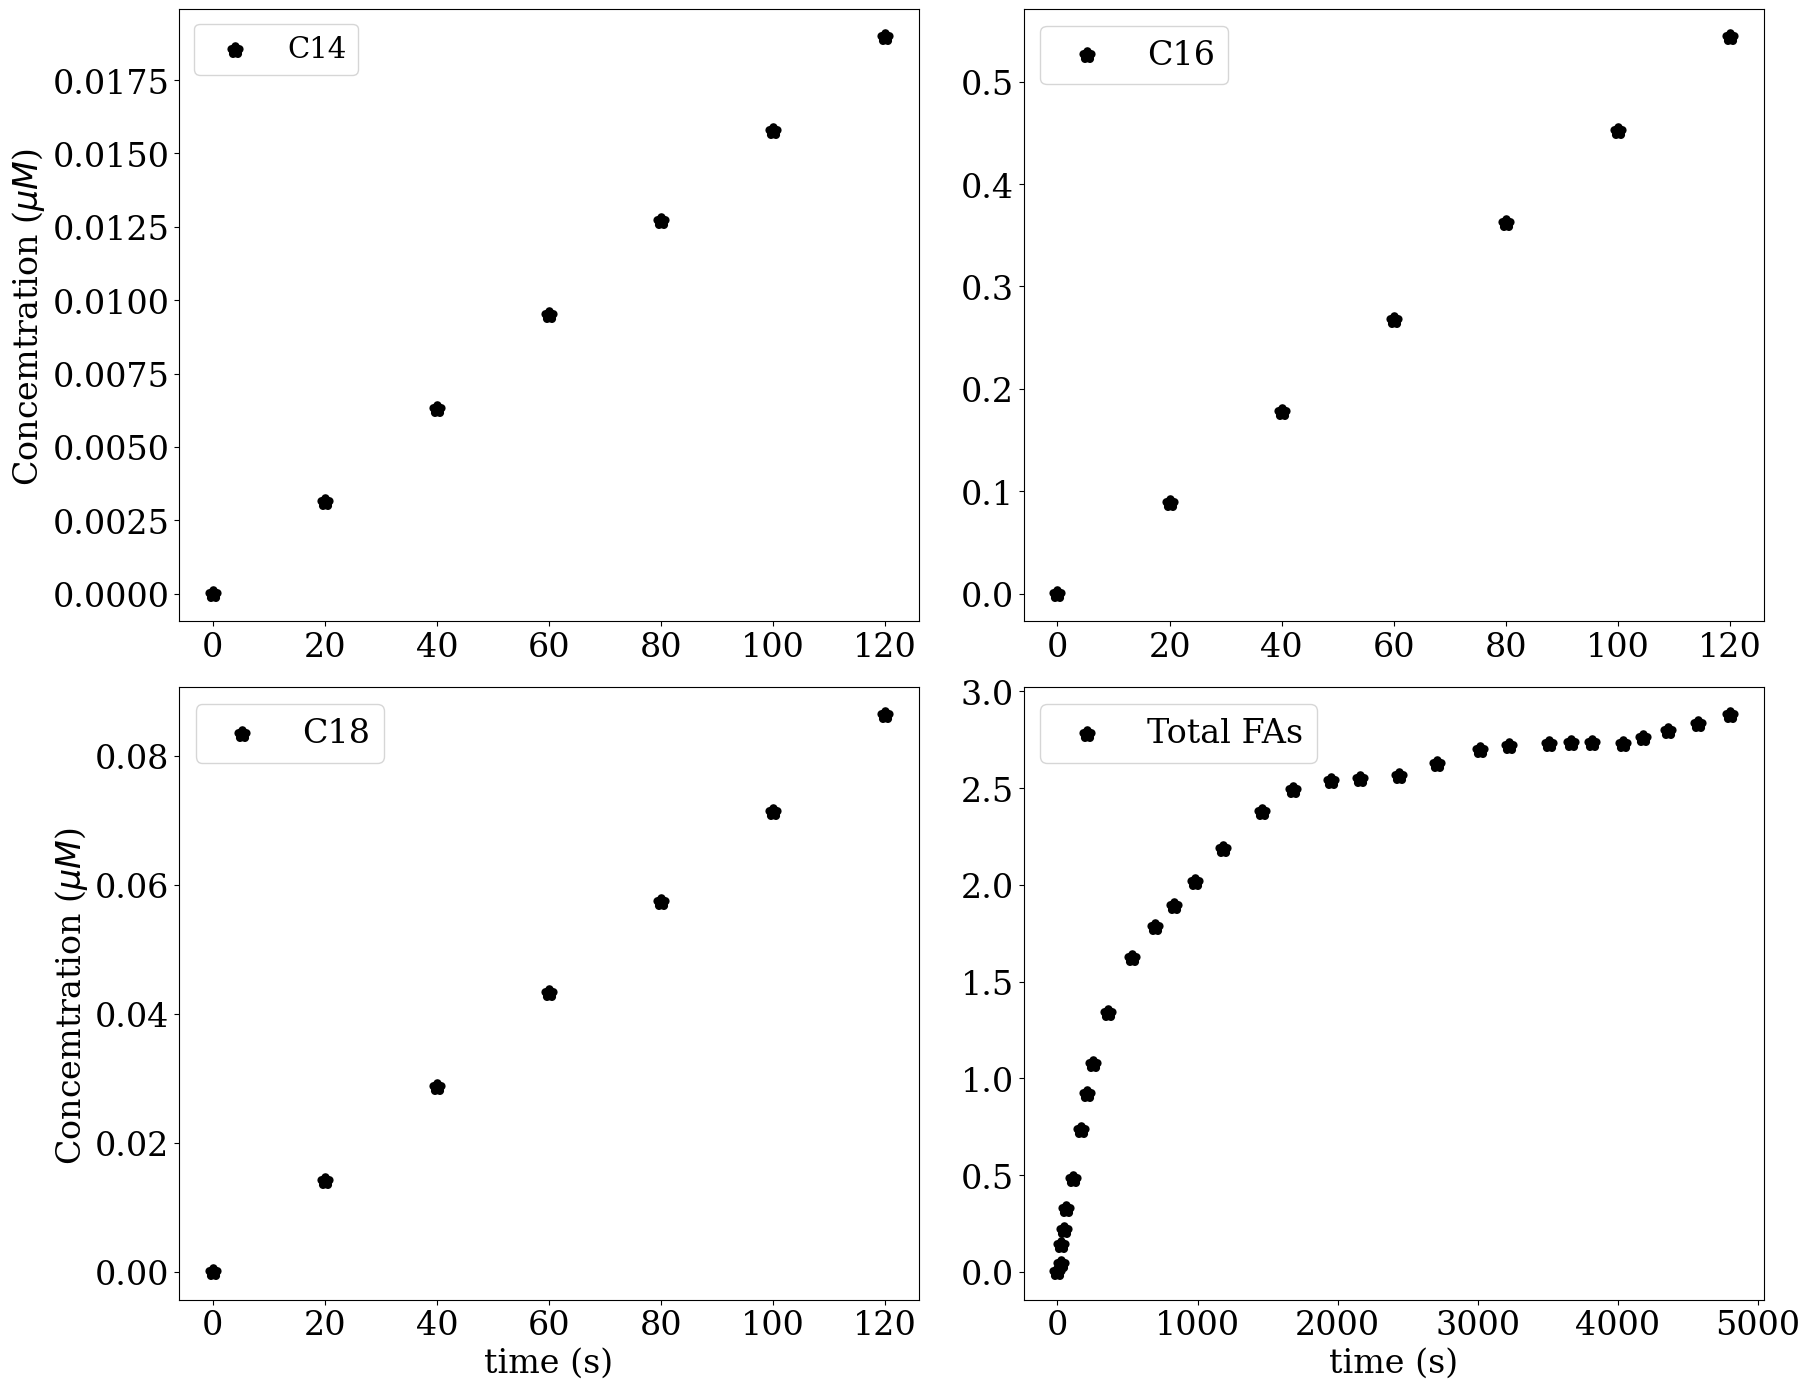

In [3]:
fig, axs = plt.subplots(2, 2, figsize=(18, 14))
axs[0, 0].scatter(
    time_initial_phase,
    data_initial_phase.T[0],
    marker="*",
    linewidth=6,
    label="C14",
    color="k",
)
axs[0, 0].legend(loc="best", fontsize=21)
axs[0, 1].scatter(
    time_initial_phase,
    data_initial_phase.T[1],
    marker="*",
    linewidth=6,
    label="C16",
    color="k",
)
axs[0, 1].legend(loc="best", fontsize=24)
axs[1, 0].scatter(
    time_initial_phase,
    data_initial_phase.T[2],
    marker="*",
    linewidth=6,
    label="C18",
    color="k",
)
axs[1, 0].legend(loc="best", fontsize=24)
axs[1, 1].scatter(
    time_nefas1_simulation,
    total_nefas1,
    marker="*",
    linewidth=6,
    label="Total FAs",
    color="k",
)
axs[1, 1].legend(loc="best", fontsize=24)


for ax in axs[:, 0]:
    ax.set_ylabel("Concemtration ($\mu M$) ", fontsize=24)
for ax in axs[-1, :]:
    ax.set_xlabel("time (s)", fontsize=24)
for ax in axs.flatten():
    ax.tick_params(axis="both", labelsize=24)
fig.tight_layout()
plt.savefig(RESULTS_DIR / "data.pdf", dpi=300, bbox_inches="tight")


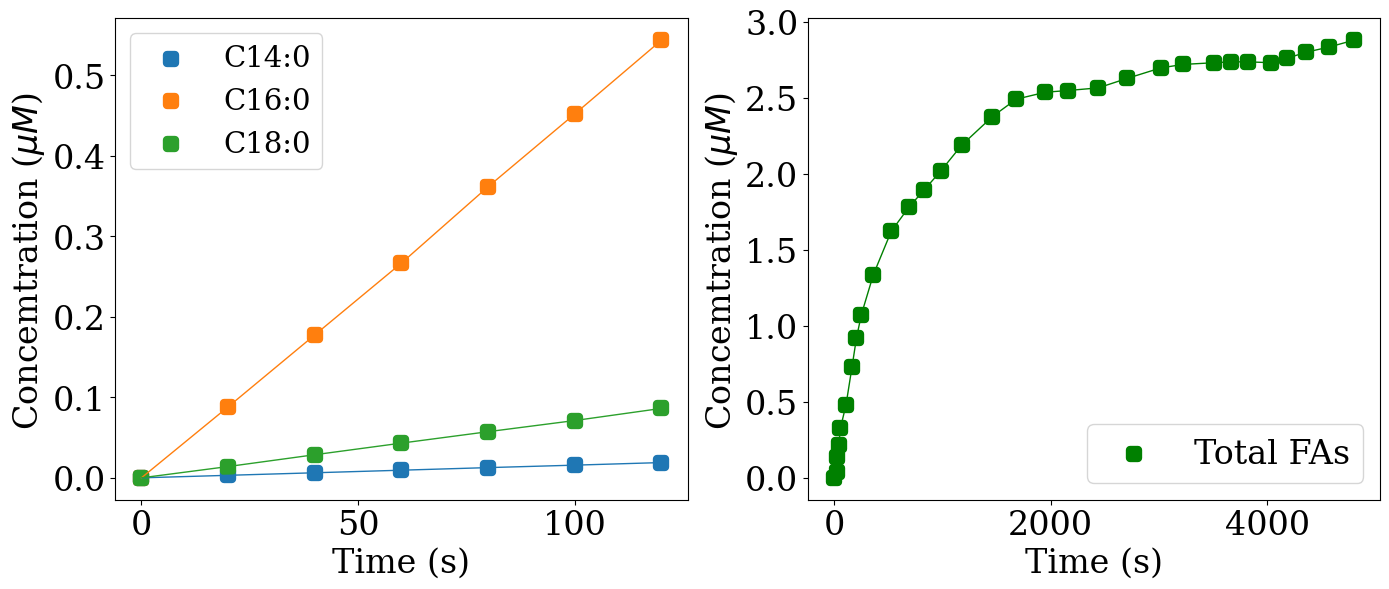

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(14, 6))
axs[0].plot(
    time_initial_phase,
    data_initial_phase.T[0],
    "-",
    linewidth=1,
)
axs[0].plot(
    time_initial_phase,
    data_initial_phase.T[1],
    "-",
    linewidth=1,
)
axs[0].plot(
    time_initial_phase,
    data_initial_phase.T[2],
    "-",
    linewidth=1,
)
axs[0].scatter(
    time_initial_phase, data_initial_phase.T[0], marker="s", linewidth=6, label="C14:0"
)
axs[0].scatter(
    time_initial_phase, data_initial_phase.T[1], marker="s", linewidth=6, label="C16:0"
)
axs[0].scatter(
    time_initial_phase, data_initial_phase.T[2], marker="s", linewidth=6, label="C18:0"
)
axs[1].plot(
    time_nefas1_simulation,
    total_nefas1,
    marker="s",
    linewidth=1,
    color="g",
)
axs[0].legend(loc="best", fontsize=21)
axs[1].scatter(
    time_nefas1_simulation,
    total_nefas1,
    marker="s",
    linewidth=6,
    label="Total FAs",
    color="g",
)
axs[1].legend(loc="best", fontsize=24)
for ax in axs:
    ax.set_ylabel(r"Concemtration ($\mu M$) ", fontsize=24)
for ax in axs:
    ax.set_xlabel("Time (s)", fontsize=24)
for ax in axs.flatten():
    ax.tick_params(axis="both", labelsize=24)
# fig.suptitle("title", fontsize=20.0)

fig.tight_layout()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "topolska_trans.pdf", dpi=300, bbox_inches="tight")


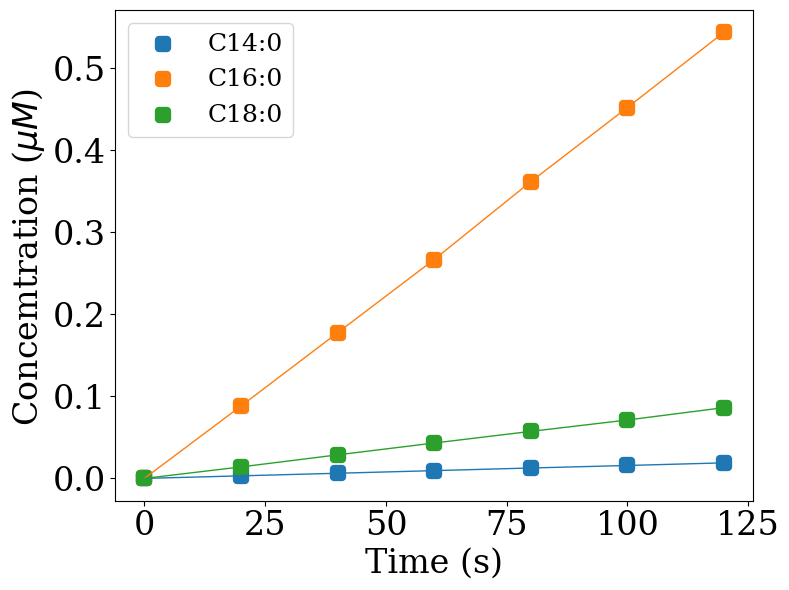

In [5]:
fig, axs = plt.subplots(1, 1, figsize=(8, 6))
axs.plot(
    time_initial_phase,
    data_initial_phase.T[0],
    "-",
    linewidth=1,
)
axs.plot(
    time_initial_phase,
    data_initial_phase.T[1],
    "-",
    linewidth=1,
)
axs.plot(
    time_initial_phase,
    data_initial_phase.T[2],
    "-",
    linewidth=1,
)
axs.scatter(
    time_initial_phase, data_initial_phase.T[0], marker="s", linewidth=6, label="C14:0"
)
axs.scatter(
    time_initial_phase, data_initial_phase.T[1], marker="s", linewidth=6, label="C16:0"
)
axs.scatter(
    time_initial_phase, data_initial_phase.T[2], marker="s", linewidth=6, label="C18:0"
)
axs.legend(loc="best", fontsize=18)
fig.patch.set_alpha(0.0)  # to make the axis transparent
axs.legend(prop=dict(size=18))
# axs.set_title(" Initial phase data from Topolska et al. 2020", fontsize =24, fontname="serif", fontweight="bold",  pad=20)
axs.set_ylabel("Concemtration ($\mu M$) ", fontsize=24)
# fig.suptitle( " Initial phase data from Topolska et al. 2020", fontname="serif", fontweight="bold")
axs.set_xlabel("Time (s)", fontsize=24)

axs.tick_params(axis="both", labelsize=24)
# fig.suptitle("title", fontsize=20.0)
fig.tight_layout()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "topolska_initial.pdf", dpi=300, bbox_inches="tight")


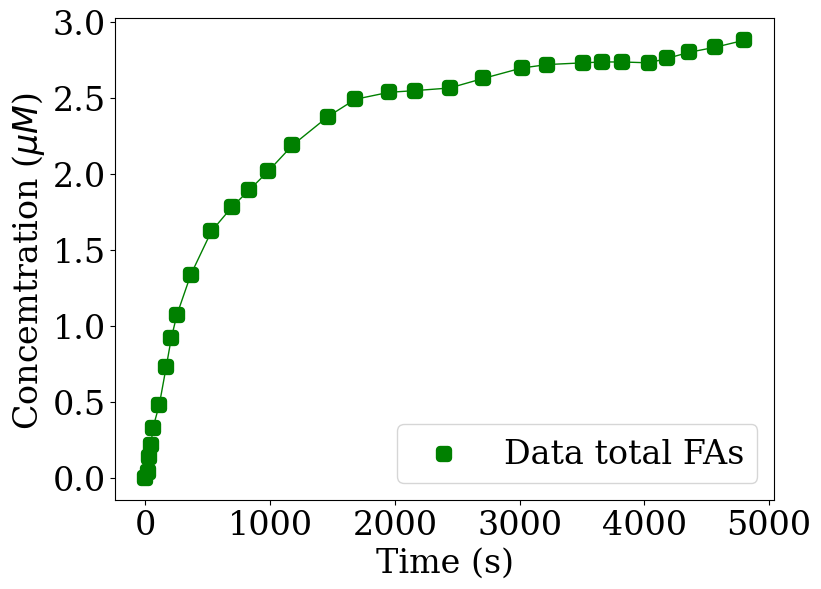

In [6]:
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
ax.plot(
    time_nefas1_simulation,
    total_nefas1,
    marker="s",
    linewidth=1,
    color="g",
)
ax.scatter(
    time_nefas1_simulation,
    total_nefas1,
    marker="s",
    linewidth=6,
    label="Data total FAs",
    color="g",
)
ax.legend(loc="best", fontsize=24)
ax.legend(prop=dict(size=24))

# ax.set_title(" Total fatty acids from Topolska et al. 2020", fontsize =24,  fontname="serif", fontweight="bold", pad=20)
ax.set_ylabel("Concemtration ($\mu M$) ", fontsize=24)

ax.set_xlabel("Time (s)", fontsize=24)
fig.patch.set_alpha(0.0)  # to make the axis transparent
ax.tick_params(axis="both", labelsize=24)
# fig.suptitle("title", fontsize=20.0)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "topolska_total.pdf", dpi=300, bbox_inches="tight")


# Fuction for simulations 

In [7]:
def plot_individual_time_course(
    compounds_to_plot: list[str],
    func: Callable,
    model: Callable,
    y0: list[float],
    max_time: float,
    ncp_list: list[float],
    par: dict[str, float],
    compounds: list[str],
    ncols: int,
    resizer=4,
    sharex=True,
    sharey=False,
    title: str = None,
    xlabel: str = None,
    ylabel: str = None,
):
    """
    required library: pandas, matplotlib, assimulo
    func = function that simulate the time course
    model =  system of differential equation to be integrated
    y0 = initial condition it can be either a list of float or np.1D.array
    max_time =  maximum time for simulation
    ncp_list = number of communication points
    compounds =  list of compounds to be plotted
    par =  dictionnay of string to float

    """
    time, y = simulate_time_course(
        model=system, par=par, y0=y0, max_time=max_time, ncp_list=ncp_list
    )
    y = y.T
    Comp = dict(zip(compounds, y))
    data = pd.DataFrame(Comp)

    nrows = ceil(len(compounds_to_plot) / ncols)

    fig, axs = plt.subplots(
        nrows,
        ncols,
        figsize=(resizer * ncols, resizer * nrows),
        sharex=sharex,
        sharey=sharey,
        squeeze=False,
    )

    for ax, group in zip(axs.flatten(), compounds_to_plot):
        data.loc[:, group].plot(ax=ax, linewidth=5)
        ax.set_title(group, fontsize=28.0, fontname="serif", fontweight="bold")

    for ax in axs[:, 0]:
        ax.set_ylabel(ylabel, fontsize=24.0)
    for ax in axs[-1, :]:
        ax.set_xlabel(xlabel, fontsize=24.0)
    for ax in axs.flatten():
        ax.tick_params(axis="both", labelsize=18)
    fig.suptitle(title, fontname="serif", fontweight="bold")

    fig.tight_layout()

    return fig, axs


In [8]:
def multi_plot_time_course(
    groups: list[list],
    func: callable,
    model: callable,
    y0: list[float],
    par: dict[str, float],
    max_time: float,
    ncp_list: list[float],
    compounds: list[str],
    ncols: int,
    resizer=4,
    sharex=False,
    sharey=False,
    title: str = None,
    xlabel: str = None,
    ylabel: str = None,
):
    """
    required library: pandas, matplotlib, assimulo
    group = group of compounds to be plotted (just giving the oportunityto plot them together)
    func = function that simulate the time course
    model =  system of differential equation to be integrated
    y0 = initial condition it can be either a list of float or np.1D.array
    max_time =  maximum time for simulation
    ncp_list = number of communication points
    compounds =  list of compounds to be plotted
    par =  dictionnay of string to float

    """
    time, y = simulate_time_course(
        model=system, par=par, y0=y0, max_time=max_time, ncp_list=ncp_list
    )
    y = y.T
    Comp = dict(zip(compounds, y))
    data = pd.DataFrame(Comp)

    nrows = ceil(len(groups) / ncols)

    fig, axs = plt.subplots(
        nrows,
        ncols,
        figsize=(resizer * ncols, resizer * nrows),
        sharex=sharex,
        sharey=sharey,
        squeeze=False,
    )

    for ax, group in zip(axs.flatten(), groups):
        data.reindex(columns=group).plot(ax=ax, linewidth=5)
        ax.legend(prop=dict(size=18))
    for ax in axs[:, 0]:
        ax.set_ylabel(ylabel, fontsize=26.0)
    for ax in axs[-1, :]:
        ax.set_xlabel(xlabel, fontsize=26.0)
    for ax in axs.flatten():
        ax.tick_params(axis="both", labelsize=20)
    fig.suptitle(title, fontsize=32.0, fontname="serif", fontweight="bold", y=1.01)
    fig.patch.set_alpha(0.0)

    fig.tight_layout()
    return fig, axs


In [9]:
def multi_plot_fluxes(
    fluxes_list: list[list[str]],
    model: callable,
    rates: callable,
    y0: list[float],
    par: dict[str, float],
    max_time: float,
    ncp_list: list[float],
    ncols: int,
    resizer=4,
    sharex=True,
    sharey=False,
    title: str = None,
    xlabel: str = None,
    ylabel: str = None,
):

    """
    required library: pandas, matplotlib, assimulo
      flux_groups = list of list of  fluxes to be plotted, indeed the entrees should match the list of
    keys in the rates dictionnary
    model = system of ODE to be integrated(this function is dependent of the rate )
    rates = funtion that define the rates
    y0 = list/np.1D.array  of initial conditions
    par = dictionnary of parameters( dictionnay of string to float)
    max_time =  maximum time for simulation
    ncp_list = number of communication points to be passed to the integrator
    ncols  = number of colums for the subplots


    """

    time, y = simulate_time_course(
        model=system, par=par, y0=y0, max_time=max_time, ncp_list=ncp_list
    )
    y = y.T
    fluxes = pd.DataFrame(rates(y, par))
    nrows = ceil(len(fluxes_list) / ncols)
    fig, axs = plt.subplots(
        nrows,
        ncols,
        figsize=(resizer * ncols, resizer * nrows),
        sharex=sharex,
        sharey=sharey,
        squeeze=False,
    )
    for ax, group in zip(axs.flatten(), fluxes_list):
        fluxes.reindex(columns=group).plot(
            ax=ax,
            fontsize=18,
            linewidth=5,
        )
        ax.legend(prop=dict(size=16))
    for ax in axs[:, 0]:
        ax.set_ylabel(ylabel, fontsize=24.0)
    for ax in axs[-1, :]:
        ax.set_xlabel(xlabel, fontsize=24.0)
    for ax in axs.flatten():
        ax.tick_params(axis="both", labelsize=18)
    fig.suptitle(title, fontsize=28.0, fontname="serif", fontweight="bold")
    fig.tight_layout()
    return fig, axs


In [10]:
def plot_fluxes_individually(
    list_fluxes: list[str],
    model: callable,
    rates: callable,
    y0: list[float],
    par: dict[str, float],
    max_time: float,
    ncp_list: list[float],
    ncols: int,
    resizer=4,
    sharey=False,
    sharex=True,
    title: str = None,
    xlabel: str = None,
    ylabel: str = None,
):

    """
    required library: pandas, matplotlib, assimulo
    list_fluxes = list of fluxes to be plotted, indeed the entrees should match the list of
    keys in the rates dictionnary
    model = system of ODE to be integrated(this function is dependent of the rate )
    rates = funtion that define the rates
    y0 = list/np.1D.array  of initial conditions
    par = dictionnary of parameters( dictionnay of string to float)
    max_time =  maximum time for simulation
    ncp_list = number of communication points to be passed to the integrator
    ncols  = number of colums for the subplots


    """

    time, y = simulate_time_course(
        model=system, par=par, y0=y0, max_time=max_time, ncp_list=ncp_list
    )

    y = y.T
    fluxes = pd.DataFrame(rates(y, par))

    nrows = ceil(len(list_fluxes) / ncols)

    fig, axs = plt.subplots(
        nrows,
        ncols,
        figsize=(resizer * ncols, resizer * nrows),
        sharey=sharey,
        sharex=sharex,
        squeeze=False,
    )
    for ax, group in zip(axs.flatten(), list_fluxes):
        fluxes.loc[:, group].plot(ax=ax, linewidth=5)
        ax.set_title(group, fontsize=28.0)

    for ax in axs[:, 0]:
        ax.set_ylabel(ylabel, fontsize=24.0)
    for ax in axs[-1, :]:
        ax.set_xlabel(xlabel, fontsize=24.0)
    for ax in axs.flatten():
        ax.tick_params(axis="both", labelsize=14)
    fig.suptitle(title, fontsize=28.0, fontname="serif", fontweight="bold")
    fig.tight_layout()
    return fig, axs


# Simulation of the model 

## First choice parameters 
We consider the scenario in which only three type of fatty acids could be produced, those are C14, C16 and C18. Therefore, all the $ka_i = 0$, $kd_1$ to $kd_5$ are all 0. The value of $\kappa$ was calculated by considering the quasi steady state of all enzyme species and the initial phase data from *Topolska et al*. 2020.

In [11]:
par = {
    "beta": 1e-01,
    "kappa": 1e-1,
    "delta": 3.4e-07,  #
    "kd6": 0.56,
    "kd7": 0.014,  #
    "kd8": 10,
    "FASt": 0.153,
    "kf_CoA": 1e-3,
    "kb_CoA": 1e-4,
    "kf_mal": 1e-3,
    "kb_mal": 1e-4,
    "kf_acet": 1e-3,
    "kb_acet": 1e-4,
}


## The initial conditions 

In the tracer experiment by *Topolska et al. 2020* to measure the t

According to *Topolska et al. 2020* A the malonyl-CoA that was used for this experiment was contaminated by acetyl-CoA and there we have to make the corrections for the right amount of each substrates used in this experiment. 
The main product of the de novo fatty acids synthesis which is C16:0 
The correction for the initial conditions for acetyl-CoA and malonyl-CoA was first tried by 

In [12]:
# list of time points to be considered by the integrator
ncp_list1 = [i for i in range(0, 120, 1)]
ncp_list2 = [i for i in range(0, 4800)]
max_time1 = ncp_list1[-1]
max_time2 = ncp_list2[-1]
init = np.zeros(n_compounds)
# init = 10*np.random.uniform(0,1,n_compounds)
time_initial_phase = initial_phase_data[:, 0]
y0_dict = dict(zip(compounds, init))

# modifying initial conditions
y0_dict["E"] = 0.153
y0_dict["AcetylCoA"] = 50 + (80 - 22.04)
y0_dict["NADPH"] = 200
y0_dict["MalonylCoA"] = 22.04
# y0_dict["C4FA"] = 0.0
# y0_dict["C6FA"] = 0.0
# y0_dict["C8FA"] = 0.0
# y0_dict["C10FA"] = 0.0
# y0_dict["C12FA"] = 0.0
y0_dict["C14FA"] = 0.0
y0_dict["C16FA"] = 0.0
y0_dict["C18FA"] = 0.0
y0 = np.fromiter(y0_dict.values(), dtype=float)


In [13]:
compounds = [
    "AcetylCoA",
    "MalonylCoA",
    "C14FA",
    "C16FA",
    "C18FA",
    "CoA",
    "E",
    "EC2",
    "EC4",
    "EC6",
    "EC8",
    "EC10",
    "EC12",
    "EC14",
    "EC16",
    "EC18",
    "ECoA",
    "EMal",
    "EC2Acet",
    "EC4Acet",
    "EC6Acet",
    "EC8Acet",
    "EC10Acet",
    "EC12Acet",
    "EC14Acet",
    "EC16Acet",
    "EC18Acet",
    "NADPH",
]


# Check the fluxes 

### Plot fluxes by group

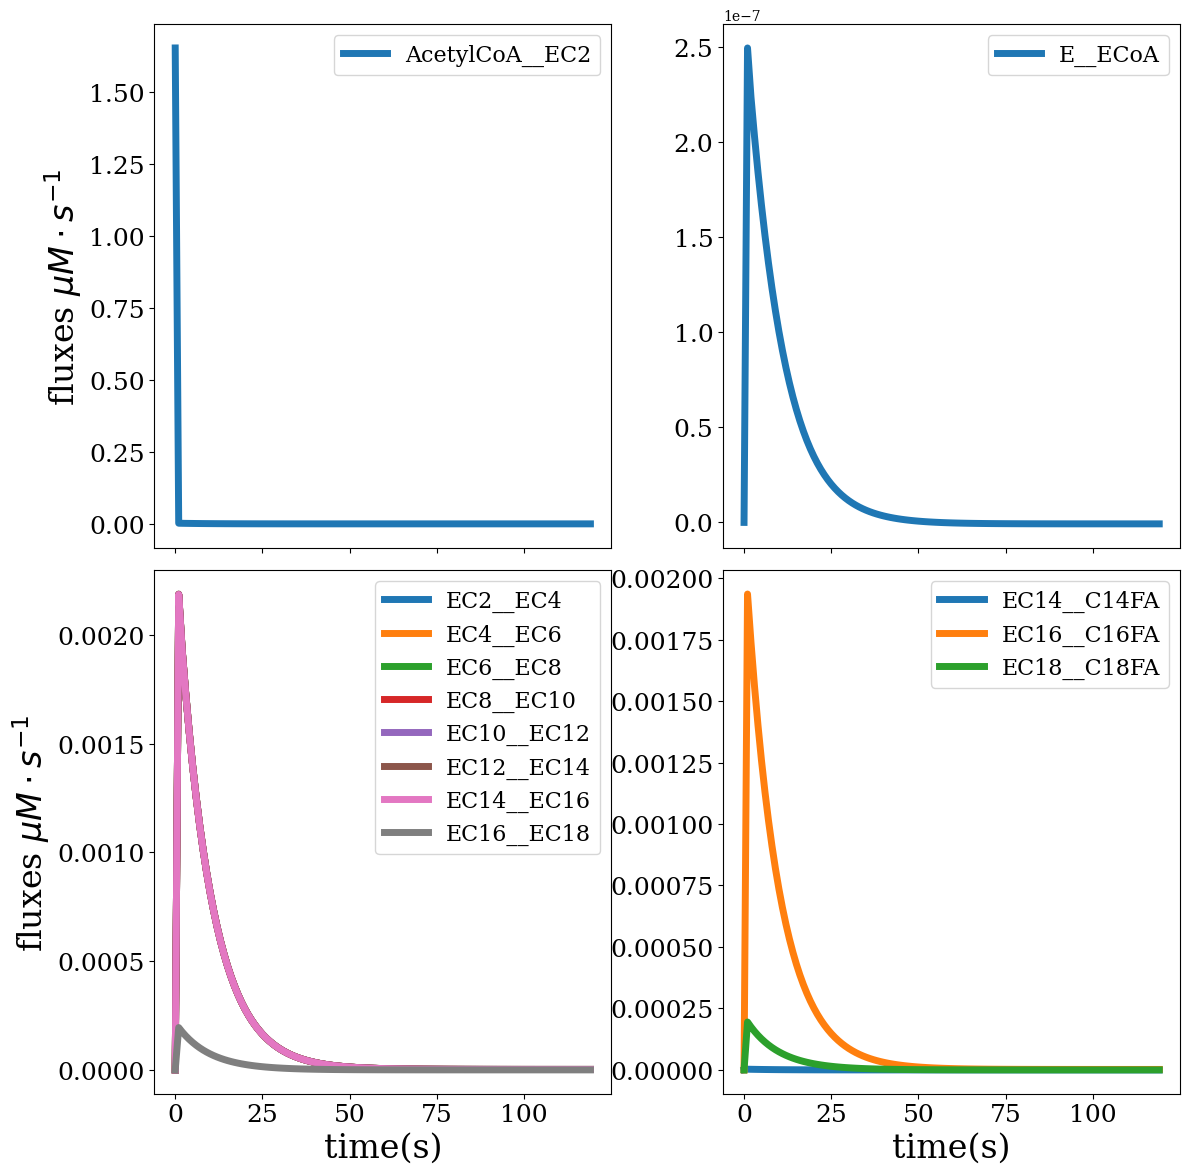

In [14]:
flux_groups = [
    ["AcetylCoA__EC2"],
    ["E__ECoA"],
    [
        "EC2__EC4",
        "EC4__EC6",
        "EC6__EC8",
        "EC8__EC10",
        "EC10__EC12",
        "EC12__EC14",
        "EC14__EC16",
        "EC16__EC18",
    ],
    [
    
        "EC14__C14FA",
        "EC16__C16FA",
        "EC18__C18FA",
    ],
   
]


fig, axs = multi_plot_fluxes(
    fluxes_list=flux_groups,
    model=system,
    rates=rates,
    y0=y0,
    par=par,
    max_time=max_time1,
    ncp_list=ncp_list1,
    ncols=2,
    resizer=6,
    sharey=False,
    title=None,
    xlabel="time(s)",
    ylabel="fluxes $\mu M \cdot s^{-1}$",
)


### Elongation individual fluxes 

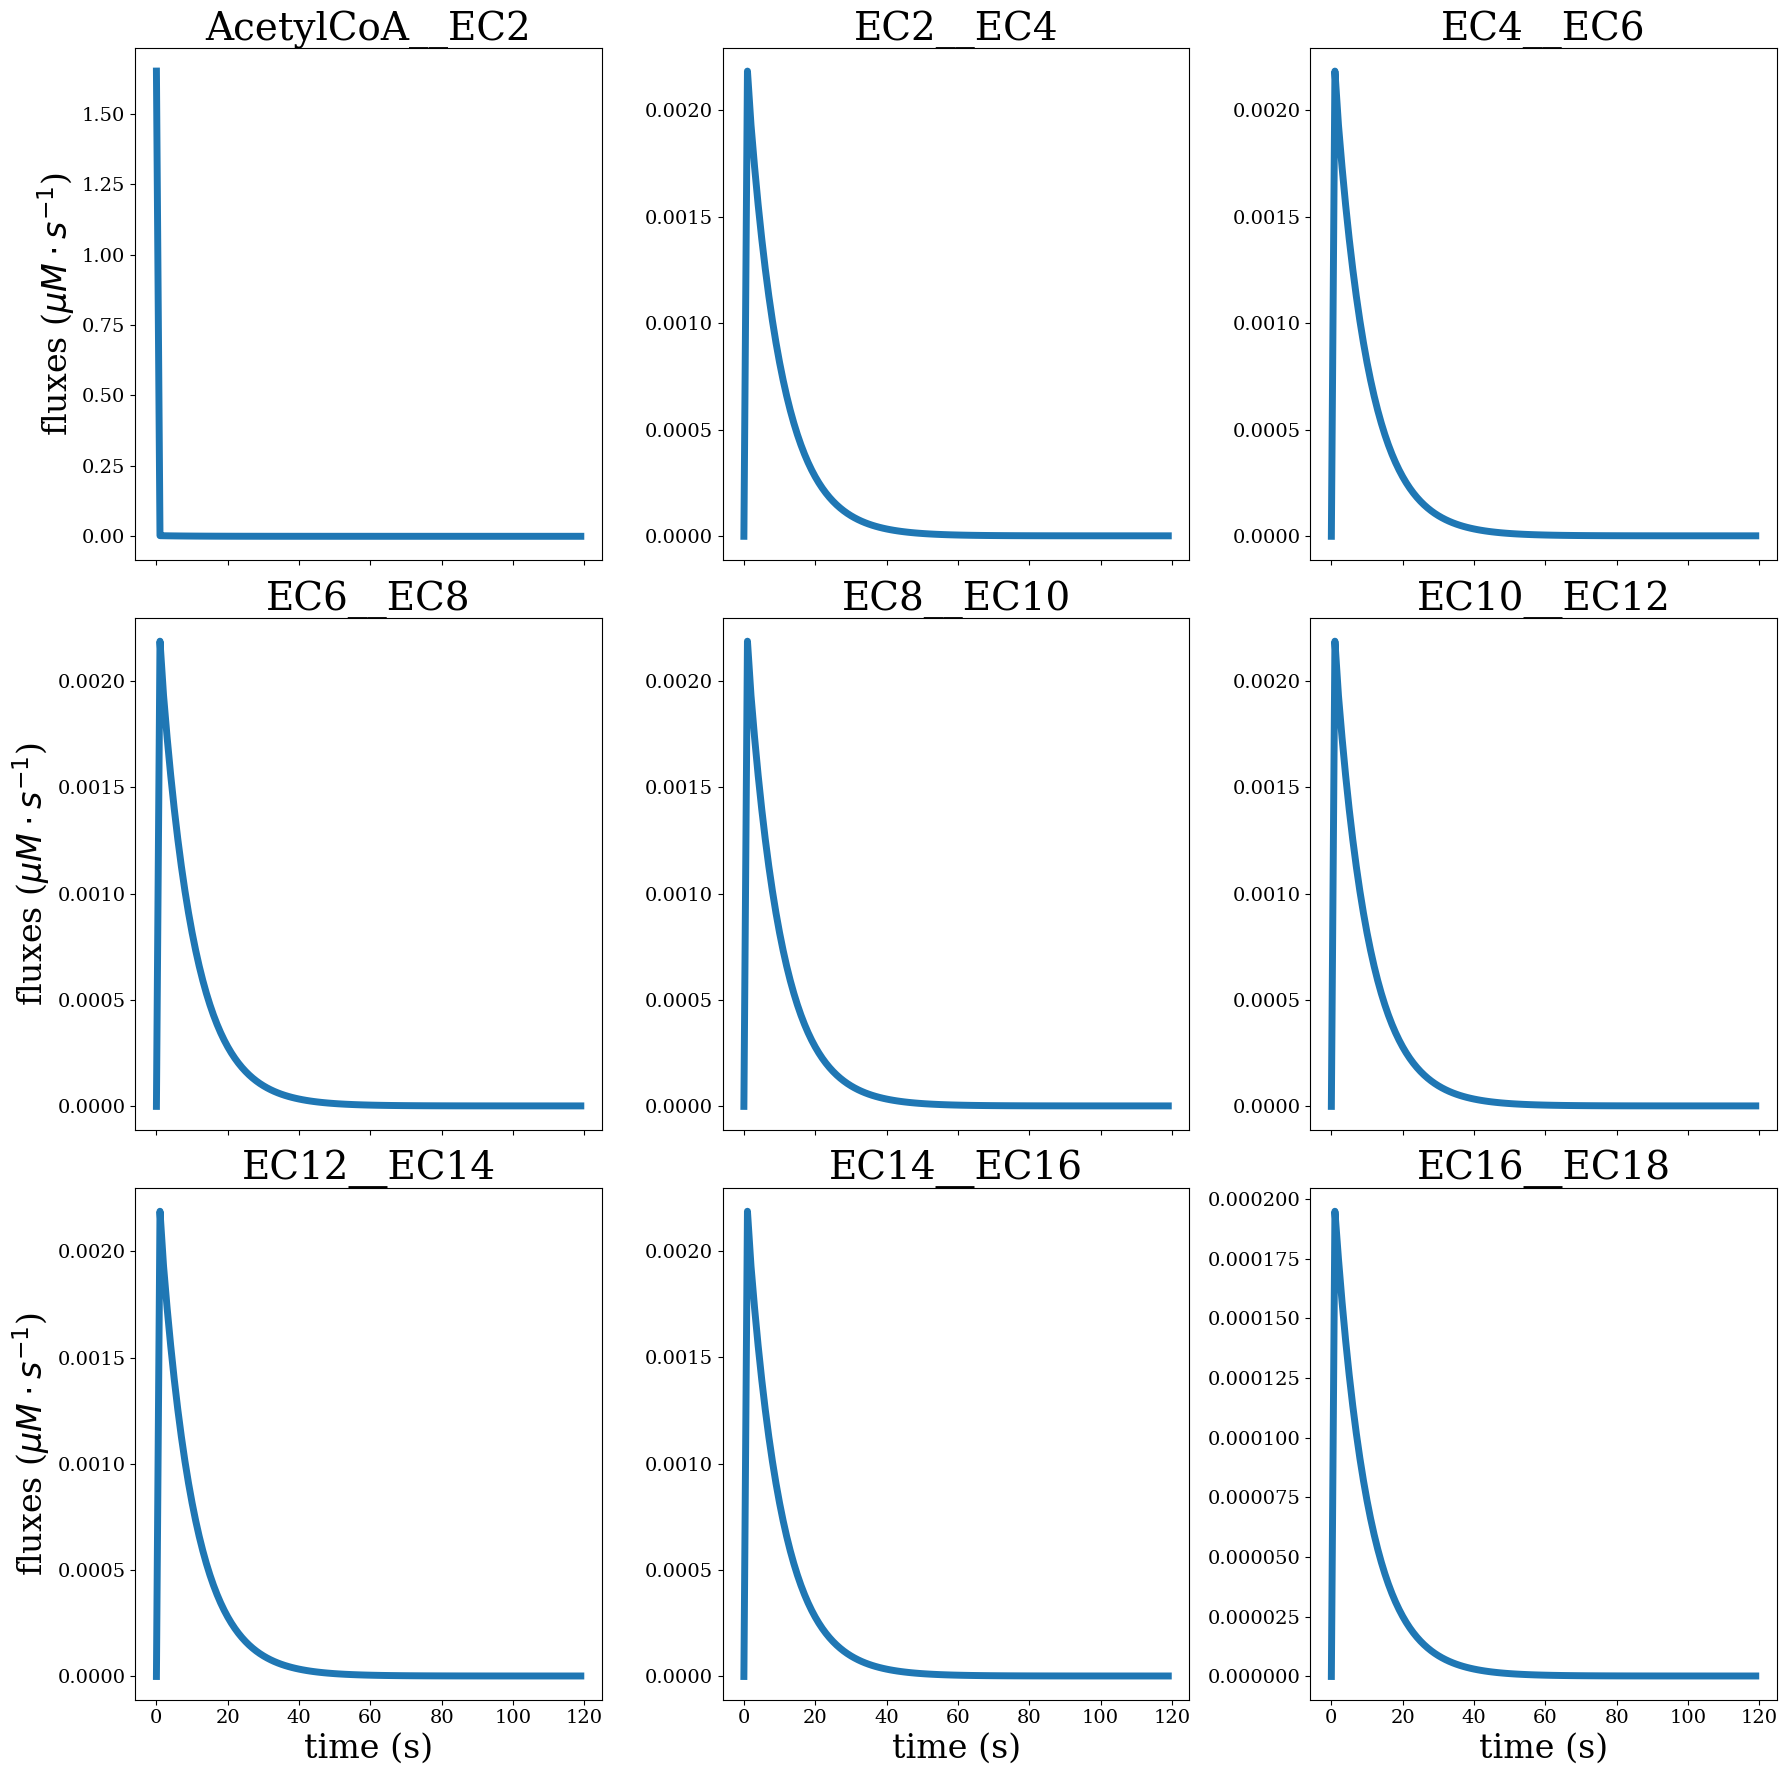

In [15]:
elongation_fluxes = [
    "AcetylCoA__EC2",
    "EC2__EC4",
    "EC4__EC6",
    "EC6__EC8",
    "EC8__EC10",
    "EC10__EC12",
    "EC12__EC14",
    "EC14__EC16",
    "EC16__EC18",
]

fig, axs = plot_fluxes_individually(
    list_fluxes=elongation_fluxes,
    model=system,
    rates=rates,
    y0=y0,
    par=par,
    max_time=max_time1,
    ncp_list=ncp_list1,
    ncols=3,
    resizer=6,
    sharey=False,
    #         title: str = None,
    xlabel="time (s)",
    ylabel=r"fluxes ($\mu M \cdot s^{-1}$)",
)


### production individual fluxes 

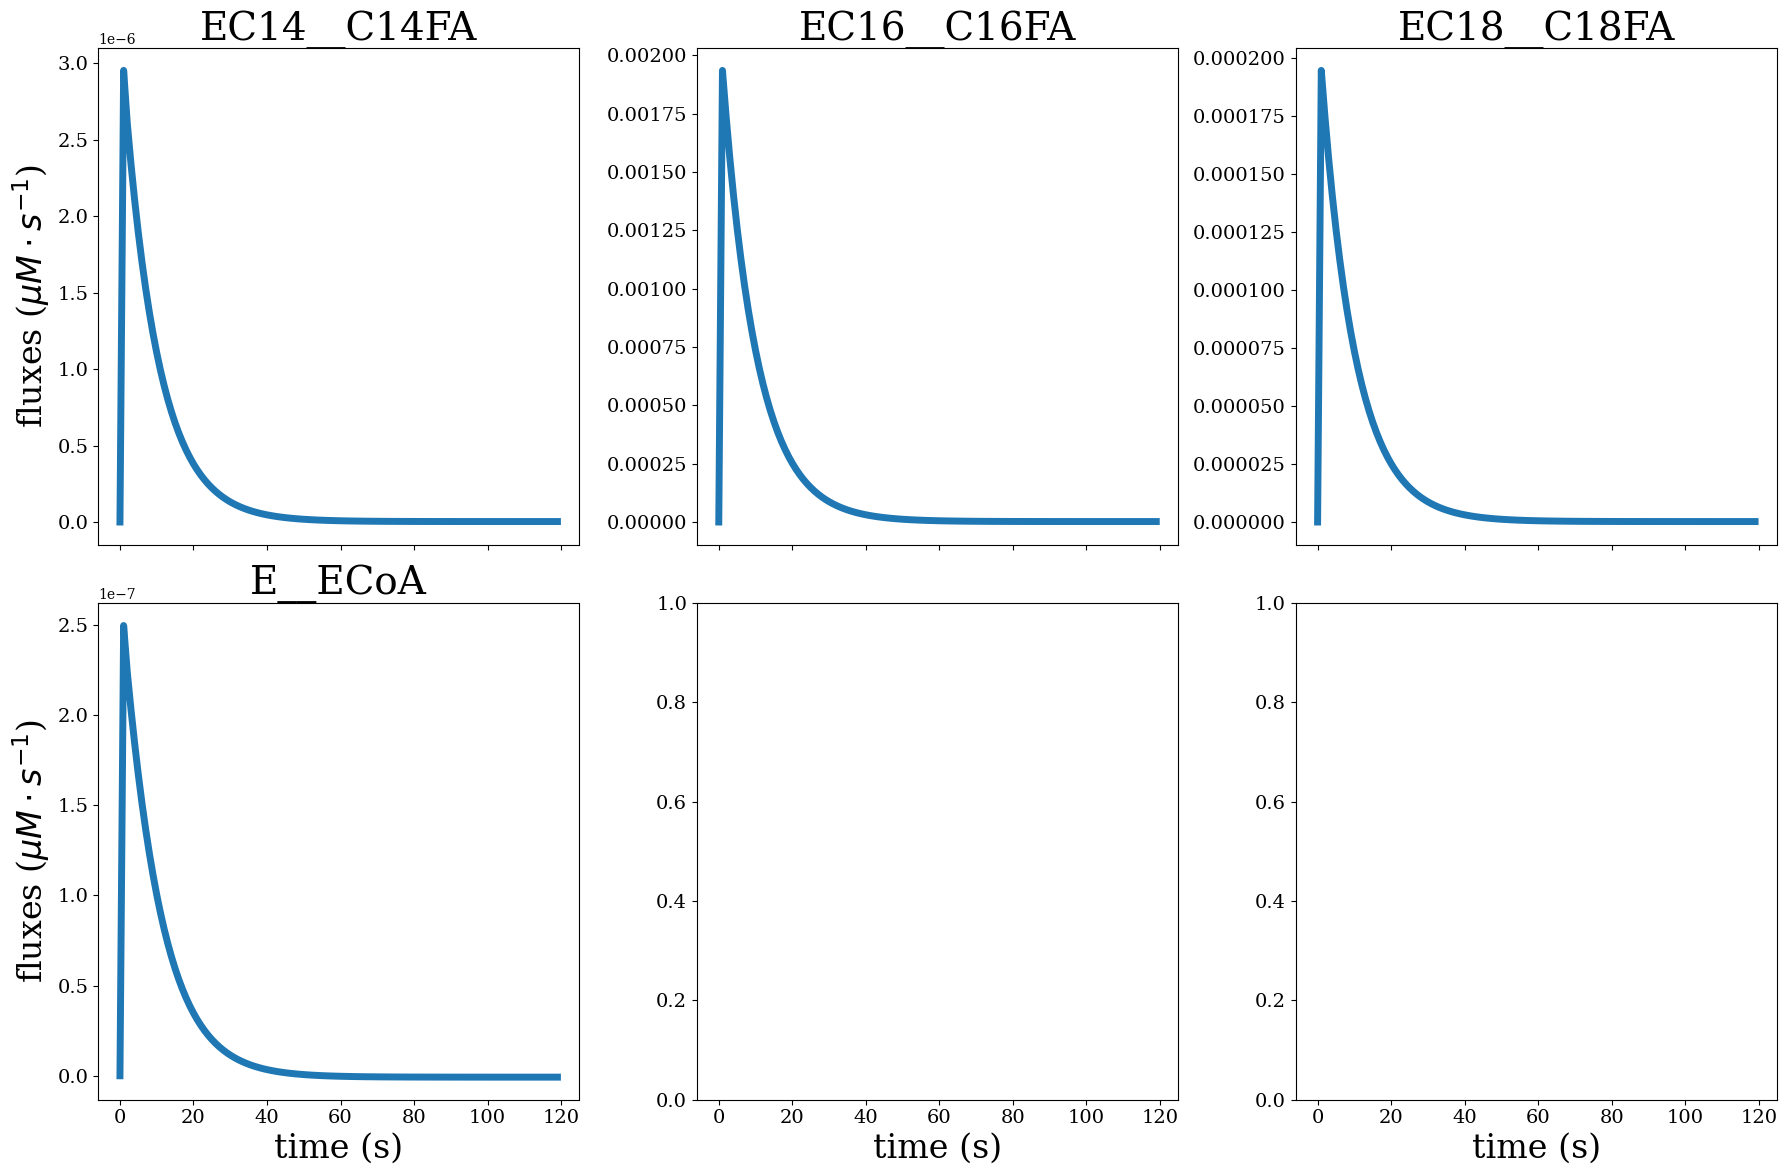

In [16]:
production_fluxes = [
   
    "EC14__C14FA",
    "EC16__C16FA",
    "EC18__C18FA",
    "E__ECoA",
]


fig, axs = plot_fluxes_individually(
    list_fluxes=production_fluxes,
    model=system,
    rates=rates,
    y0=y0,
    par=par,
    max_time=max_time1,
    ncp_list=ncp_list1,
    ncols=3,
    resizer=6,
    sharey=False,
    #         title: str = None,
    xlabel="time (s)",
    ylabel=r"fluxes ($\mu M \cdot s^{-1}$)",
)


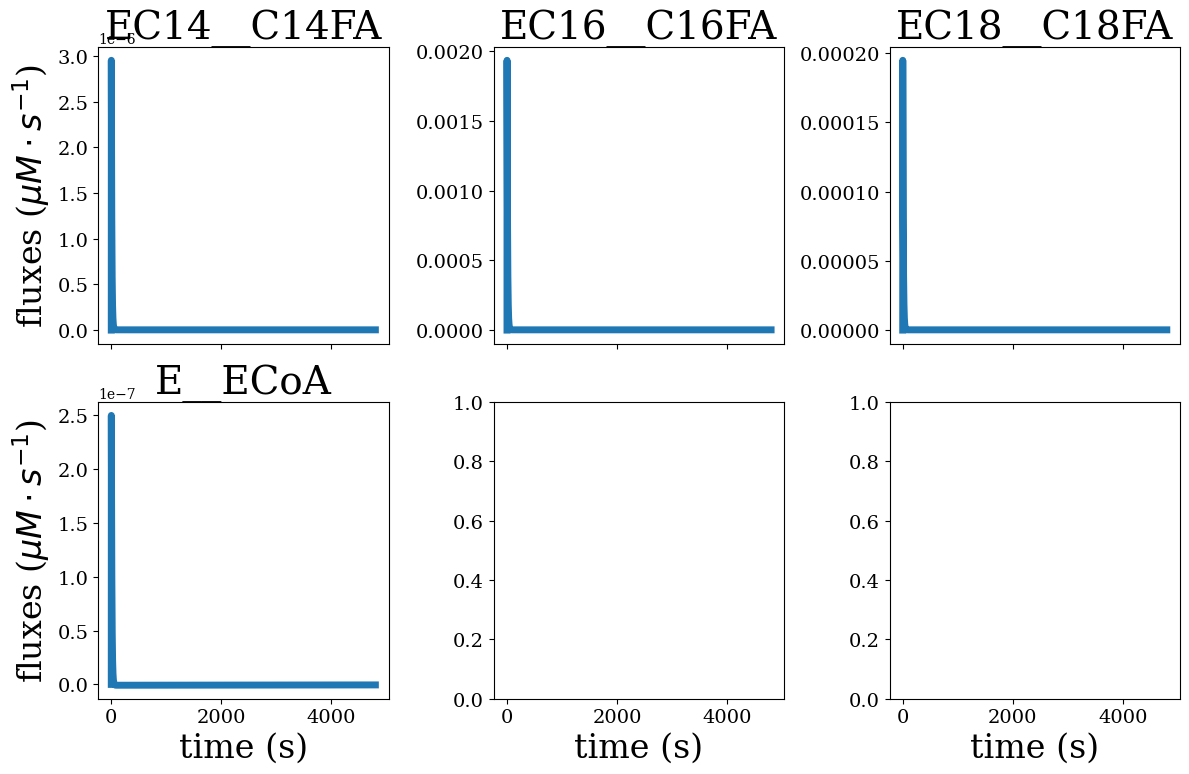

In [17]:
fig, axs = plot_fluxes_individually(
    list_fluxes=production_fluxes,
    model=system,
    rates=rates,
    y0=y0,
    par=par,
    max_time=max_time2,
    ncp_list=ncp_list2,
    ncols=3,
    resizer=4,
    sharey=False,
    #         title: str = None,
    xlabel="time (s)",
    ylabel="fluxes ($\mu M \cdot s^{-1}$)",
)


# Plot the time course 

### Plot time course by group

To Estimate the value of parameters that reproduce Topolska and al. data, we first consider the rapid binding given that the subtrates are in excess.Furthermore we consider that production of short and meduim chain fatty acid are negligeable compare to to those of LCFAS as shown by experimental data.On this assumptions, instantaneously the concentration of the total enzyme is sensibly equal to the cocentrattion of $EC_{16}$. From this concentration of the enzyme we can estimate $k_{d7}$ and $\delta$. For the estimation of the later, we additionnally assume that the flux into $EC_{18}$ are equal to the flux of production of of $C18:0$ FA.

under this assumptions, we have $$k_{d7} = 0.014, \qquad  \delta= 2.9e-07$$


We choose the value of $\beta$ and $\kappa$

In [119]:


par = {
    "beta": 1e-2,
    "kappa": 1e-5,
    "delta": 3.4e-07,  
    "kd6": 0.01,
    "kd7": 0.03,  #
    "kd8": 1,
    "kf_CoA": 1e-4,
    "kb_CoA": 1e-1,
    "kf_mal": 1e-4,
    "kb_mal": 1e-1,
    "kf_acet": 1e-4,
    "kb_acet": 1e-1,
}



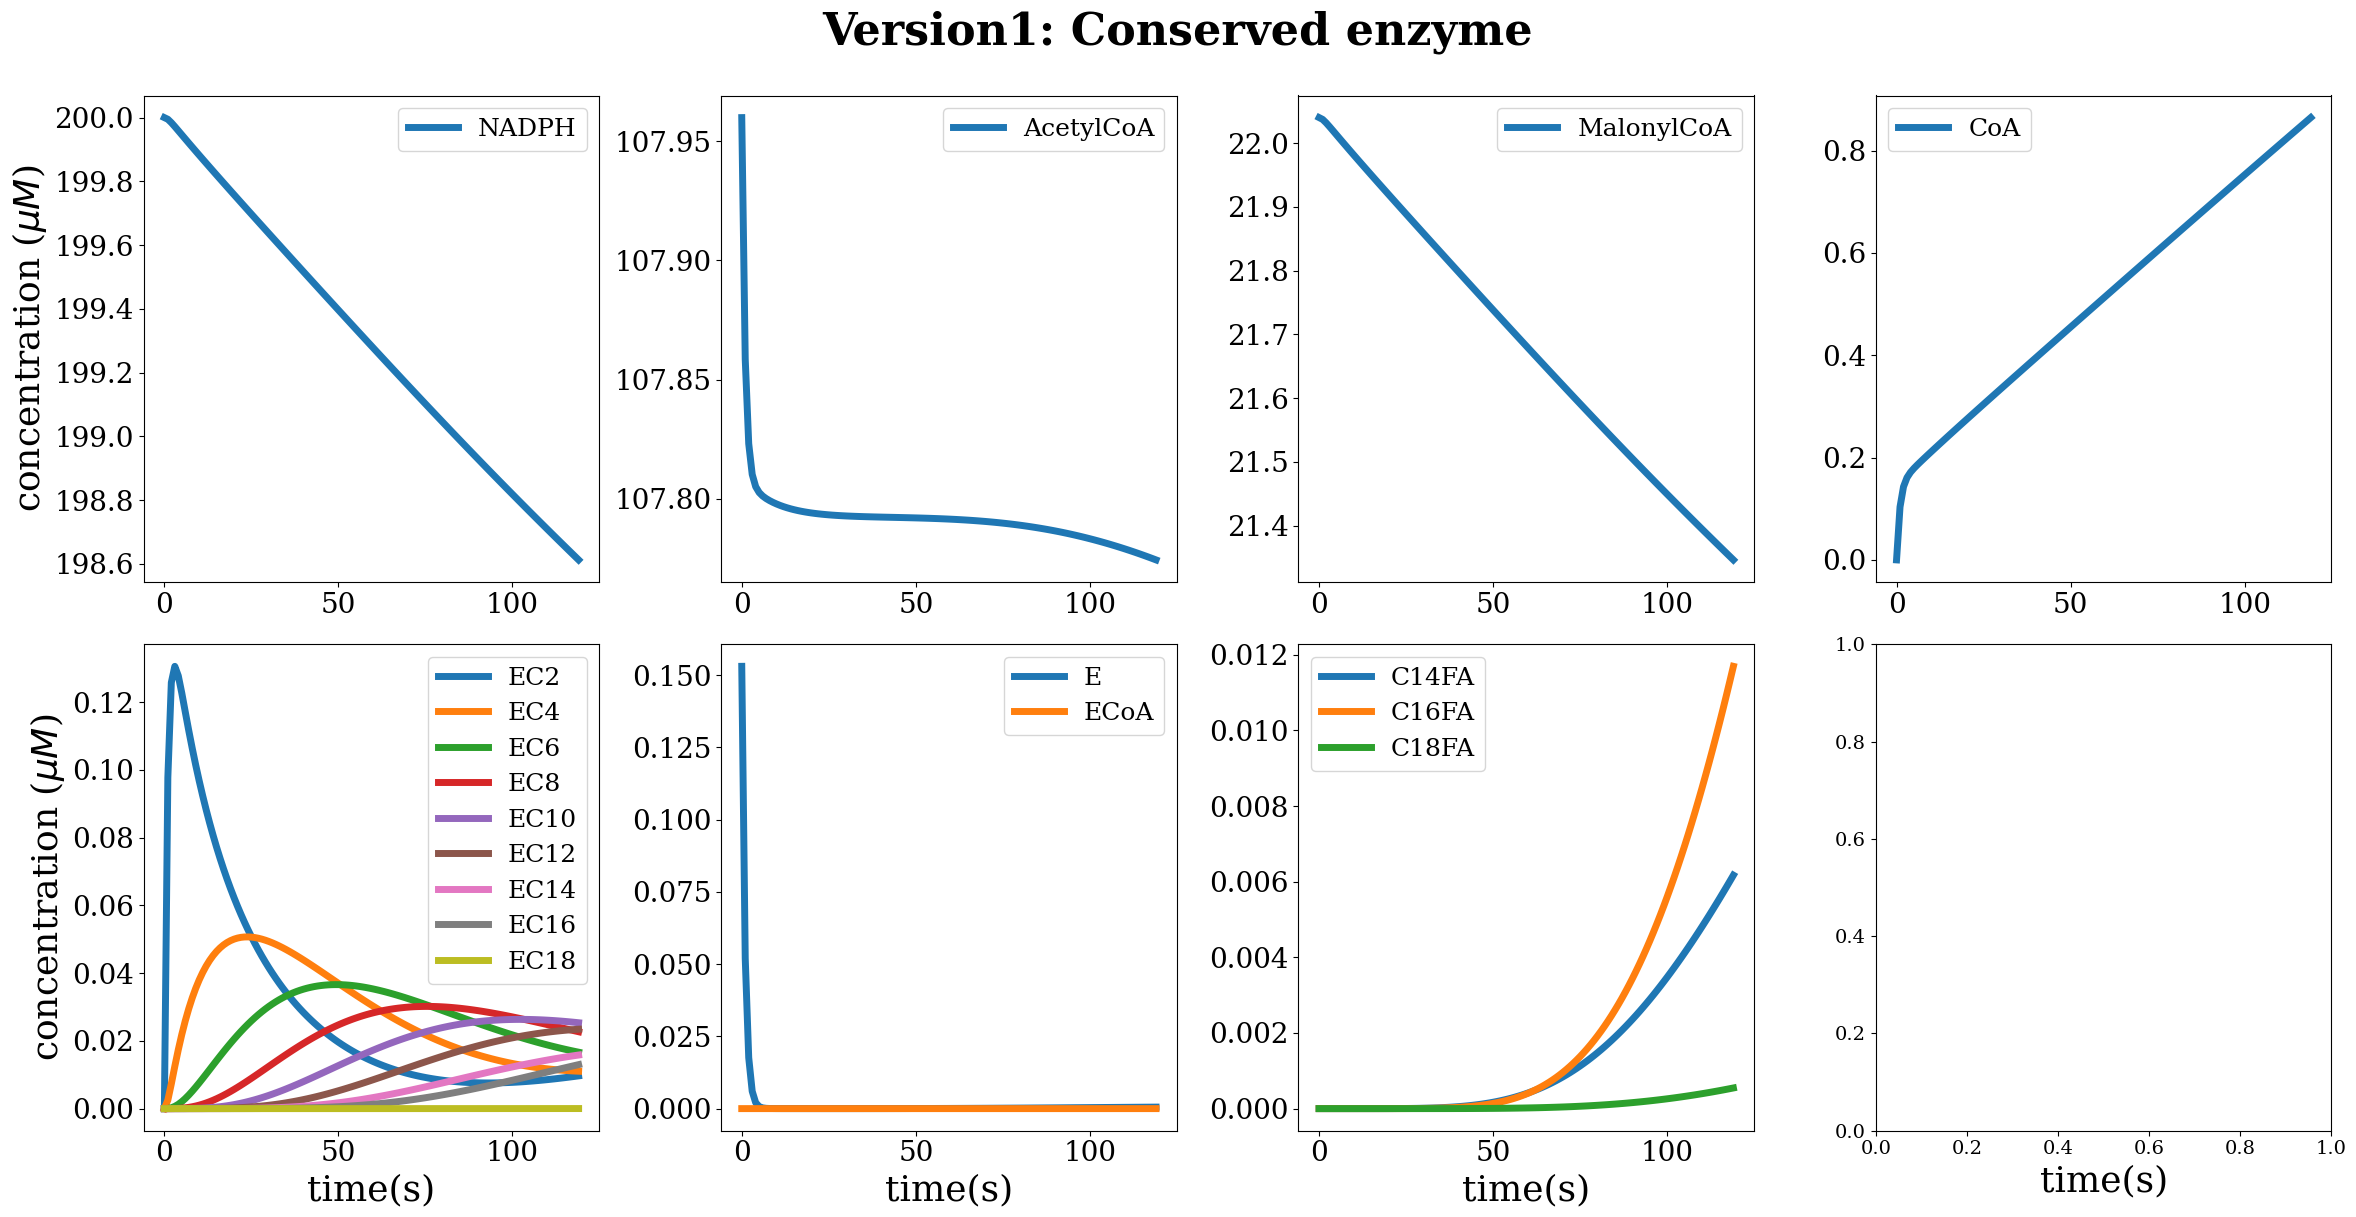

In [120]:
time_course = [
    ["NADPH"],
    ["AcetylCoA"],
    ["MalonylCoA"],
    ["CoA"],
    ["EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14", "EC16", "EC18"],
    ["E", "ECoA"],
    [
        "C14FA",
        "C16FA",
        "C18FA",
    ],
]


colors = ["#1f77b4", "orange", "green"]

fig, axs = multi_plot_time_course(
    groups=time_course,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time1,
    ncp_list=ncp_list1,
    par=par,
    compounds=compounds,
    ncols=4,
    resizer=6,
    sharey=False,
    title="Version1: Conserved enzyme",
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
plt.tick_params(axis="both", labelsize=14)
# adding data to a particular graph
# for i in range(3):
#        axs[1, 1].plot(time_initial_phase, data_initial_phase[:, i], "o", color=colors[i])

# plt.tick_params(axis="both", labelsize=14)
plt.savefig(RESULTS_DIR / "init12.pdf", dpi=300)


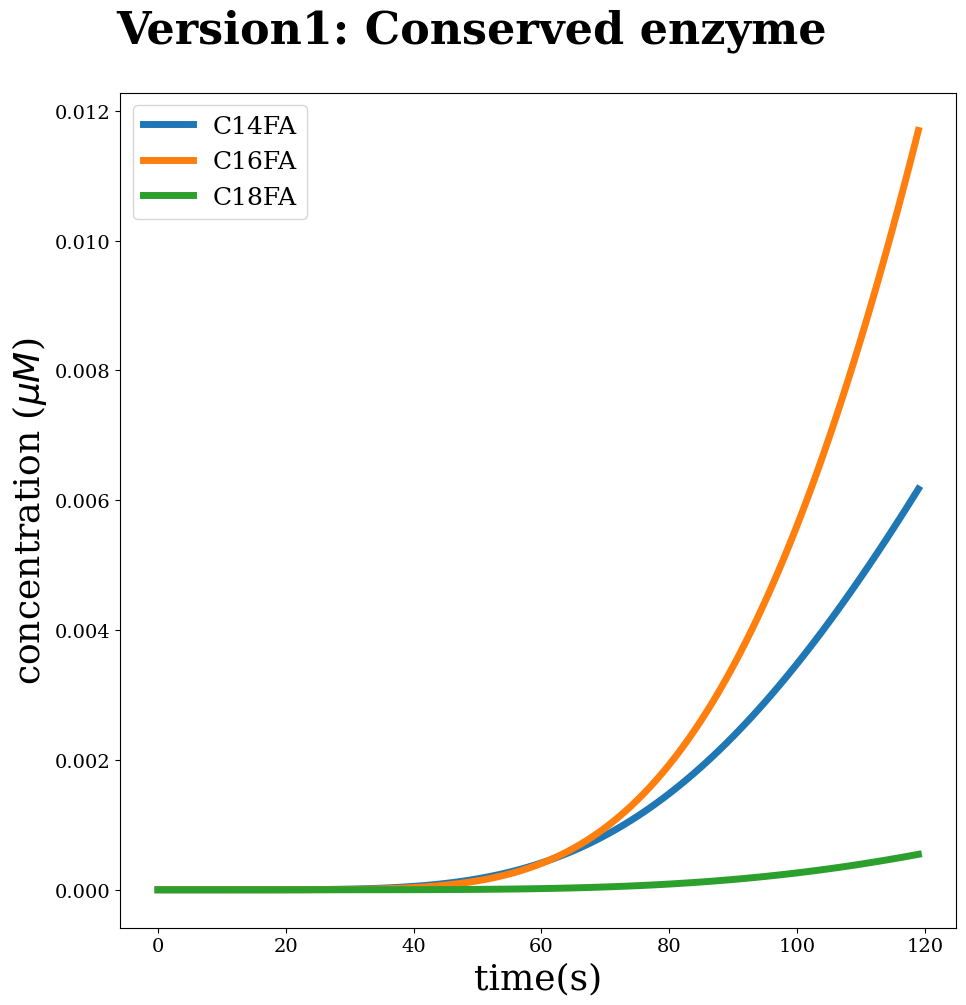

In [121]:
time_courseA = [
    [
        "C14FA",
        "C16FA",
        "C18FA",
    ],
]


colors = ["#1f77b4", "orange", "green"]

fig, axs = multi_plot_time_course(
    groups=time_courseA,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time1,
    ncp_list=ncp_list1,
    par=par,
    compounds=compounds,
    ncols=1,
    resizer=10,
    sharey=False,
    title="Version1: Conserved enzyme",
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
plt.tick_params(axis="both", labelsize=14)
# adding data to a particular graph
# for i in range(3):
#        axs[1, 1].plot(time_initial_phase, data_initial_phase[:, i], "o", color=colors[i])

# plt.tick_params(axis="both", labelsize=14)
plt.savefig(RESULTS_DIR / "init12.pdf", dpi=300)


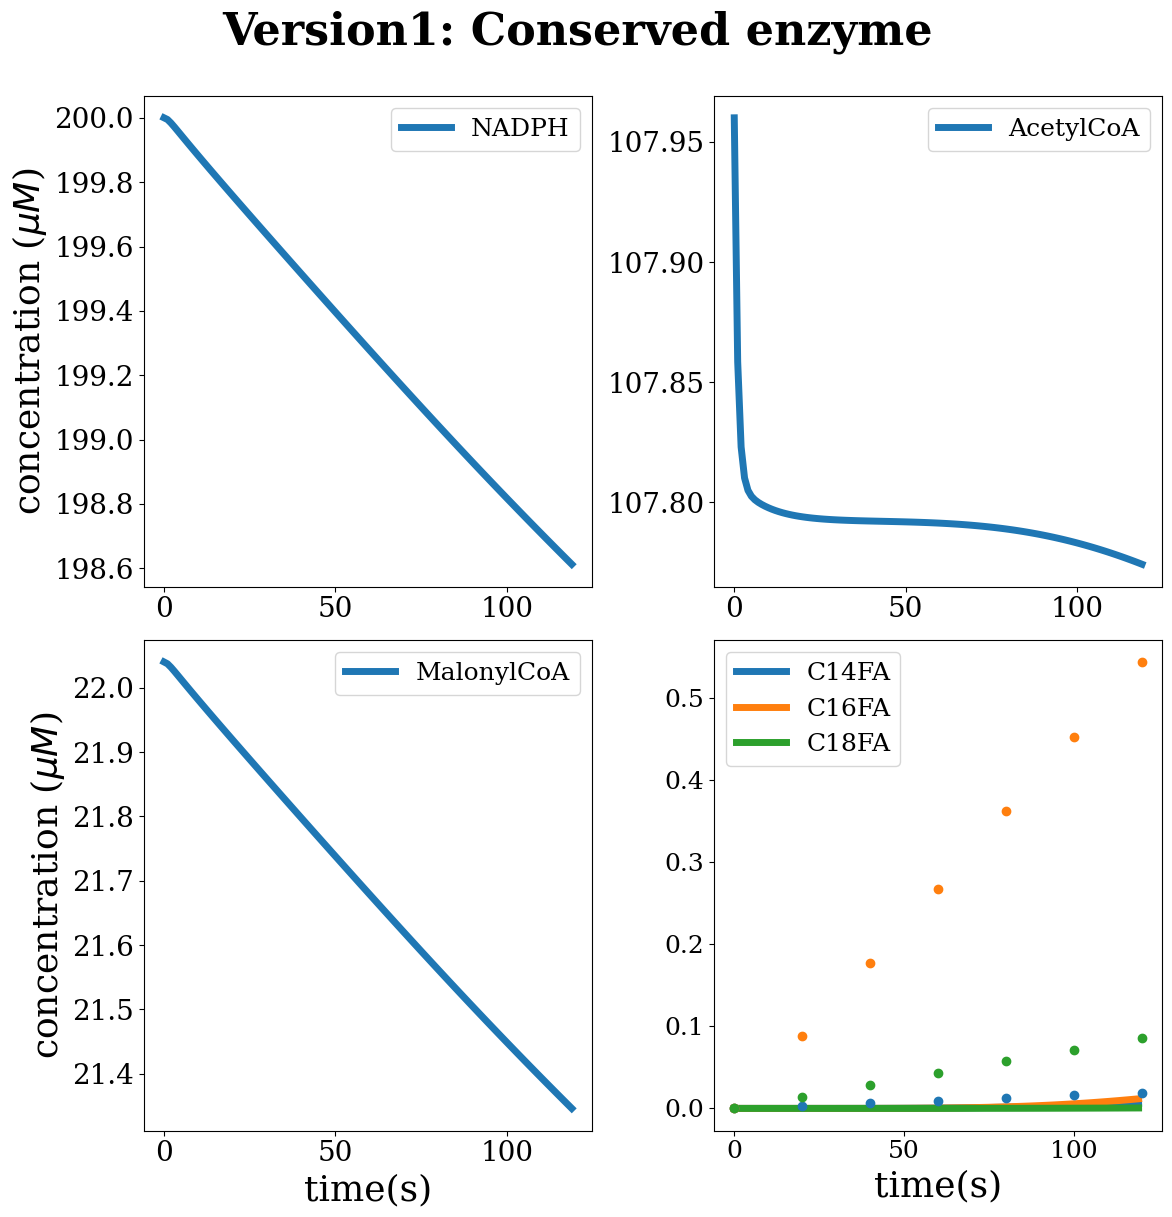

In [122]:
time_course = [
    ["NADPH"],
    ["AcetylCoA"],
    ["MalonylCoA"],
    # ["EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14", "EC16", "EC18"],
    [
        "C14FA",
        "C16FA",
        "C18FA",
    ],
]


colors = ["#1f77b4", "orange", "green"]

fig, axs = multi_plot_time_course(
    groups=time_course,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time1,
    ncp_list=ncp_list1,
    par=par,
    compounds=compounds,
    ncols=2,
    resizer=6,
    sharey=False,
    title="Version1: Conserved enzyme",
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)

# adding data to a particular graph
for i in range(3):
    axs[1, 1].plot(time_initial_phase, data_initial_phase[:, i], "o", color=cols[i])

plt.tick_params(axis="both", labelsize=18)
plt.savefig(RESULTS_DIR / "init1.pdf", dpi=300)


In [123]:
par = {
    "beta": 1e-2,
    "kappa": 1e-5,
    "delta": 3.4e-07,  
    "kd6": 0.01,
    "kd7": 0.03,  #
    "kd8": 1,
    "kf_CoA": 1e-3,
    "kb_CoA": 1e-1,
    "kf_mal": 1e-3,
    "kb_mal": 1e-1,
    "kf_acet": 1e-3,
    "kb_acet": 1e-1,
}


In [124]:
simulated_nefas = fatty_acid_of_interest(
    system,
    par=par,
    y0=y0,
    max_time=time_nefas1_simulation[-1],
    ncp_list=time_nefas1_simulation,
)


In [125]:
ncp_list3 = np.linspace(0, 100000, 100000)
max_time3 = ncp_list3[-1]


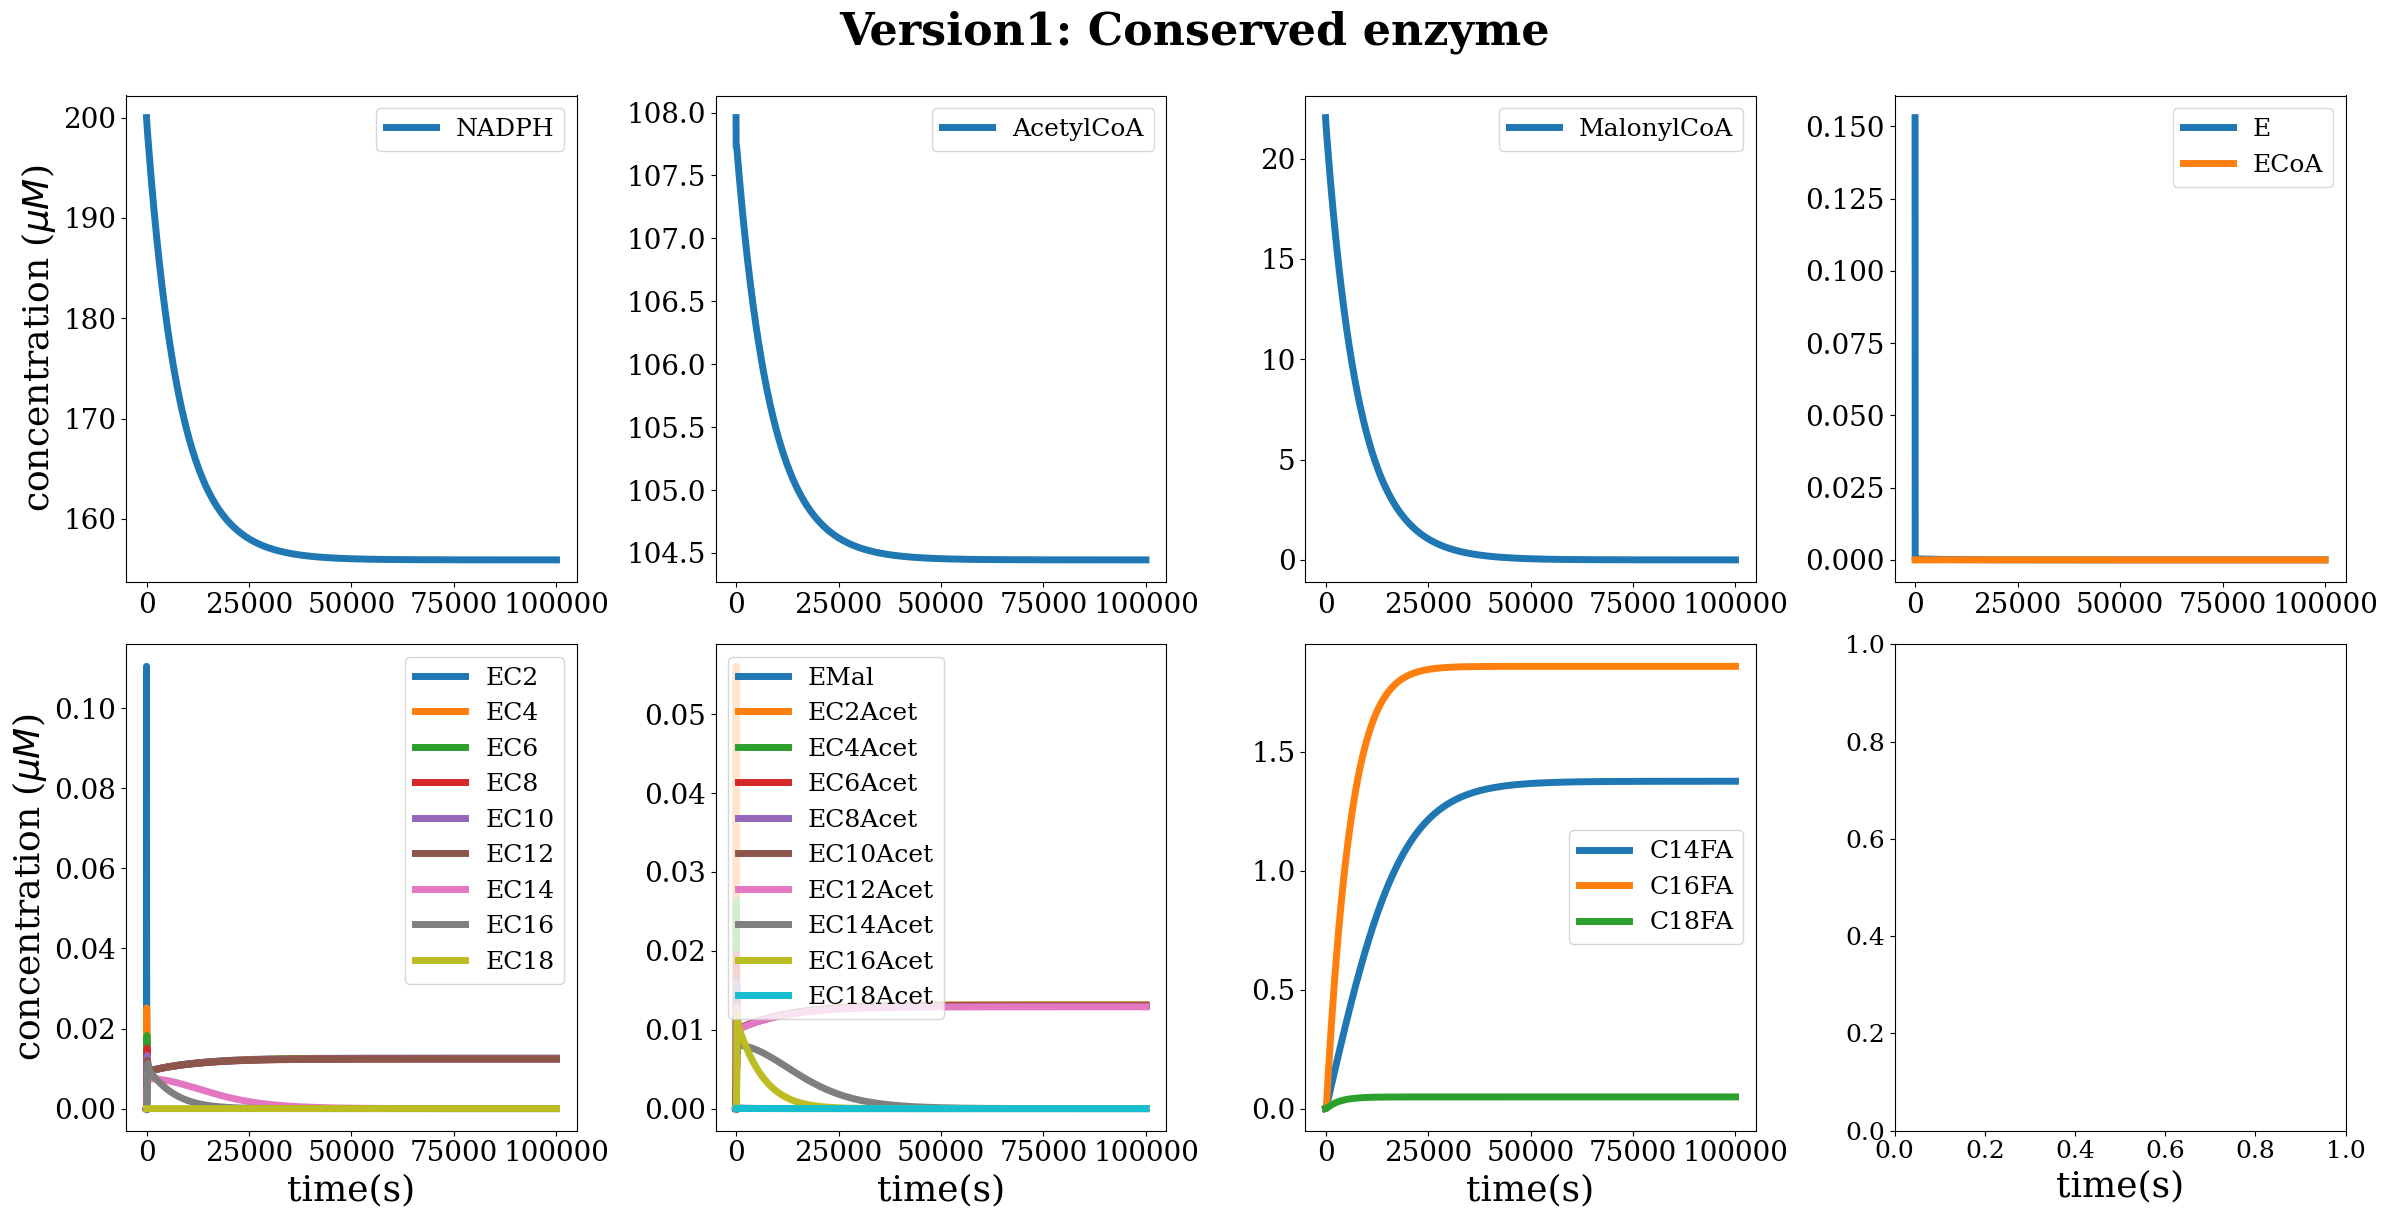

In [126]:
time_course = [
    ["NADPH"],
    ["AcetylCoA"],
    ["MalonylCoA"],
    ["E", "ECoA"],
    ["EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14", "EC16", "EC18"],
    [
        "EMal",
        "EC2Acet",
        "EC4Acet",
        "EC6Acet",
        "EC8Acet",
        "EC10Acet",
        "EC12Acet",
        "EC14Acet",
        "EC16Acet",
        "EC18Acet",
    ],
    [
        "C14FA",
        "C16FA",
        "C18FA",
    ],
]


colors = ["#1f77b4", "orange", "green"]

fig, axs = multi_plot_time_course(
    groups=time_course,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time2,
    ncp_list=ncp_list3,
    par=par,
    compounds=compounds,
    ncols=4,
    resizer=6,
    sharey=False,
    title="Version1: Conserved enzyme",
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
plt.tick_params(axis="both", labelsize=14)
# adding data to a particular graph

# axs[1, 3].plot(time_nefas1_simulation, total_nefas1, "o", color="c", linewidth=4)
# axs[1, 3].plot(time_nefas1_simulation, simulated_nefas, "-", color="m", linewidth=4)
# axs[1, 1].legend(["Data total NEFAs", "simulated"],)
plt.tick_params(axis="both", labelsize=18)
plt.savefig(RESULTS_DIR / "long_run1.pdf", dpi=300)


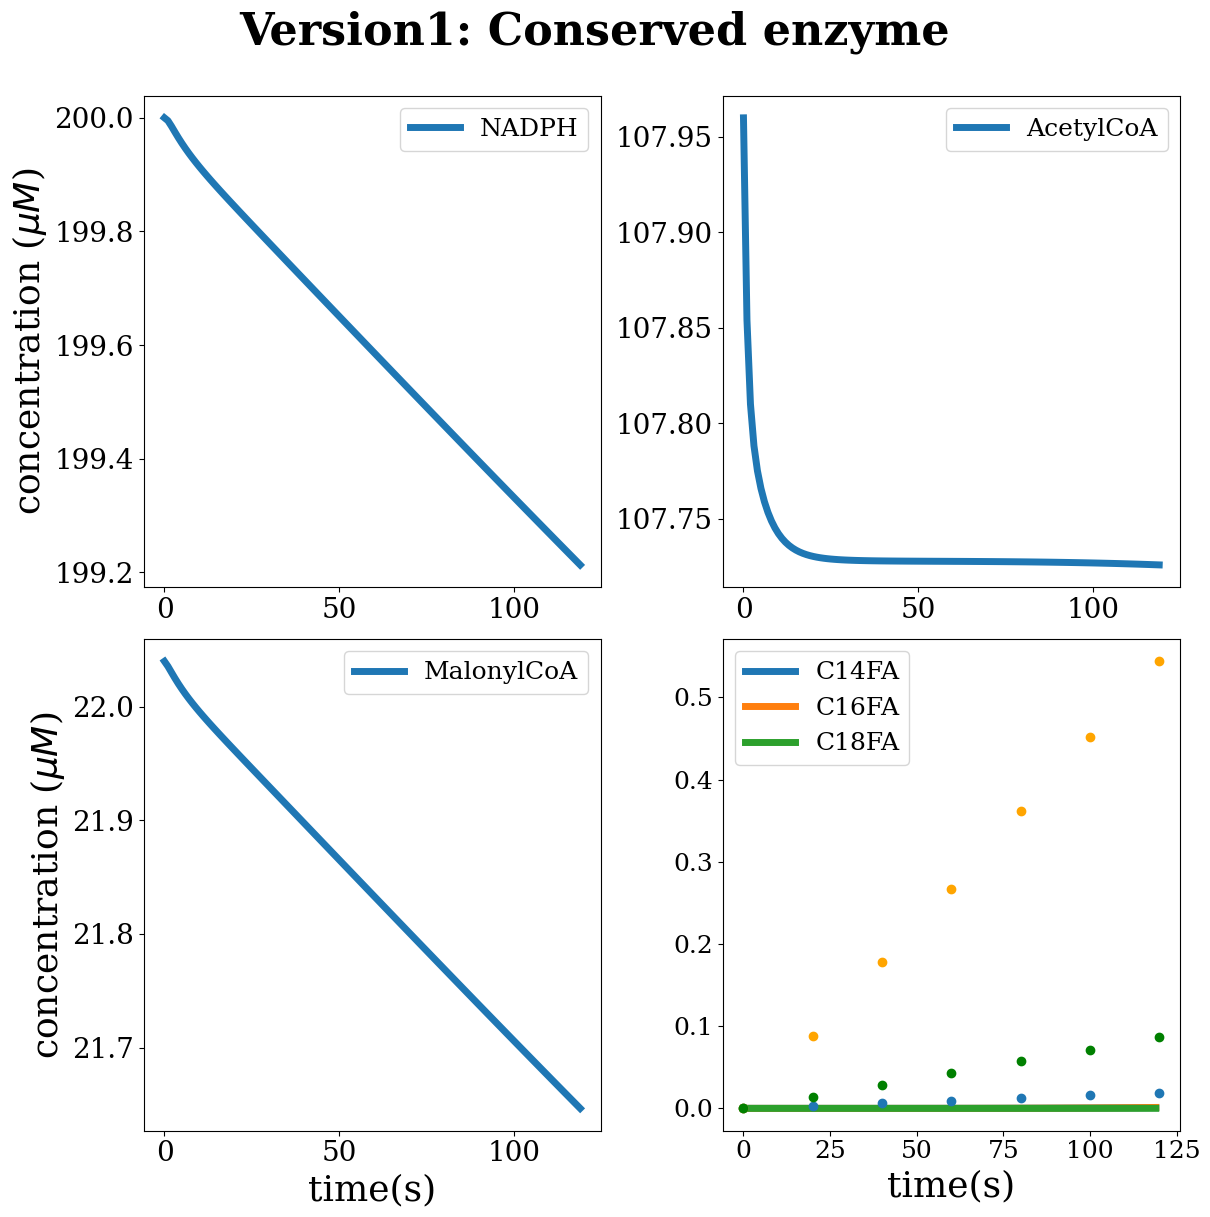

In [127]:
time_course = [
    ["NADPH"],
    ["AcetylCoA"],
    ["MalonylCoA"],
    # ["EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14", "EC16", "EC18"],
    [
        "C14FA",
        "C16FA",
        "C18FA",
    ],
]


colors = ["#1f77b4", "orange", "green"]

fig, axs = multi_plot_time_course(
    groups=time_course,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time1,
    ncp_list=ncp_list1,
    par=par,
    compounds=compounds,
    ncols=2,
    resizer=6,
    sharey=False,
    title="Version1: Conserved enzyme",
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)

# adding data to a particular graph
for i in range(3):
    axs[1, 1].plot(time_initial_phase, data_initial_phase[:, i], "o", color=colors[i])

plt.tick_params(axis="both", labelsize=18)
plt.savefig(RESULTS_DIR / "init1.pdf", dpi=300)


In [128]:
par = {
    "beta": 1e-2,
    "kappa": 1e-5,
    "delta": 3.4e-07,  #
    "kd6": 0.3,
    "kd7": 0.03,  #
    "kd8": 1,
    "kf_CoA": 2.5e-3,
    "kb_CoA": 2.5e-3,
    "kf_mal": 1e-3,
    "kb_mal": 1e-4,
    "kf_acet": 1e-3,
    "kb_acet": 1e-4,
}


## Range in which some parameters can be found

we vary the value of $\beta$ and $\kappa$ to see how the fit is sensitive to the value of these parameters.

- varying $\beta$ betwwen $1e-2$ and $1e3$, we can conclude that any value of $\beta$ in this range give a good fit. The same constat applies the value of $\kappa$ between $5e-3$ and $1e2$.
- We therefore choose the value of $\beta$ and $\kappa$ to be respectively $1e-1$ and $1e-2$




# Measure of the goodness of the fit 

In [129]:
result_model = fatty_acid_of_interest(
    system=system, par=par, y0=y0, max_time=max_time1, ncp_list=time_initial_phase
)


In [130]:
goodness_of_fit(data_initial_phase, result_model)


0.19035559912212993

In [131]:
data_initial_phase.shape
time_initial_phase.shape


(7,)

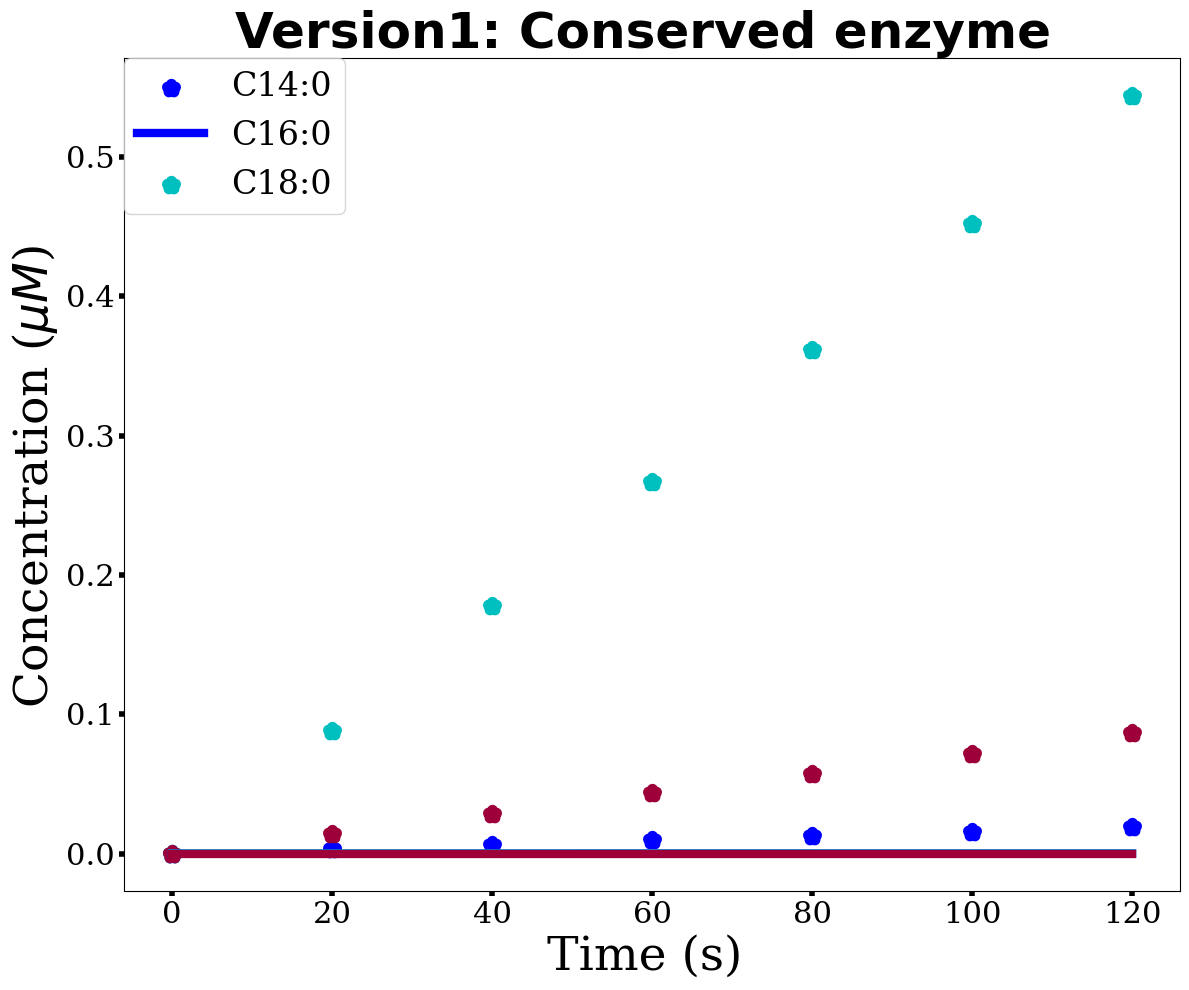

In [132]:
fig, ax = plt.subplots(figsize=(12, 10))

for i in range(3):
    ax.scatter(
        time_initial_phase,
        data_initial_phase[:, i],
        color=color[i][0],
        marker="*",
        linewidth=8,
    )
    ax.plot(time_initial_phase, result_model[:, i], color=color[i][0], linewidth=6)

# plt.plot(time1, final, '-', linewidth=2);
plt.xlabel("Time (s) ", fontsize=34)
plt.ylabel("Concentration ($\mu M$) ", fontsize=34)
plt.title(
    "Version1: Conserved enzyme ",
    fontname="Times New Roman",
    size=36,
    fontweight="bold",
)
plt.xticks(size=22)
plt.yticks(size=22)
plt.tick_params(width=4)

# plt.yscale("log")
ax.legend(
    ["C14:0", "C16:0", "C18:0"],
    loc="best",
    # bbox_to_anchor=(1.1, 1),
    borderaxespad=0,
    fontsize=24,
)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "fiting12.pdf", dpi=300, bbox_inches="tight")
plt.show()


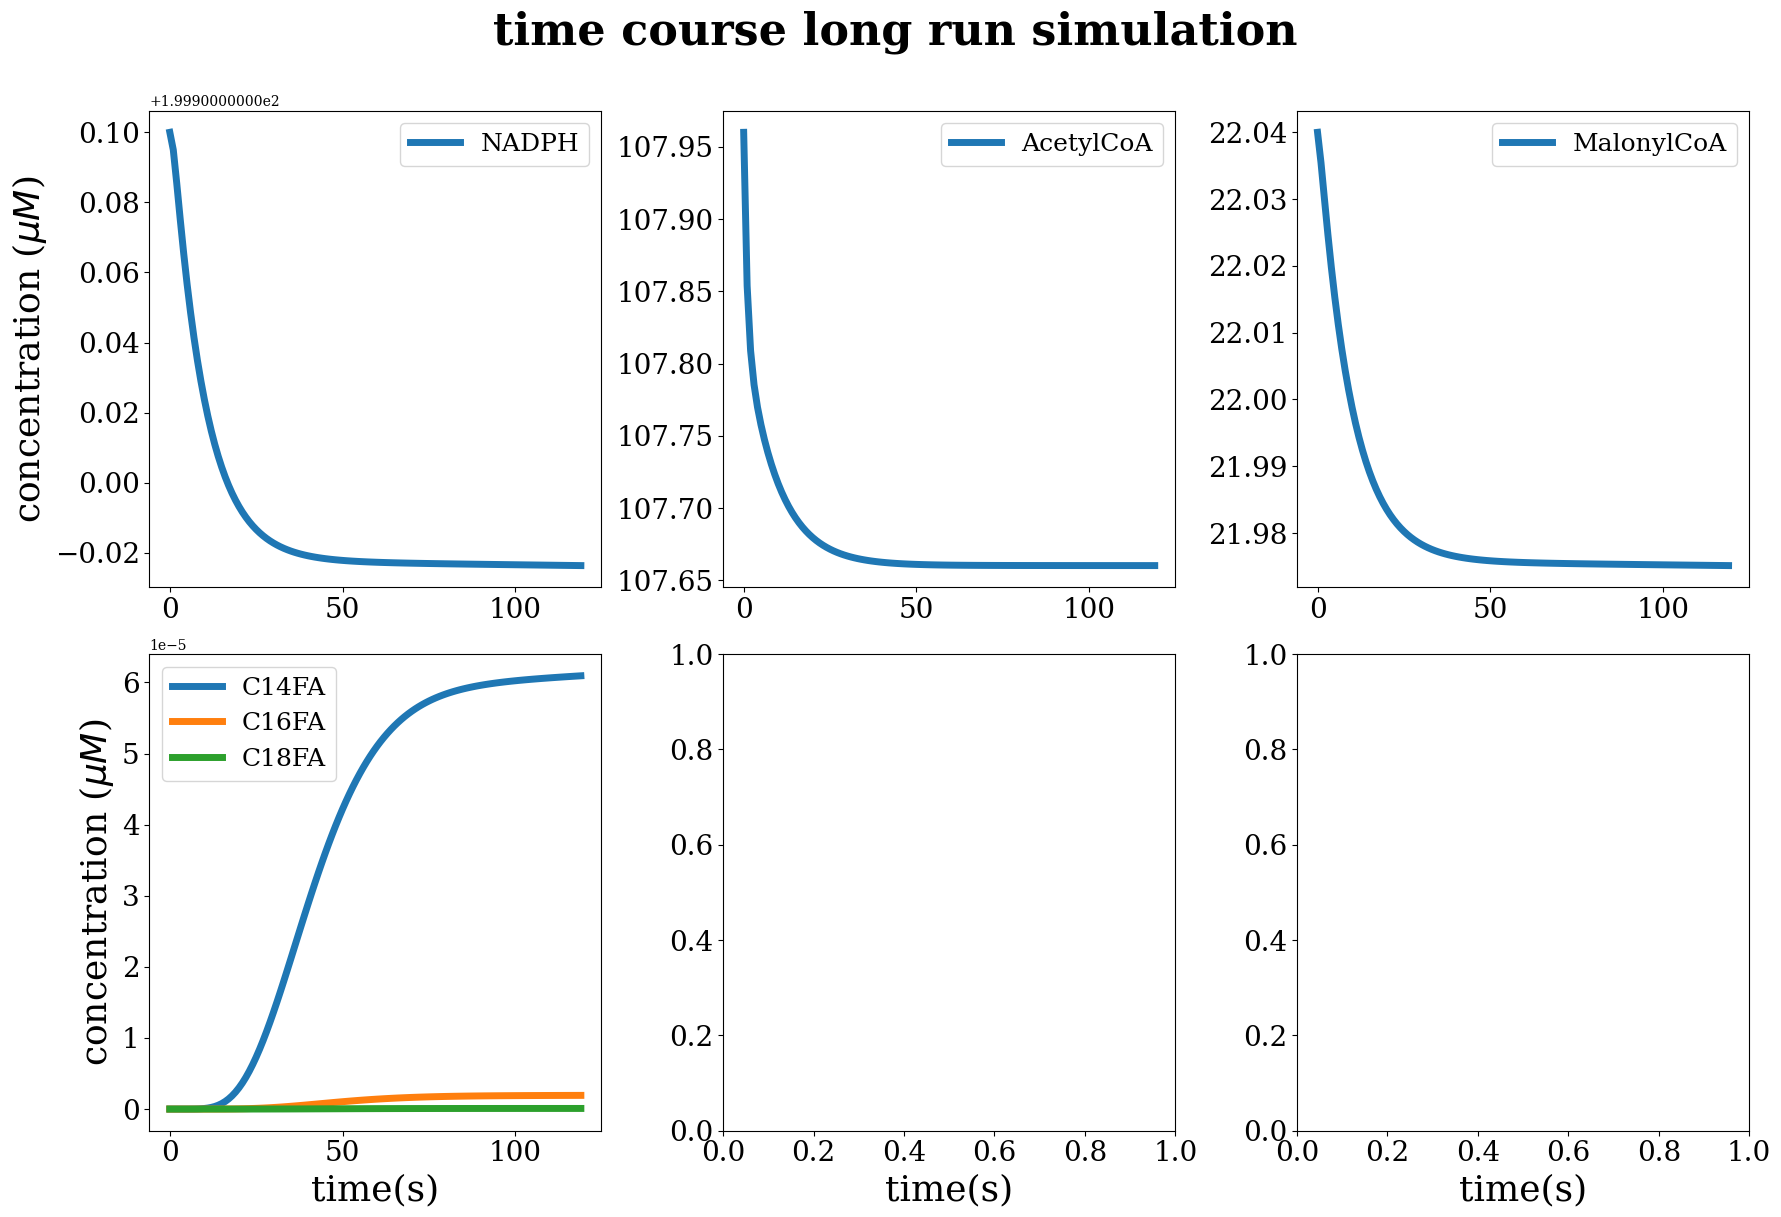

In [133]:
fig, axs = multi_plot_time_course(
    groups=time_course,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time1,
    ncp_list=ncp_list1,
    par=par,
    compounds=compounds,
    ncols=3,
    resizer=6,
    sharey=False,
    title="time course long run simulation",
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
# adding data to a particular graph
all_fatty_acids =total_long_fatty_acid(
    system, par, y0, max_time=time_initial_phase, ncp_list=ncp_list1
)

# axs[1, 2].plot(time_nefas1_simulation, total_nefas1, "o")
# axs[1, 2].plot(ncp_list2, all_fatty_acids, linewidth=4)
# axs[1, 2].legend(["Data total NEFAs", "simulated"],)

plt.savefig(RESULTS_DIR / "initial.pdf", dpi=300)


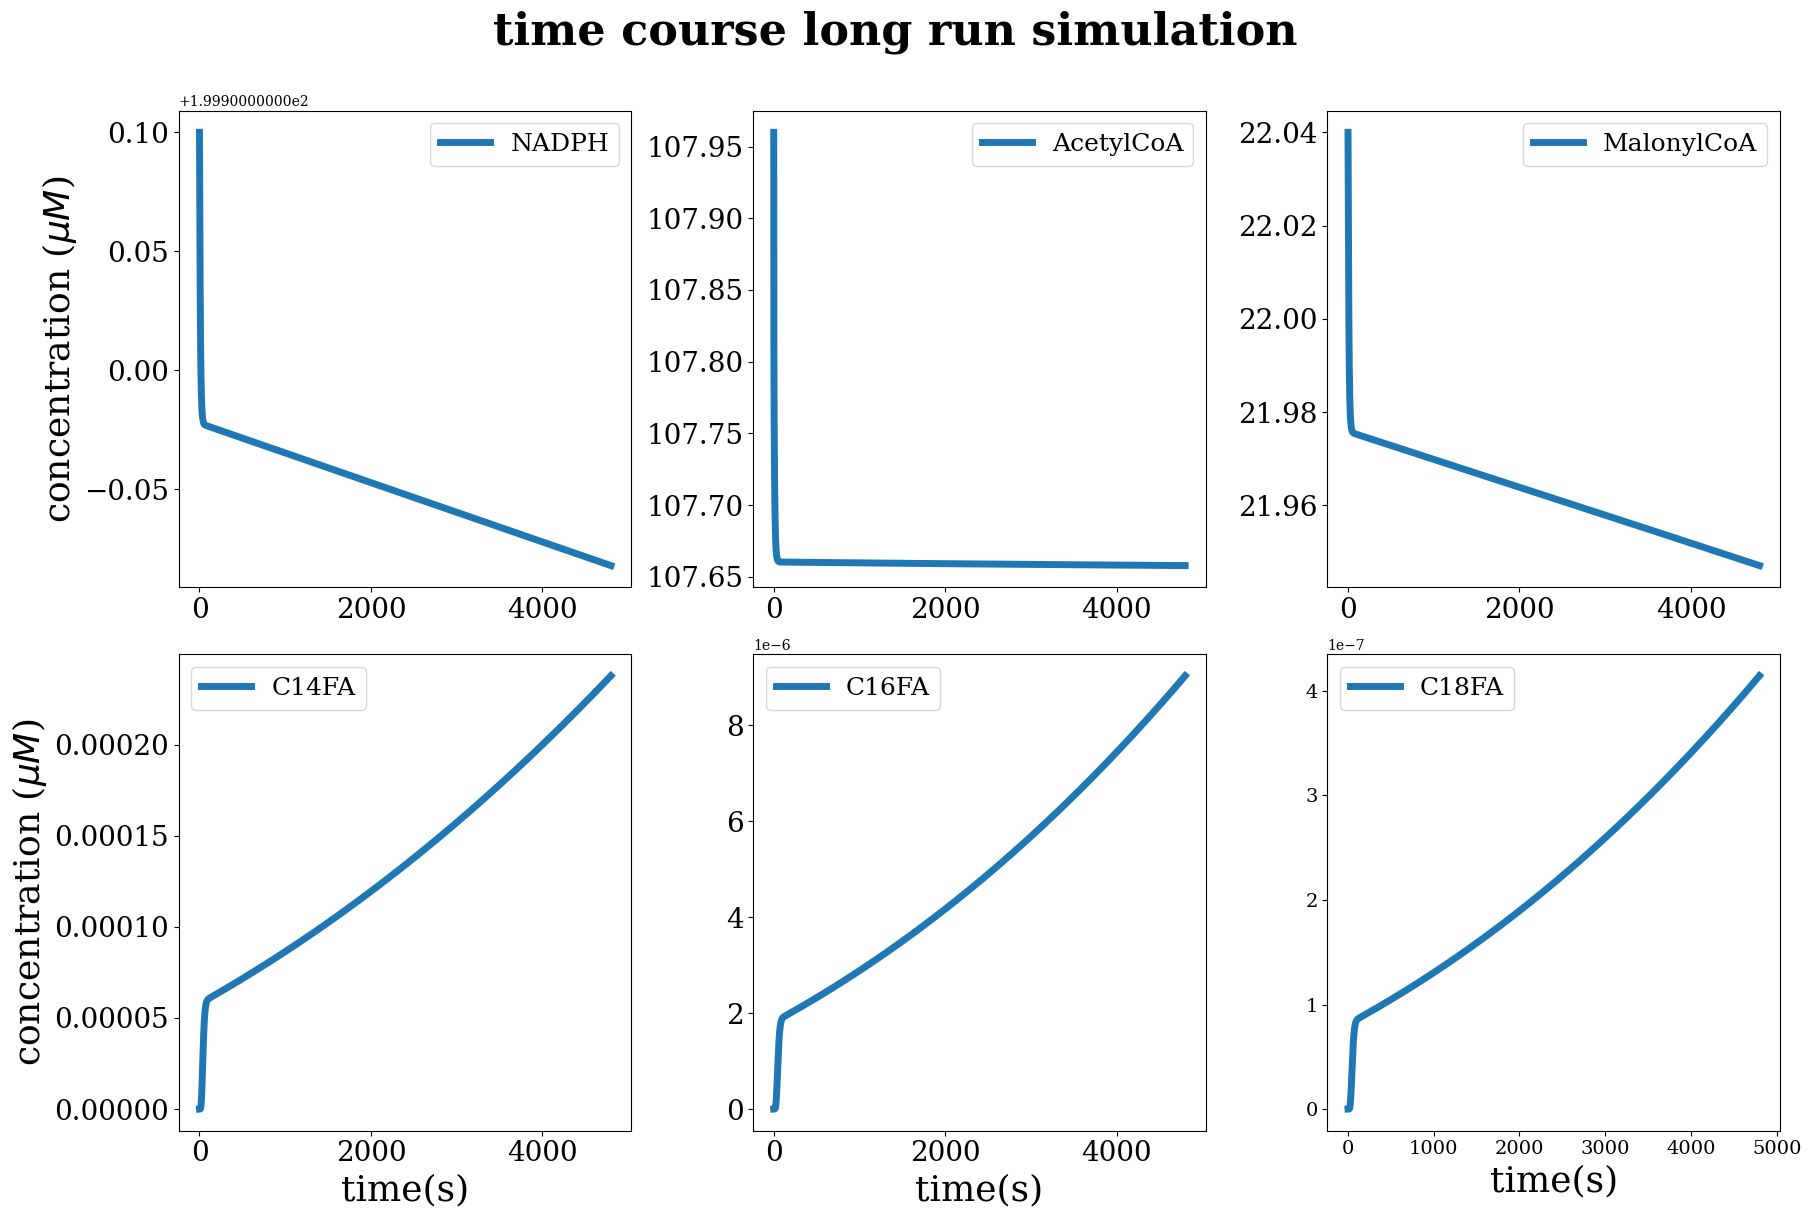

In [134]:
long_run = [
    ["NADPH"],
    ["AcetylCoA"],
    ["MalonylCoA"],
    ["C14FA"],
    ["C16FA"],
    ["C18FA"],
    # ["EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14", "EC16", "EC18"],
    # [
    #     "C14FA",
    #     "C16FA",
    #     "C18FA",
    # ],
]

fig, axs = multi_plot_time_course(
    groups=long_run,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time2,
    ncp_list=ncp_list2,
    par=par,
    compounds=compounds,
    ncols=3,
    resizer=6,
    sharey=False,
    title="time course long run simulation",
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
# adding data to a particular graph
# all_fatty_acids=fatty_acid_of_interest(system, par, y0, max_time = time_nefas1_simulation, ncp_list = ncp_list2)

# axs[1, 2].plot(time_nefas1_simulation, total_nefas1,  "o-", color=colors[i])
# axs[1, 2].plot(ncp_list2, all_fatty_acids, linewidth=4)
# axs[1, 2].legend(
#     [
#     "Data total NEFAs",
#     "simulated"
#     ],

# )
plt.tick_params(axis="both", labelsize=14)
plt.savefig(RESULTS_DIR / "long_run.pdf")


In [135]:
all_fatty_acids = total_long_fatty_acid(
    system, par, y0, max_time=time_nefas1_simulation, ncp_list=ncp_list2
)
len(all_fatty_acids)
len(ncp_list2)


4800

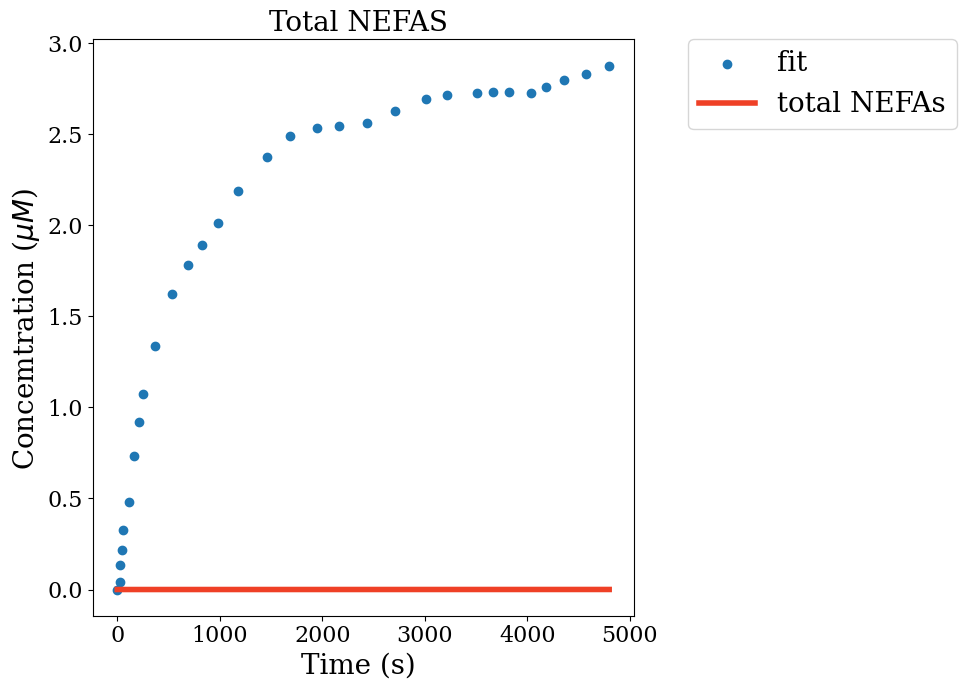

In [136]:
fig, ax = plt.subplots(figsize=(10, 7))


ax.scatter(time_nefas1_simulation, total_nefas1, marker="o")
ax.plot(ncp_list2, all_fatty_acids, color=color[6][0], linewidth=4)

# plt.plot(time1, final, '-', linewidth=3);
plt.xlabel("Time (s) ", fontsize=20)
plt.ylabel("Concemtration ($\mu M $) ", fontsize=20)
plt.title("Total NEFAS ", fontsize=20)
# plt.yscale("log")
ax.legend(
    ["fit", "total NEFAs"],
    loc="upper left",
    bbox_to_anchor=(1.1, 1),
    borderaxespad=0,
    fontsize=20,
)
plt.tick_params(axis="both", labelsize=16)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "fitting2.pdf", bbox_inches="tight")
plt.show()


## Remarks


From the above plots, we can see that the parameters chosen fit the initial phase. but for the total fatty acids produced the parametrized model equally fit the initial phase and the steady state phase (total production). However fails to capture the transient state. Additionally we can observed that right after the initial phase the production of C14 is exponential, which should not be the case. Furthermore, the three species reach the saturation quick(before 1000 sec). The combination of these two factors may explain the failure in capturing the transient phase. 

Besides the above remarks, we can see that, here the steady state is reached when the malonyl-CoA is depleted. and this happening too quick. 




### Plot time course individually 

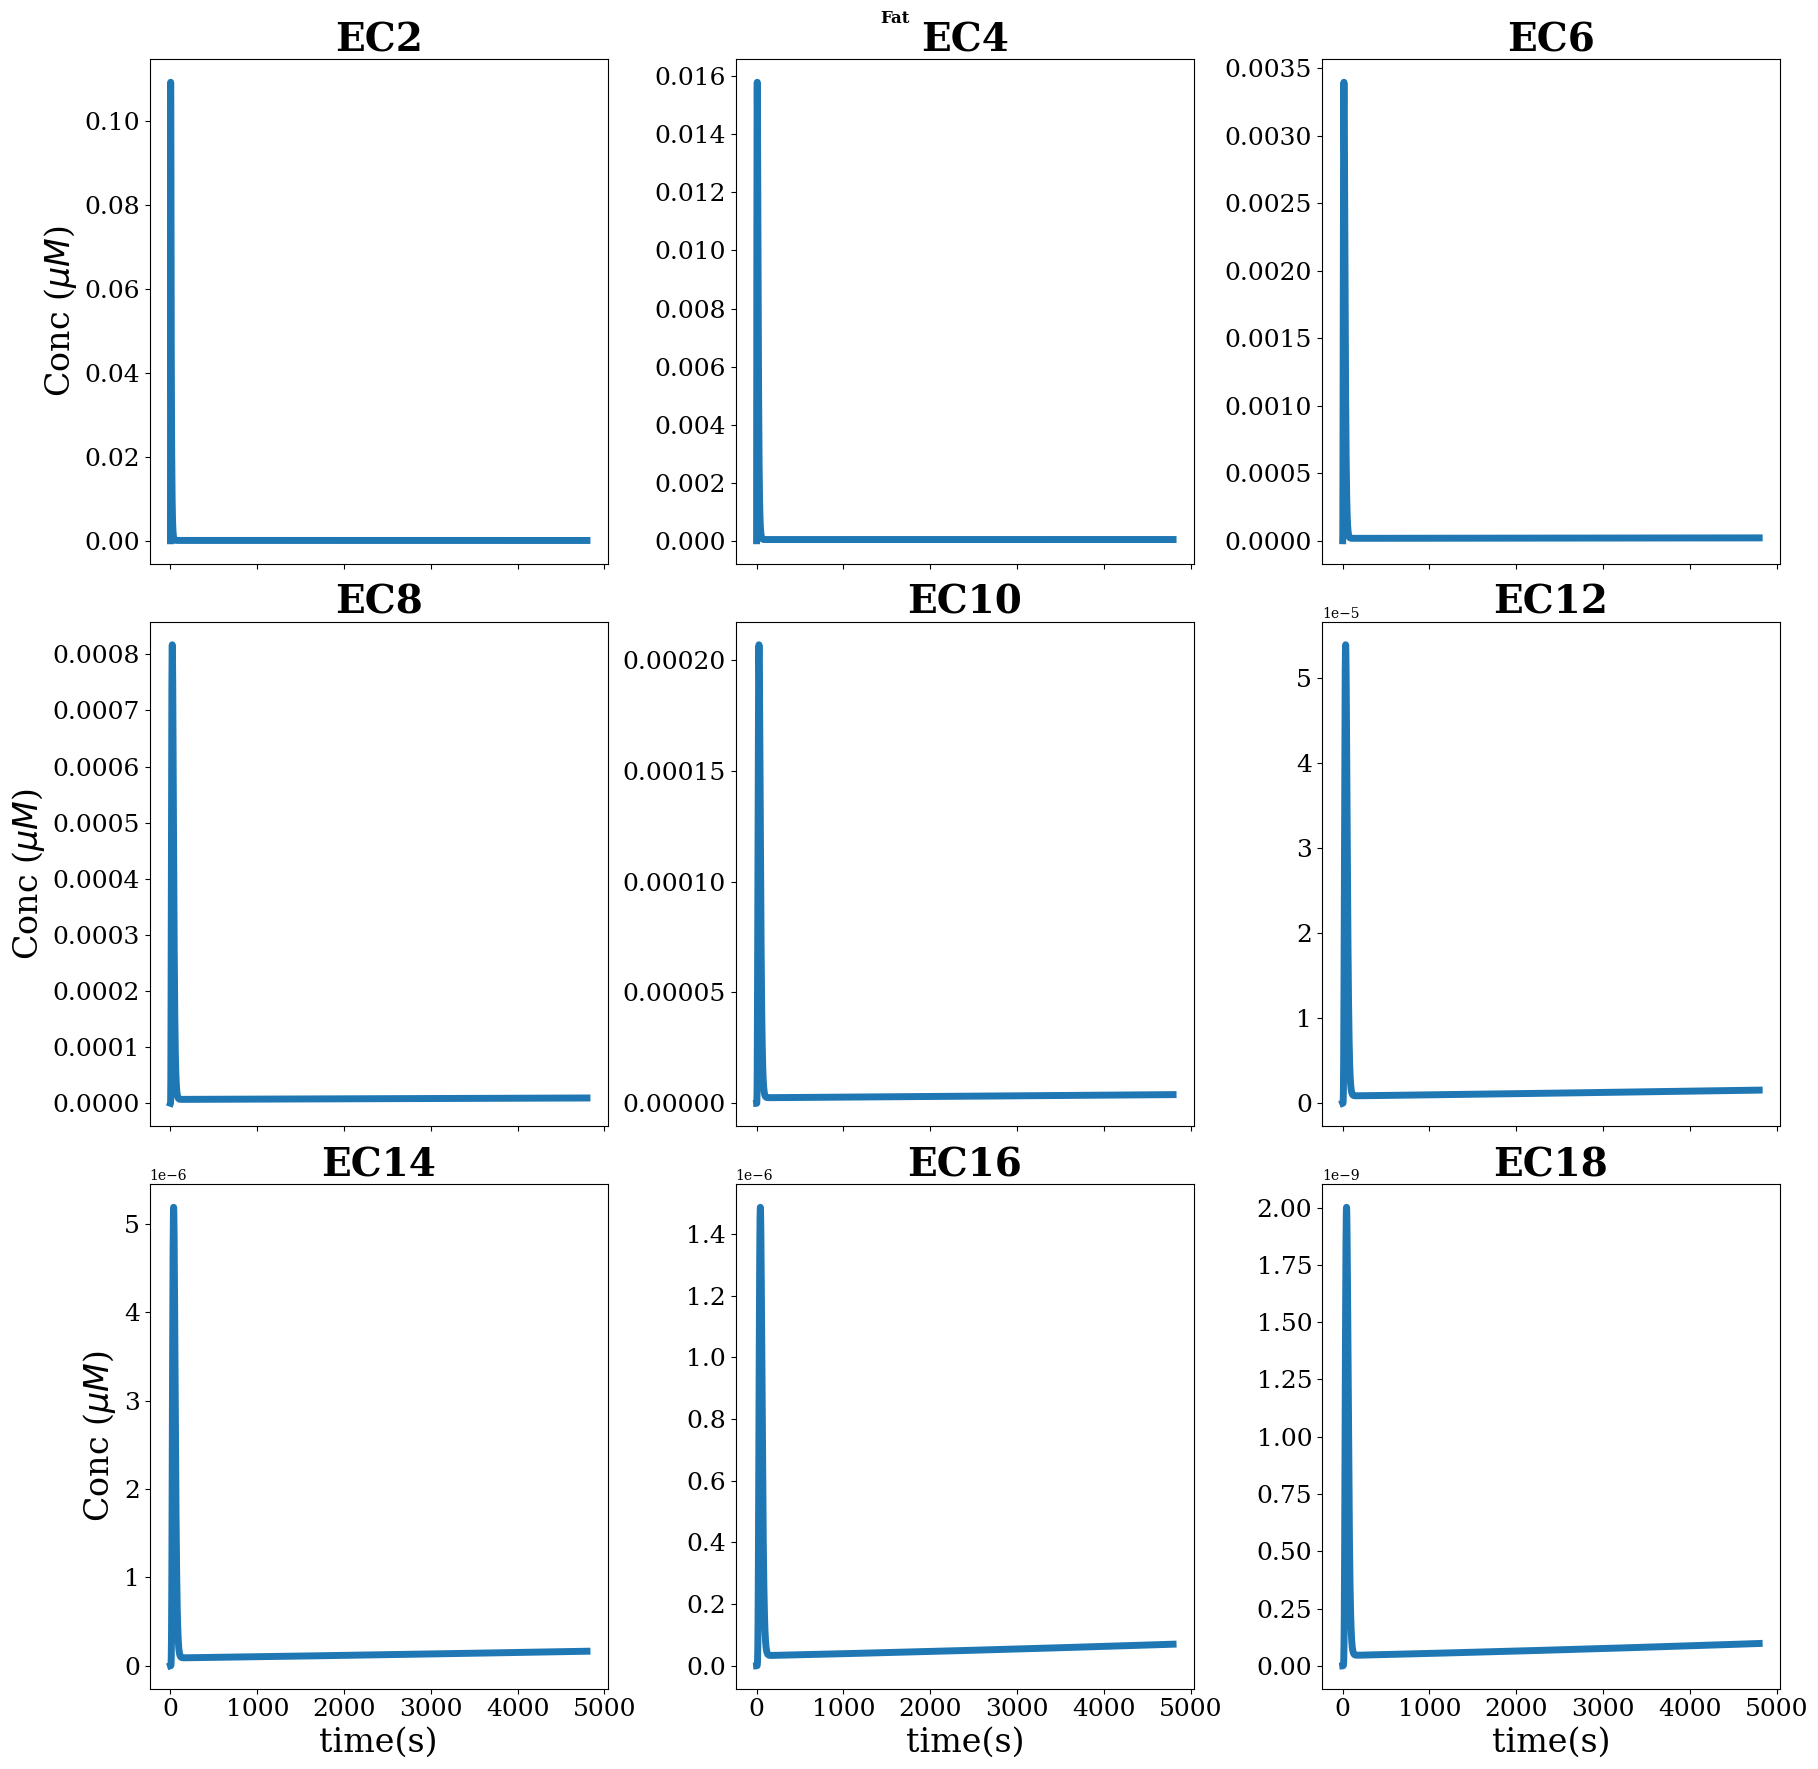

In [137]:
fat = [
    "EC2",
    "EC4",
    "EC6",
    "EC8",
    "EC10",
    "EC12",
    "EC14",
    "EC16",
    "EC18",
]
fig, axs = plot_individual_time_course(
    compounds_to_plot=fat,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time2,
    ncp_list=ncp_list2,
    par=par,
    compounds=compounds,
    ncols=3,
    resizer=6,
    sharey=False,
    title="Fat",
    xlabel="time(s)",
    ylabel="Conc ($\mu M$)",
)


In [138]:
par


{'beta': 0.01,
 'kappa': 1e-05,
 'delta': 3.4e-07,
 'kd6': 0.3,
 'kd7': 0.03,
 'kd8': 1,
 'kf_CoA': 0.0025,
 'kb_CoA': 0.0025,
 'kf_mal': 0.001,
 'kb_mal': 0.0001,
 'kf_acet': 0.001,
 'kb_acet': 0.0001}

## Remarks
The above plots justify the quasi steady state that we considered fir the initial phase. Indeed one can see that all the enzyme species are almost 0 and all the enzyme is converted to EC16 (recalling the conservation relation and the total concentration of the enzyme is 0.306 $\mu M$)

# Fitting  for the three different types of NEFAs
Giving that we calculated the value of  some parameters from experimental data, notably the value of $K_{d7}$, $\delta$ under rapid binding considerations(Indeed the substrates are in excess). We now fit others parameters to initial phase data. 

# Interpolation to have  more points 

#

In [139]:
time_interp = np.linspace(
    0, time_initial_phase[-1], 31
)  # 50 data points between 0 and 120 secs.


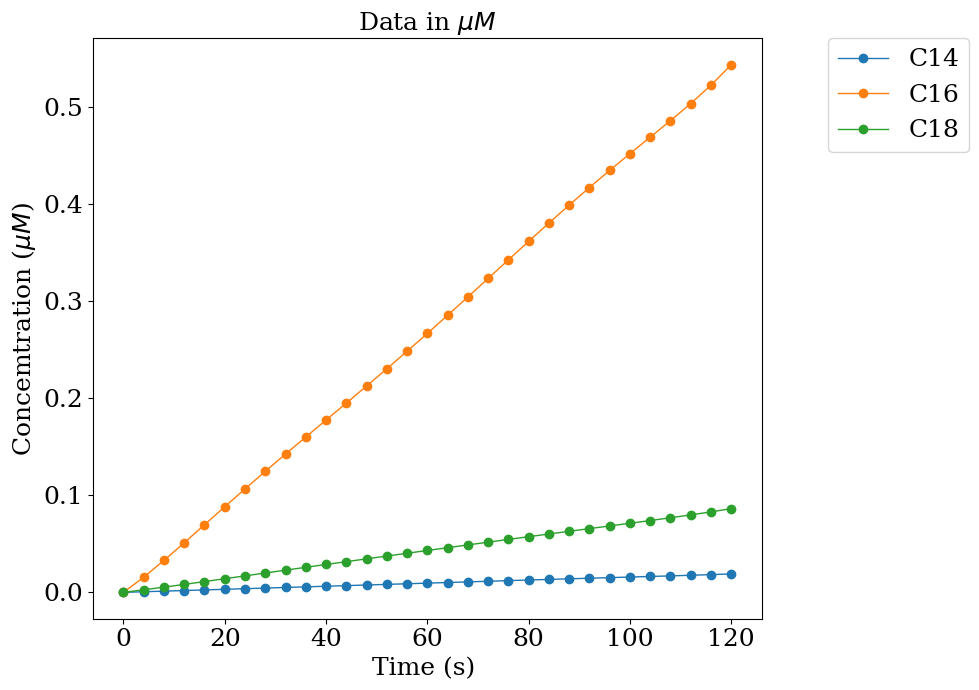

In [140]:
# use of lagrange interporlation to create more data point linearly

lagrange_interpolation_C14 = lagrange(time_initial_phase, data_initial_phase[:, 0])
lagrange_interpolation_C16 = lagrange(time_initial_phase, data_initial_phase[:, 1])
lagrange_interpolation_C18 = lagrange(time_initial_phase, data_initial_phase[:, 2])

C14_data = lagrange_interpolation_C14(time_interp)
C16_data = lagrange_interpolation_C16(time_interp)
C18_data = lagrange_interpolation_C18(time_interp)

data_to_fit = np.array([C14_data, C16_data, C18_data]).T


fig, ax = plt.subplots(figsize=(10, 7))
plt.plot(time_interp, data_to_fit, "o-", linewidth=1)

plt.xlabel("Time (s) ", fontsize=18)
plt.ylabel("Concemtration ($\mu M$) ", fontsize=18)
plt.title("Data in $\mu M$ ", fontsize=18)
plt.xticks(size=18)
plt.yticks(size=18)
# plt.yscale("log")
ax.legend(
    ["C14", "C16", "C18"],
    loc="upper left",
    bbox_to_anchor=(1.1, 1),
    borderaxespad=0,
    fontsize=18,
)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "Concentrations.pdf", bbox_inches="tight")
plt.show()


In [141]:
# residual function to be passed to lmfit library
# The function *fatty_acid_of_interest* solves the system and only returns  C14, C16 and C18.

# This residual function can oly be used for fitting the inital phase


def residual(parameters, max_time, time, data):
    # y0[1] = parameters["y0_mal"].value
    # print(y0)
    model = fatty_acid_of_interest(
        system, parameters, y0, max_time=max_time, ncp_list=time
    )
    res = (model - data).ravel()

    return res


In [142]:
par_to_fit = Parameters()
par_to_fit.add("beta", value=1e-1, min=0, max=1)
par_to_fit.add("kappa", value=1e-3, min=0)
par_to_fit.add(
    "delta",
    value=1.5e-06,
    min=0,
)
# par_to_fit.add("kd1", value=0, min=0)
# par_to_fit.add("kd2", value=0, min=0)
# par_to_fit.add("kd3", value=0, min=0)
# par_to_fit.add("kd4", value=0, min=0)
# par_to_fit.add("kd5", value=0.0, min=0)
par_to_fit.add(
    "kd6",
    value=1,
    min=0,
)
par_to_fit.add("kd7", value=0.029, vary =False)
par_to_fit.add("kd8", value=1, min=0)
par_to_fit.add("kf_CoA", value=1e-2,min =0)
par_to_fit.add("kb_CoA", value=1e-3,min =0)
par_to_fit.add("kf_mal", value=1e-3, min=0, max =1e-4)
par_to_fit.add("kb_mal", value=1e-1, min=0)
par_to_fit.add("kf_acet", value=1e-3, min=0)
par_to_fit.add("kb_acet", value=1e-1, min=0)





In [143]:
result_topolska = minimize(
    residual,
    params=par_to_fit,
    args=(time_interp[-1], time_interp, data_to_fit),
    method="leastsq",
)


In [149]:
final = data_to_fit + result_topolska.residual.reshape(data_to_fit.shape)
final.shape


(31, 3)

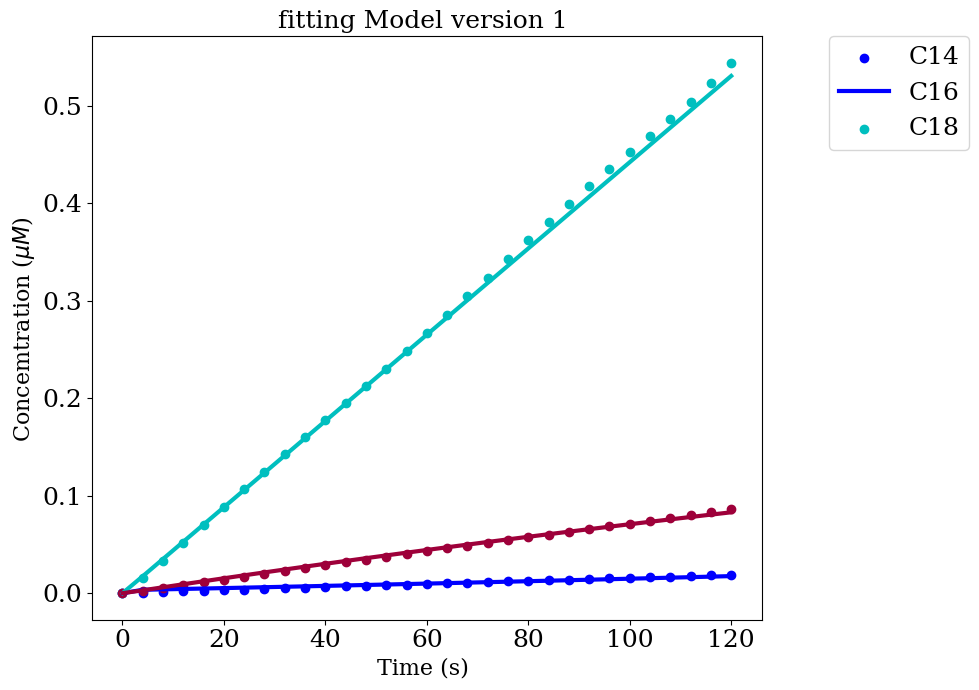

In [150]:
fig, ax = plt.subplots(figsize=(10, 7))

for i in range(3):
    ax.scatter(time_interp, data_to_fit[:, i], color=color[i][0], marker="o")
    ax.plot(time_interp, final[:, i], color=color[i][0], linewidth=3)

# plt.plot(time1, final, '-', linewidth=2);
plt.xlabel("Time (s) ", fontsize=16)
plt.ylabel("Concemtration ($\mu M$) ", fontsize=16)
plt.title("fitting Model version 1 ", fontsize=18)
plt.xticks(size=18)
plt.yticks(size=18)
#plt.yscale("log")
ax.legend(
    ["C14", "C16", "C18"],
    loc="upper left",
    bbox_to_anchor=(1.1, 1),
    borderaxespad=0,
    fontsize=18,
)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "Concentrations.pdf", bbox_inches="tight")
plt.show()


In [151]:
result_topolska


In [152]:
par_fit_intial_phase = dict(result_topolska.params.valuesdict())


## Remark 
The result of the fitting confirms the value of $k_{7}$ and that we can keep the precedent value of $\kappa$ . Furthermore it shows that the the value of $k_{d6}$ and $k_{d8}$  can be fixed in the large range. 

kd6:     171.519211 +/- 44331.2201 (25846.21%) (init = 1)

kd7:     0.01476275 +/- 8.0771e-05 (0.55%) (init = 0.014)

kd8:     1491.05791 +/- 802377.302 (53812.62%) (init = 1)

Therefore the new parameters values that are alrealdy validated are 

$\beta = 0.1$,  $\kappa = 1e-2$, $\delta =2.9e-07 $, 
 




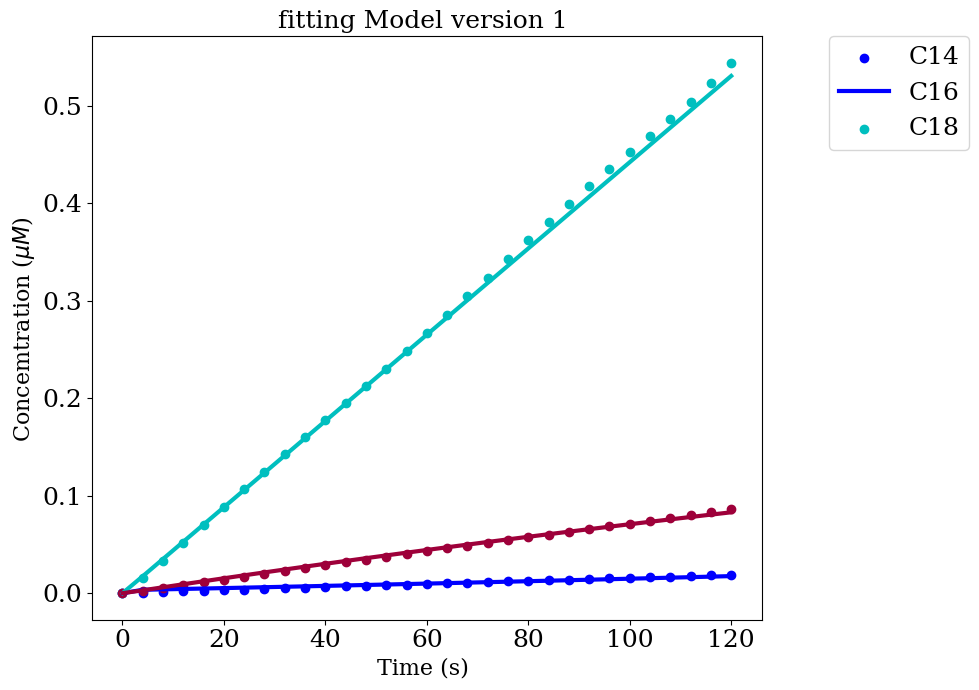

In [153]:
# plotting the results of the simulation


fig, ax = plt.subplots(figsize=(10, 7))

for i in range(3):
    ax.scatter(time_interp, data_to_fit[:, i], color=color[i][0], marker="o")
    ax.plot(time_interp, final[:, i], color=color[i][0], linewidth=3)

# plt.plot(time1, final, '-', linewidth=2);
plt.xlabel("Time (s) ", fontsize=16)
plt.ylabel("Concemtration ($\mu M$) ", fontsize=16)
plt.title("fitting Model version 1 ", fontsize=18)
plt.xticks(size=18)
plt.yticks(size=18)
# plt.yscale("log")
ax.legend(
    ["C14", "C16", "C18"],
    loc="upper left",
    bbox_to_anchor=(1.1, 1),
    borderaxespad=0,
    fontsize=18,
)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "Concentrations.pdf", bbox_inches="tight")
plt.show()


###  Simulate for a long run the type of fatty acids produce with the Parameters obtained from fitting of the intial phase 

This is to see how the parameters from the initail phase impact the long run simulation 

In [154]:
nefas_fitting = fatty_acid_of_interest(
    system, par_fit_intial_phase, y0, max_time=max_time2, ncp_list=ncp_list2
)


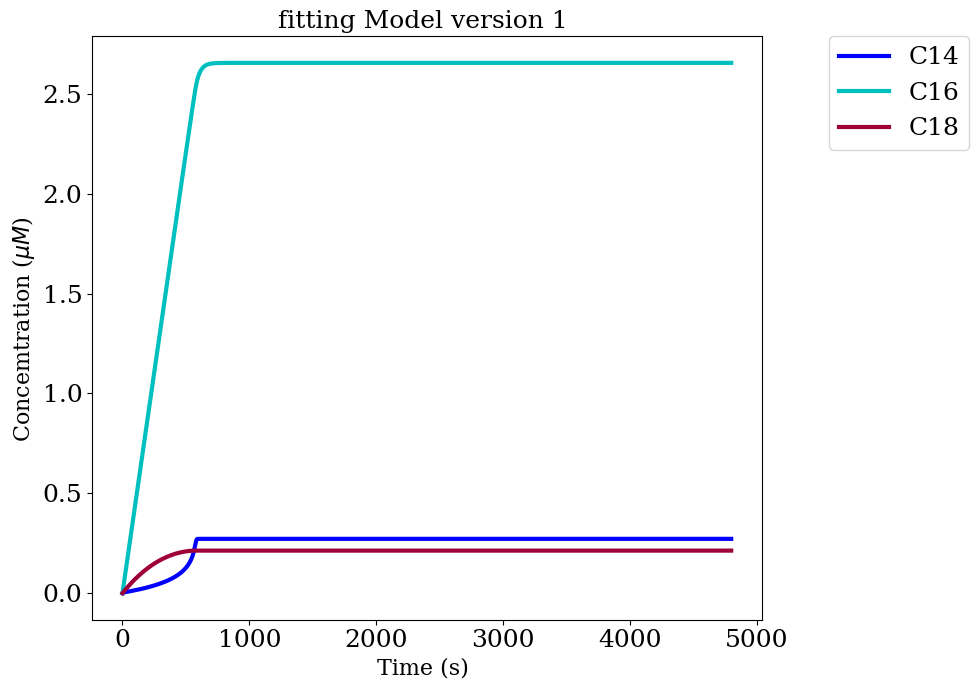

In [155]:
fig, ax = plt.subplots(figsize=(10, 7))
for i in range(3):
    ax.plot(ncp_list2, nefas_fitting[:, i], color=color[i][0], linewidth=3)

# plt.plot(time1, final, '-', linewidth=2);
plt.xlabel("Time (s) ", fontsize=16)
plt.ylabel("Concemtration ($\mu M$) ", fontsize=16)
plt.title("fitting Model version 1 ", fontsize=18)
plt.xticks(size=18)
plt.yticks(size=18)
# plt.yscale("log")
ax.legend(
    ["C14", "C16", "C18"],
    loc="upper left",
    bbox_to_anchor=(1.1, 1),
    borderaxespad=0,
    fontsize=18,
)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "Concentrations.pdf", bbox_inches="tight")
plt.show()


The parameters value of the initial phase fails to reproduce the full time course. Furthermore we can see an expected qualitative behavior on the time course of  C14:0 and the total production of C14:0 is greater that the one of C18:0. 

In conclusion the initial phase parameters fail to capture the transient phase and the steady state dynamics 


###  simulate  total NEFAs with parameters from initial phase and compare to total NEFAs data

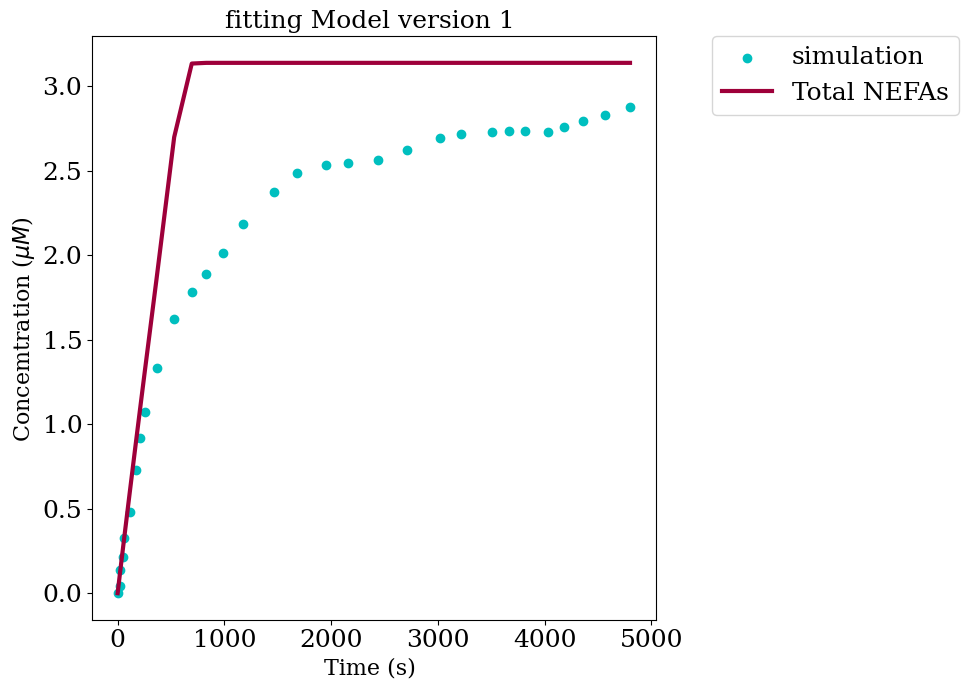

In [156]:
tot2 = total_long_fatty_acid(
    system,
    par_fit_intial_phase,
    y0,
    max_time=time_nefas1_simulation[-1],
    ncp_list=time_nefas1_simulation,
)
fig, ax = plt.subplots(figsize=(10, 7))


ax.scatter(time_nefas1_simulation, total_nefas1, color=color[1][0], marker="o")
ax.plot(time_nefas1_simulation, tot2, color=color[2][0], linewidth=3)

plt.xlabel("Time (s) ", fontsize=16)
plt.ylabel("Concemtration ($\mu M$) ", fontsize=16)
plt.title("fitting Model version 1 ", fontsize=18)
plt.xticks(size=18)
plt.yticks(size=18)
ax.legend(
    ["simulation", "Total NEFAs"],
    loc="upper left",
    bbox_to_anchor=(1.1, 1),
    borderaxespad=0,
    fontsize=18,
)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "Concentrations.pdf", bbox_inches="tight")
plt.show()


In [157]:
topolska_long_run_data_df = pd.DataFrame(
    {
        "time": time_nefas1_simulation,
        "C14:0": topolska_long_run_data[:, 0],
        "C16:0": topolska_long_run_data[:, 1],
        "C18:0": topolska_long_run_data[:, 2],
    }
)
topolska_long_run_data_df


,time,C14:0,C16:0,C18:0
0,0.00,0.000000,0.000000,0.000000
1,25.00,0.000519,0.034571,0.004840
2,25.50,0.001780,0.118643,0.016610
3,45.70,0.002818,0.187857,0.026300
4,60.00,0.004232,0.282143,0.039500
5,111.60,0.006228,0.415214,0.058130
6,167.47,0.009491,0.632714,0.088580
7,208.12,0.011938,0.795857,0.111420
8,253.50,0.013939,0.929286,0.130100
9,364.20,0.017351,1.156714,0.161940


The initial phase parameter is unable to reproduce the total concentration of NEFAs.

### Fitting the total fatty acids for the long run time 

In [158]:
par_total = Parameters()
par_total.add("beta", value=par_fit_intial_phase["beta"], vary=False)
par_total.add("kappa", value=par_fit_intial_phase["kappa"], vary=False)
par_total.add(
    "delta",
    value=par_fit_intial_phase["delta"],
    vary=False,
)
# par_total.add("kd1", value=0, vary=False)
# par_total.add("kd2", value=0, vary=False)
# par_total.add("kd3", value=0, vary=False)
# par_total.add("kd4", value=0, vary=False)
# par_total.add("kd5", value=0.0, vary=False)
par_total.add("kd6", value=par_fit_intial_phase["kd6"], vary=False)
par_total.add("kd7", value=par_fit_intial_phase["kd7"], min=0)
par_total.add("kd8", value=par_fit_intial_phase["kd8"], vary=False)
par_total.add("kf_CoA", value=1e-2, min=0)
par_total.add("kb_CoA", value=1e-1, min=0)
par_total.add("kf_mal", value=par_fit_intial_phase["kf_mal"], min=0)
par_total.add("kb_mal", value=par_fit_intial_phase["kb_mal"], min=0)
par_total.add("kf_acet", value=par_fit_intial_phase["kf_acet"], min=0)
par_total.add("kb_acet", value=par_fit_intial_phase["kb_acet"], min=0)


In [159]:
def residual_NEFA(parameters, max_time, time, data):
    # y0[1] = parameters["y0_mal"].value
    # print(y0)
    model = fatty_acid_of_interest(
        system, parameters, y0, max_time=max_time, ncp_list=time
    )
    res = (model - data).ravel()
    return res


In [160]:
result2 = minimize(
    residual_NEFA,
    par_total,
    args=(time_nefas1_simulation[-1], time_nefas1_simulation, topolska_long_run_data),
    method="leastsq",
)


In [161]:
final2 = topolska_long_run_data + result2.residual.reshape(topolska_long_run_data.shape)


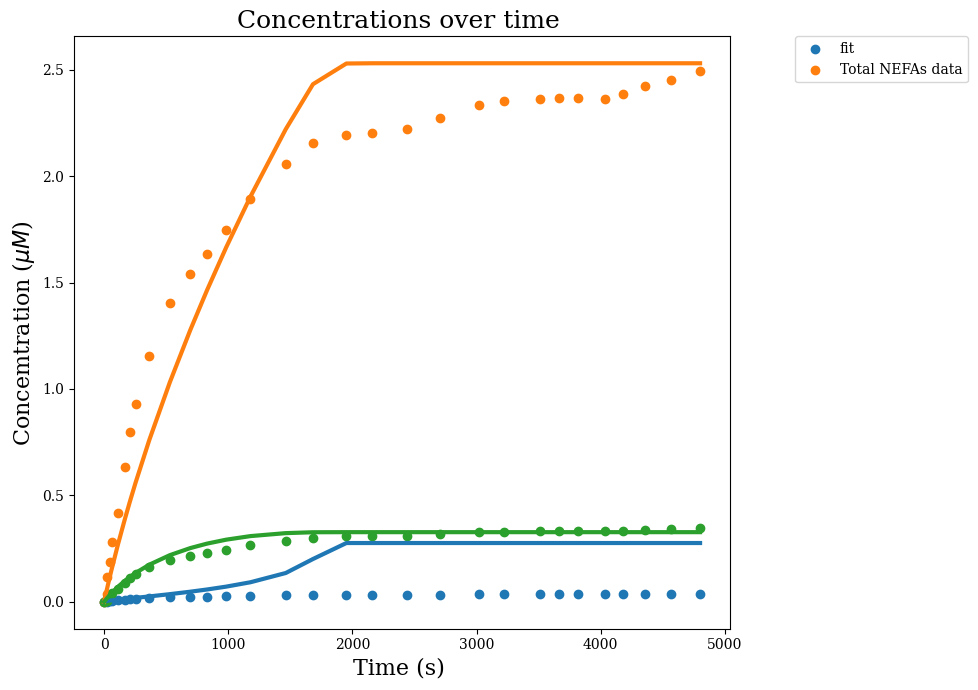

In [162]:
fig, ax = plt.subplots(figsize=(10, 7))
for i in range(3):
    ax.scatter(time_nefas1_simulation, topolska_long_run_data[:, i], marker="o")
ax.plot(time_nefas1_simulation, final2, linewidth=3)

# plt.plot(time1, final, '-', linewidth=2);
plt.xlabel("Time (s) ", fontsize=16)
plt.ylabel("Concemtration ($\mu M $) ", fontsize=16)
plt.title("Concentrations over time ", fontsize=18)
# plt.yscale("log")
ax.legend(
    ["fit", "Total NEFAs data"],
    loc="upper left",
    bbox_to_anchor=(1.1, 1),
    borderaxespad=0,
)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "Concentrations.pdf", bbox_inches="tight")
plt.show()


## Conclusion 

We need a different strategy to fit the transient and the steady state data. We suggest to explore three strategy 

- The solubility 
- The sinking enzyme(no longer the conservation relation for the enzymes ) 
- Or the reversing binding for malanyl-coA


In [163]:
par_total_fit = dict(result2.params.valuesdict())


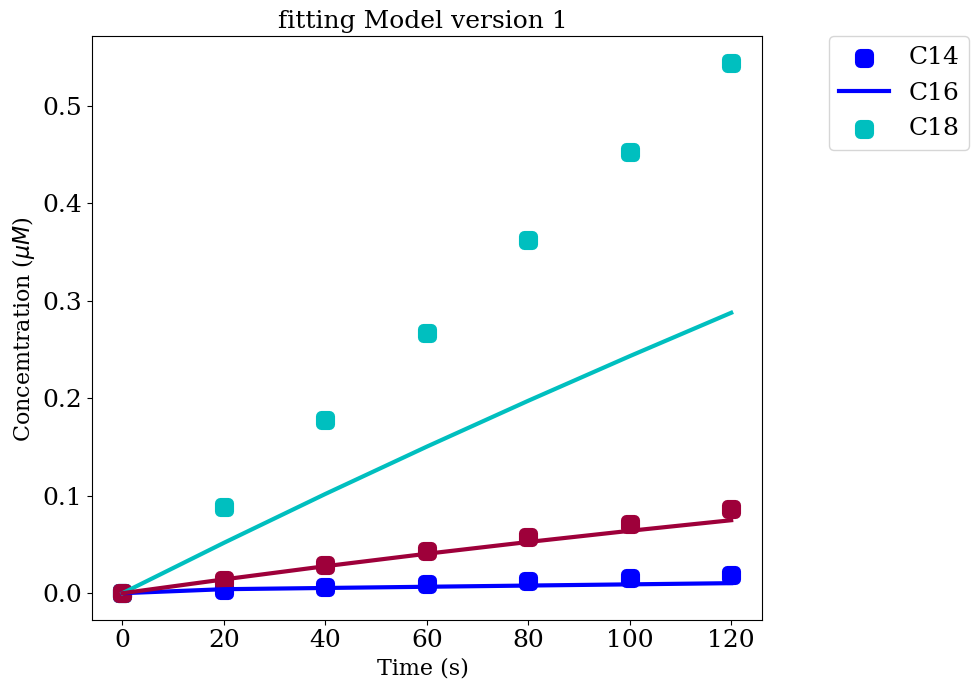

In [164]:
tot2 = fatty_acid_of_interest(
    system,
    par_total_fit,
    y0,
    max_time=time_initial_phase[-1],
    ncp_list=time_initial_phase,
)
fig, ax = plt.subplots(figsize=(10, 7))

for i in range(3):
    ax.scatter(
        time_initial_phase,
        data_initial_phase[:, i],
        color=color[i][0],
        marker="s",
        linewidths=8,
    )
    ax.plot(time_initial_phase, tot2[:, i], color=color[i][0], linewidth=3)

# plt.plot(time1, final, '-', linewidth=2);
plt.xlabel("Time (s) ", fontsize=16)
plt.ylabel("Concemtration ($\mu M$) ", fontsize=16)
plt.title("fitting Model version 1 ", fontsize=18)
plt.xticks(size=18)
plt.yticks(size=18)
# plt.yscale("log")
ax.legend(
    ["C14", "C16", "C18"],
    loc="upper left",
    bbox_to_anchor=(1.1, 1),
    borderaxespad=0,
    fontsize=18,
)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "Concentrations.pdf", bbox_inches="tight")
plt.show()


In [165]:
time1_interp = np.linspace(0, time_initial_phase[-1], len(total_nefas1))


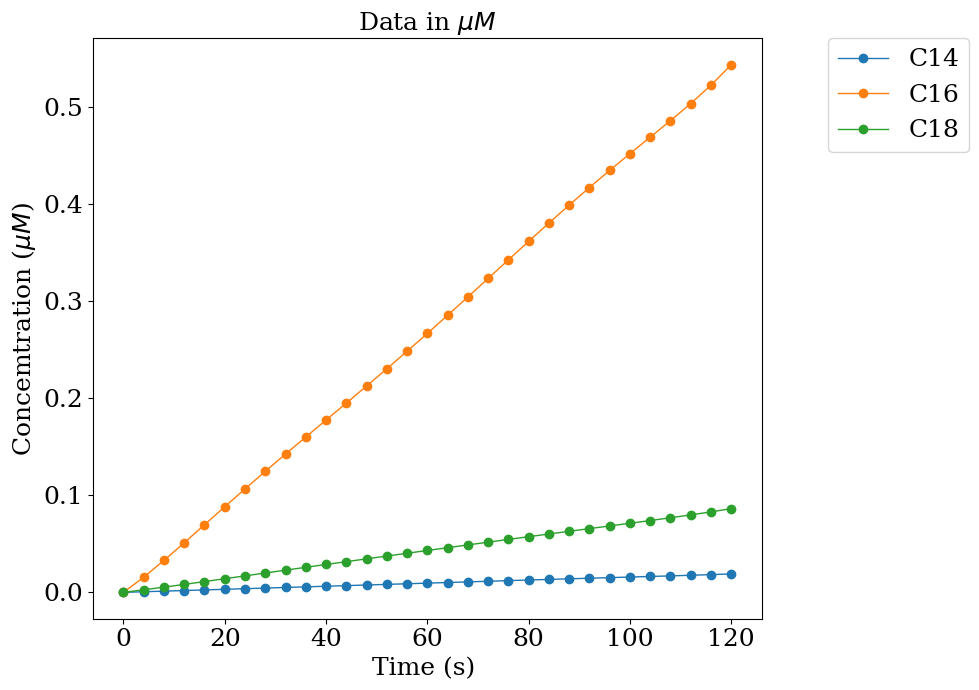

In [166]:
lagrange_interpolation_C14 = lagrange(time_initial_phase, data_initial_phase[:, 0])
lagrange_interpolation_C16 = lagrange(time_initial_phase, data_initial_phase[:, 1])
lagrange_interpolation_C18 = lagrange(time_initial_phase, data_initial_phase[:, 2])

C14_data = lagrange_interpolation_C14(time1_interp)
C16_data = lagrange_interpolation_C16(time1_interp)
C18_data = lagrange_interpolation_C18(time1_interp)

new_data = np.array([C14_data, C16_data, C18_data]).T
new_data.shape

fig, ax = plt.subplots(figsize=(10, 7))
plt.plot(time1_interp, new_data, "o-", linewidth=1)
# plt.plot(time1, final, '-', linewidth=2);
plt.xlabel("Time (s) ", fontsize=18)
plt.ylabel("Concemtration ($\mu M$) ", fontsize=18)
plt.title("Data in $\mu M$ ", fontsize=18)
plt.xticks(size=18)
plt.yticks(size=18)
# plt.yscale("log")
ax.legend(
    ["C14", "C16", "C18"],
    loc="upper left",
    bbox_to_anchor=(1.1, 1),
    borderaxespad=0,
    fontsize=18,
)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "Concentrations.pdf", bbox_inches="tight")
plt.show()


# Dual fitting 

## Strategy to have the acceptable parameters 
- We assume that Fa chains shorter that 14 are negligible
- We assume the rapid binding  which allows to calculate directly the value of $Kd_7$ and $\delta$.  It is important to notice that we assume that at the rate of $kd_8$ can be high therefore the rate from EC!6 to EC18 is sensibly equal to the rate of release of C18 FA
- The value of  $\beta$ and $\kappa$ are first  fitted from initial data before being 


In [167]:
def residual_two(parameters, max_time1, time1, data1, max_time2, time2, data2):
    # y0[1] = parameters["y0_mal"].value
    # print(y0)
    model1 = fatty_acid_of_interest(
        system, parameters, y0, max_time=max_time1, ncp_list=time1
    )
    model2 =total_long_fatty_acid(
        system, parameters, y0, max_time=max_time2, ncp_list=time2
    )
    res1 = (model1 - data1).ravel()
    res2 = (model2 - data2).ravel()

    return np.concatenate((res1, res2))


In [168]:
par_dual = Parameters()
par_dual.add("beta", value=1e-01, min=0)
par_dual.add(
    "kappa",
    value=1e-1,
    min=0,
)
par_dual.add("delta", value=4.5e-06, min=0)
# par_dual.add("kd1", value=1e-8, vary=False)
# par_dual.add("kd2", value=1e-8, vary=False)
# par_dual.add("kd3", value=1e-8, vary=False)
# par_dual.add("kd4", value=1e-6, vary=False)
# par_dual.add("kd5", value=1e-6, vary=False)
par_dual.add("kd6", value=0.86, min=0)
par_dual.add("kd7", value=0.03, min=0.02, max=0.04)
par_dual.add("kd8", value=0.12, min=0)
par_dual.add("kf_CoA", value=0, min=0, max=1e-6)
par_dual.add("kb_CoA", value=0, min=0, max=1e-4)
par_dual.add("kf_mal", value=par_fit_intial_phase["kf_mal"], min=0)
par_dual.add("kb_mal", value=par_fit_intial_phase["kb_mal"], min=0)
par_dual.add("kf_acet", value=par_fit_intial_phase["kf_acet"], min=0)
par_dual.add("kb_acet", value=par_fit_intial_phase["kb_acet"], min=0)

# par_two_fit = {
#     "beta": 0.1,
#     "kappa": 3.2e-05,
#     "delta": 1e-04,
#     "ka1": 0,
#     "ka2": 0,
#     "ka3": 0,
#     "ka4": 0,
#     "ka5": 0,
#     "ka6": 0,
#     "ka7": 0,
#     "ka8": 0,
#     "kd1": 0,
#     "kd2": 0,
#     "kd3": 0,
#     "kd4": 0,
#     "kd5": 1e-06,
#     "kd6": 0.0005,
#     "kd7": 5.606032300982918,
#     "kd8": 10,
#     "y0_mal": 20.5,

# }


In [169]:
result_two = minimize(
    residual_two,
    par_dual,
    args=(
        time1_interp[-1],
        time1_interp,
        data_to_fit,
        time_nefas1_simulation[-1],
        time_nefas1_simulation,
        total_nefas1,
    ),
    method="leastsq",
)


In [170]:
par_fitting_two = dict(result_two.params.valuesdict())
par_fitting_two


{'beta': 7.2141317074441815,
 'kappa': 20.50593075475374,
 'delta': 1.1080726074919056e-05,
 'kd6': 8.385661334700892,
 'kd7': 0.020067913085706372,
 'kd8': 0.013658503383802367,
 'kf_CoA': 0.0,
 'kb_CoA': 0.0,
 'kf_mal': 0.0031962585850091596,
 'kb_mal': 169432.88652067396,
 'kf_acet': 9.310805459961102e-10,
 'kb_acet': 98.57461525725738}

In [171]:
report_fit(result_two)


[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 259
    # data points      = 124
    # variables        = 12
    chi-square         = 5.00094831
    reduced chi-square = 0.04465132
    Akaike info crit   = -374.121097
    Bayesian info crit = -340.277718
##  Warning: uncertainties could not be estimated:
    kf_CoA:   at boundary
    kb_CoA:   at boundary
    kf_acet:  at initial value
    kf_acet:  at boundary
[[Variables]]
    beta:     7.21413171 (init = 0.1)
    kappa:    20.5059308 (init = 0.1)
    delta:    1.1081e-05 (init = 4.5e-06)
    kd6:      8.38566133 (init = 0.86)
    kd7:      0.02006791 (init = 0.03)
    kd8:      0.01365850 (init = 0.12)
    kf_CoA:   0.00000000 (init = 0)
    kb_CoA:   0.00000000 (init = 0)
    kf_mal:   0.00319626 (init = 7.252255e-07)
    kb_mal:   169432.887 (init = 1309.46)
    kf_acet:  9.3108e-10 (init = 9.310805e-10)
    kb_acet:  98.5746153 (init = 0.5331313)


In [172]:
fatty_acids = fatty_acid_of_interest(
    system,
    par=par_fitting_two,
    y0=y0,
    max_time=time_initial_phase[-1],
    ncp_list=time_initial_phase,
)


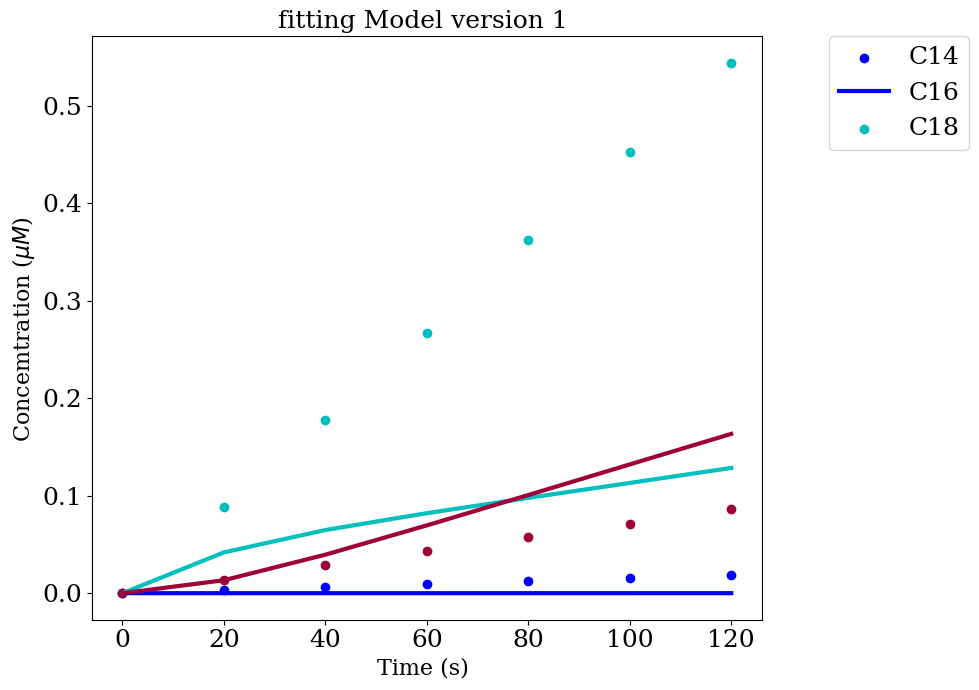

In [173]:
fig, ax = plt.subplots(figsize=(10, 7))

for i in range(3):
    ax.scatter(
        time_initial_phase, data_initial_phase[:, i], color=color[i][0], marker="o"
    )
    ax.plot(time_initial_phase, fatty_acids[:, i], color=color[i][0], linewidth=3)

# plt.plot(time1, final, '-', linewidth=2);
plt.xlabel("Time (s) ", fontsize=16)
plt.ylabel("Concemtration ($\mu M$) ", fontsize=16)
plt.title("fitting Model version 1 ", fontsize=18)
plt.xticks(size=18)
plt.yticks(size=18)
# plt.yscale("log")
ax.legend(
    ["C14", "C16", "C18"],
    loc="upper left",
    bbox_to_anchor=(1.1, 1),
    borderaxespad=0,
    fontsize=18,
)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "Concentrations.pdf", bbox_inches="tight")
plt.show()


In [174]:
simulated_nefas =total_long_fatty_acid(
    system,
    par=par_fitting_two,
    y0=y0,
    max_time=time_nefas1_simulation[-1],
    ncp_list=time_nefas1_simulation,
)


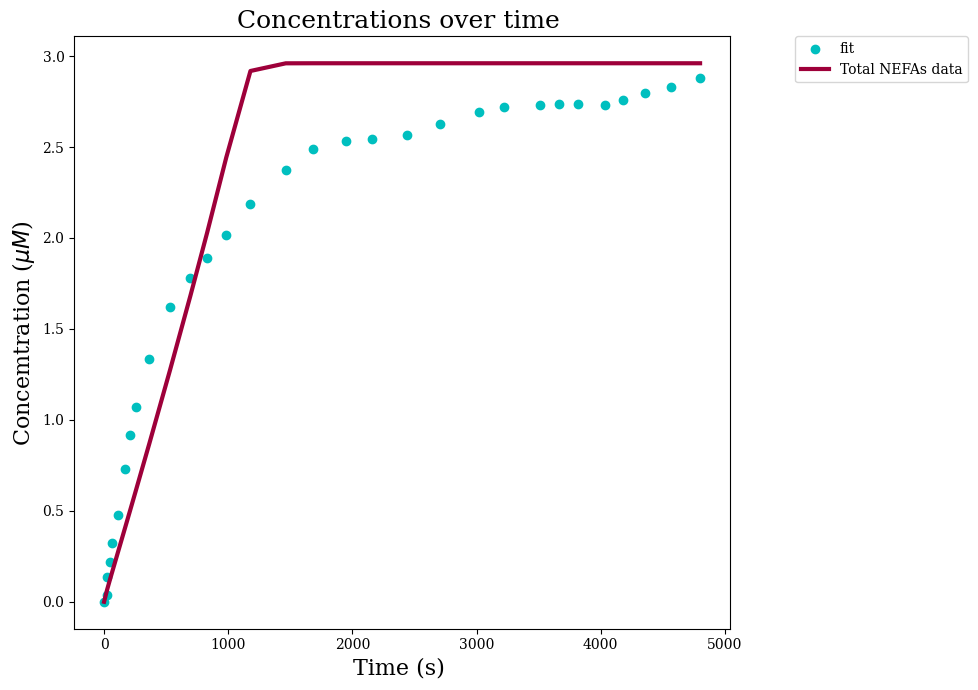

In [175]:
fig, ax = plt.subplots(figsize=(10, 7))


ax.scatter(time_nefas1_simulation, total_nefas1, color=color[1][0], marker="o")
ax.plot(time_nefas1_simulation, simulated_nefas, color=color[2][0], linewidth=3)

# plt.plot(time1, final, '-', linewidth=2);
plt.xlabel("Time (s) ", fontsize=16)
plt.ylabel("Concemtration ($\mu M $) ", fontsize=16)
plt.title("Concentrations over time ", fontsize=18)
# plt.yscale("log")
ax.legend(
    ["fit", "Total NEFAs data"],
    loc="upper left",
    bbox_to_anchor=(1.1, 1),
    borderaxespad=0,
)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "Concentrations.pdf", bbox_inches="tight")
plt.show()


In [176]:
time_course1 = [
    ["NADPH"],
    ["AcetylCoA"],
    ["MalonylCoA", "CoA"],
    [
        "E",
        "ECoA",
    ],
    ["EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14", "EC16", "EC18"],
    ["C14FA", "C16FA", "C18FA"],
]


### check the parameters on initial phase data 

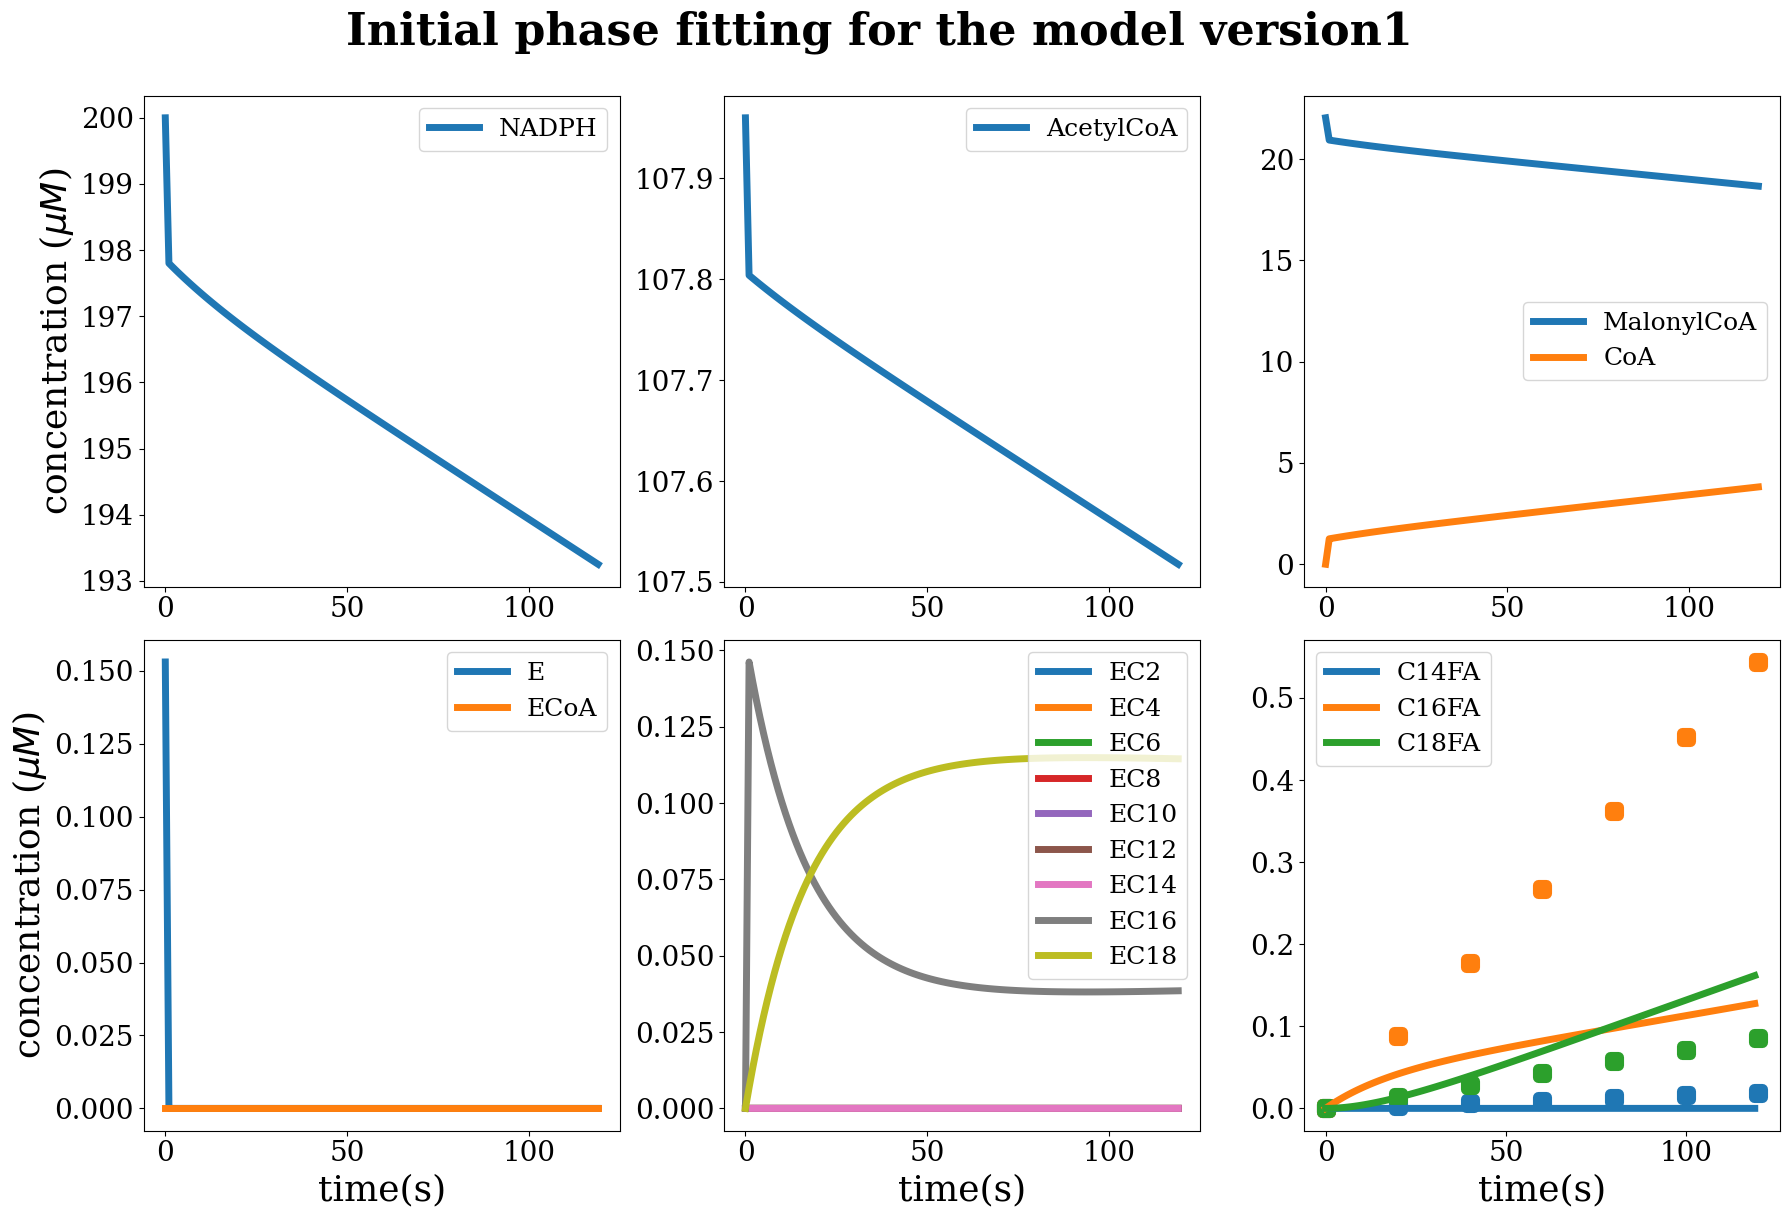

In [177]:
fig, axs = multi_plot_time_course(
    groups=time_course1,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time1,
    ncp_list=ncp_list1,
    par=par_fitting_two,
    compounds=compounds,
    ncols=3,
    resizer=6,
    sharey=False,
    title="Initial phase fitting for the model version1  ",
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
# adding data to a particular graph
all_fatty_acids = total_long_fatty_acid(
    system, par_fitting_two, y0, max_time=time_nefas1_simulation, ncp_list=ncp_list2
)

for i in range(3):
    axs[1, 2].scatter(
        time_initial_phase,
        data_initial_phase[:, i],
        color=cols[i],
        marker="s",
        linewidth=8,
    )
plt.savefig(RESULTS_DIR / "initial_fitting_best.pdf", dpi=300, bbox_inches="tight")


In [178]:
ncp_list3 = [i for i in range(0, 10000)]
max_time3 = ncp_list3[-1]


### check the parameters on long run

In [179]:
time_course2 = [
    ["NADPH"],
    ["AcetylCoA"],
    ["MalonylCoA", "CoA"],
    [
        "E",
        "ECoA",
    ],
    [
        "EC2",
        "EC4",
        "EC6",
        "EC8",
        "EC10",
        "EC12",
        "EC14",
        "EC16",
        "EC18",
    ],
    [
        "EMal",
        "EC2Acet",
        "EC4Acet",
        "EC6Acet",
        "EC8Acet",
        "EC10Acet",
        "EC12Acet",
        "EC14Acet",
        "EC16Acet",
        "EC18Acet",
    ],
    ["C14FA", "C16FA", "C18FA"],
]


['AcetylCoA',
 'MalonylCoA',
 'C14FA',
 'C16FA',
 'C18FA',
 'CoA',
 'E',
 'EC2',
 'EC4',
 'EC6',
 'EC8',
 'EC10',
 'EC12',
 'EC14',
 'EC16',
 'EC18',
 'ECoA',
 'EMal',
 'EC2Acet',
 'EC4Acet',
 'EC6Acet',
 'EC8Acet',
 'EC10Acet',
 'EC12Acet',
 'EC14Acet',
 'EC16Acet',
 'EC18Acet',
 'NADPH']

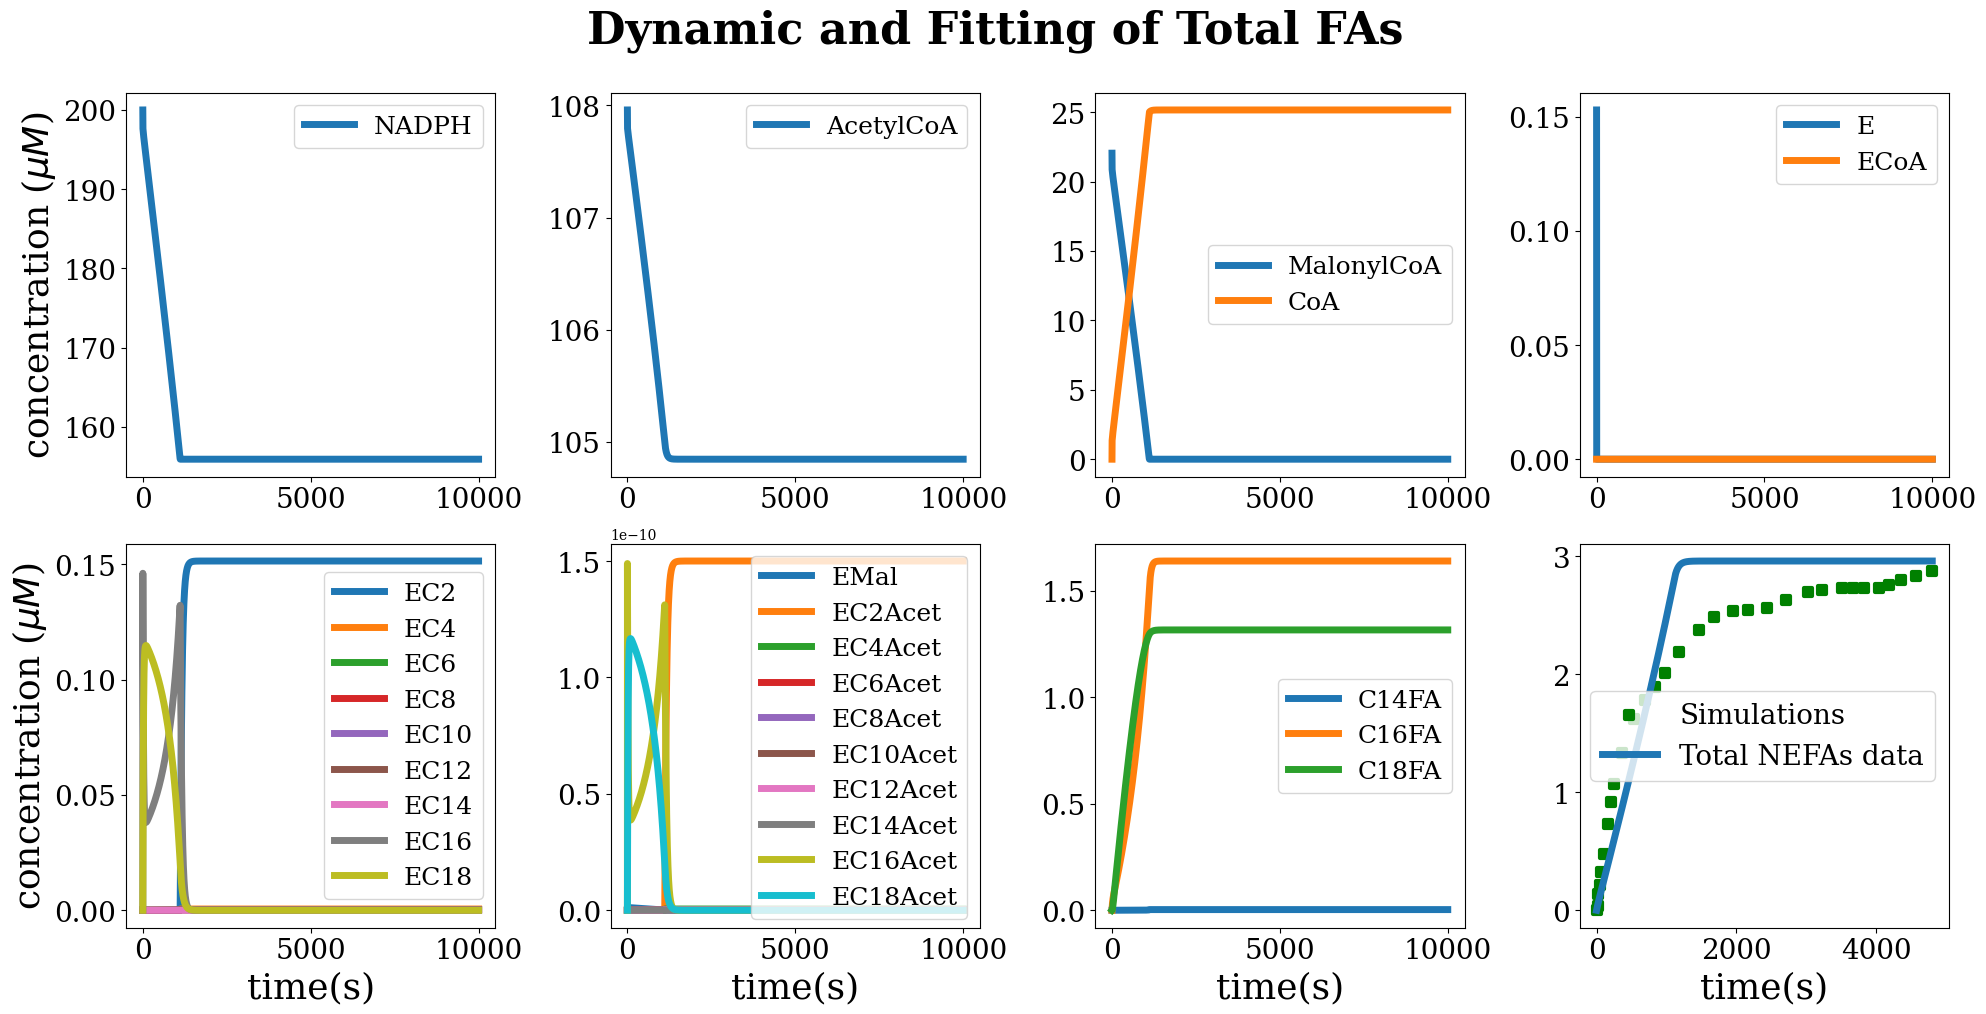

In [180]:
fig, axs = multi_plot_time_course(
    groups=time_course2,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time3,
    ncp_list=ncp_list3,
    par=par_fitting_two,
    compounds=compounds,
    ncols=4,
    resizer=5,
    sharey=False,
    title="Dynamic and Fitting of Total FAs",
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
# adding data to a particular graph
all_fatty_acids =total_long_fatty_acid(
    system, par_fitting_two, y0, max_time=time_nefas1_simulation, ncp_list=ncp_list2
)

axs[1, 3].scatter(
    time_nefas1_simulation,
    total_nefas1,
    marker="s",
    linewidths=3,
    color=colors[i],
    label="Total NEFAs",
)
axs[1, 3].plot(ncp_list2, all_fatty_acids, linewidth=5)
axs[1, 3].legend(["Simulations", "Total NEFAs data"], fontsize=20)
plt.savefig(RESULTS_DIR / "long_run_new_best.pdf", dpi=300, bbox_inches="tight")

compounds

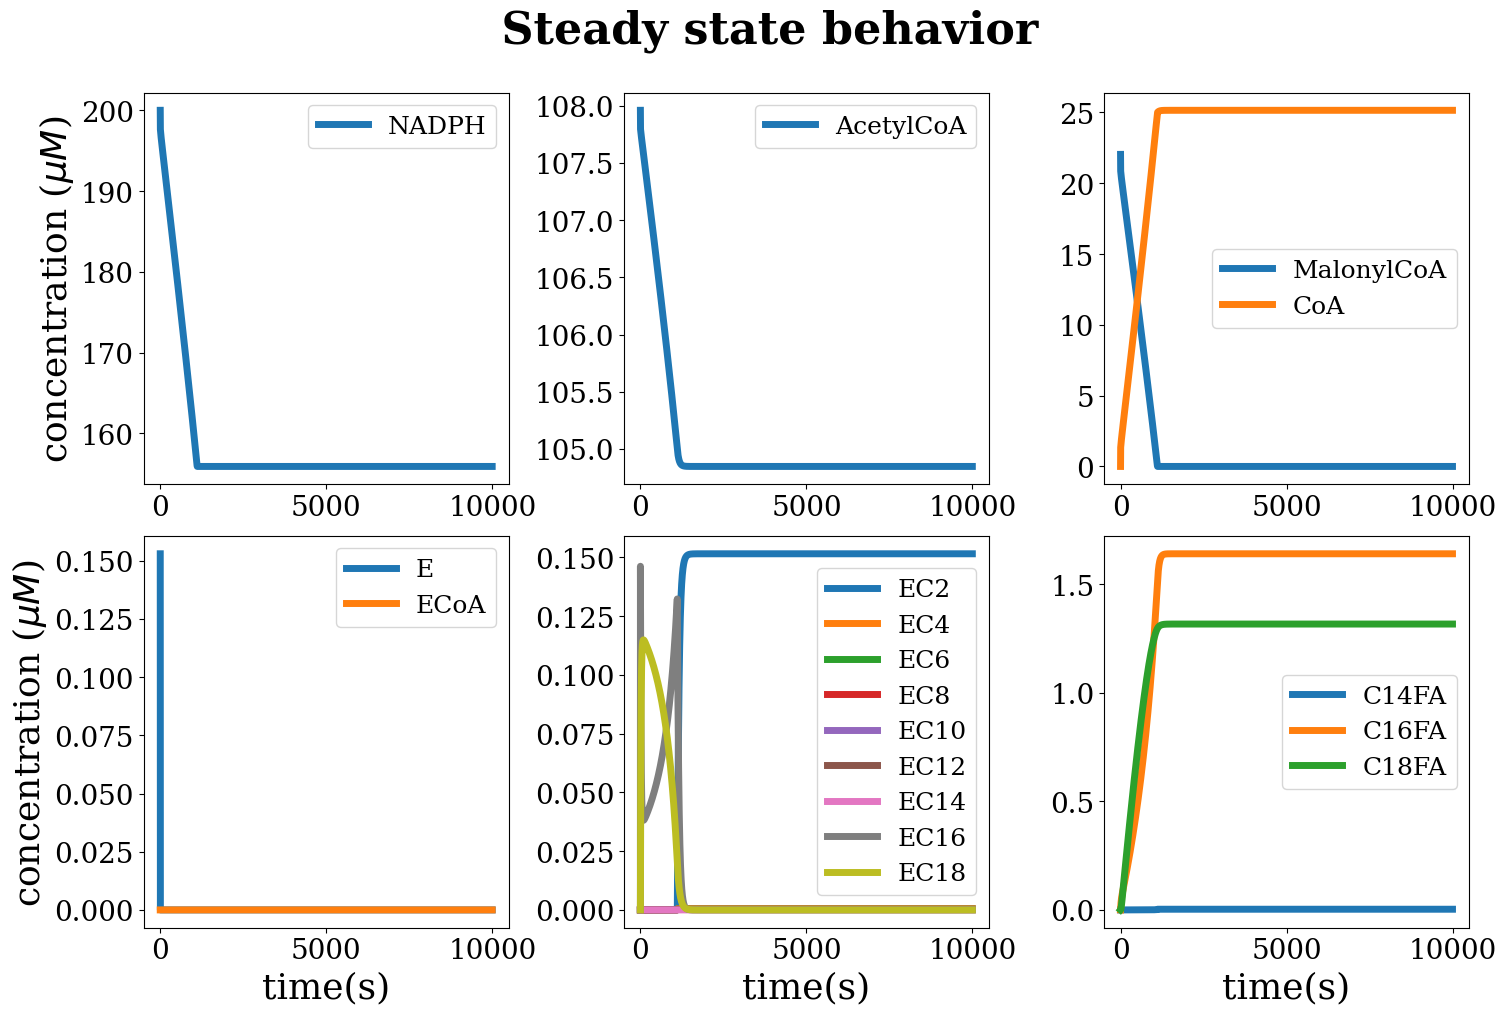

In [181]:
fig, axs = multi_plot_time_course(
    groups=time_course1,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time3,
    ncp_list=ncp_list3,
    par=par_fitting_two,
    compounds=compounds,
    ncols=3,
    resizer=5,
    sharey=False,
    title=" Steady state behavior",
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)


plt.savefig(RESULTS_DIR / "very_long_run_new_best.pdf", dpi=300, bbox_inches="tight")


In [182]:
def fn(i: int) -> dict:
    json_dict = {
        "fail": False,
    }
    try:
        beta = rd.uniform(0, 1e2)
        kappa = rd.uniform(0, 1e2)
        delta = rd.uniform(0, 1e-5)
        # kd1 = 0  # rd.uniform(0, 1e2)
        # kd2 = 0  # rd.uniform(0, 1e2)
        # kd3 = 0  # rd.uniform(0, 1e2)
        # kd4 = 0  # rd.uniform(0, 1e2)
        # kd5 = 0  # rd.uniform(0, 1e2)
        kd6 = rd.uniform(0, 1e2)
        kd7 = 0.31  # rd.uniform(1, 1000)
        kd8 = rd.uniform(0, 1e2)
        kf_CoA = rd.uniform(0, 1e1)
        kb_CoA = rd.uniform(0, 1e1)
        kf_mal = rd.uniform(0, 1e1)
        kb_mal = rd.uniform(0, 1e1)
        kf_acet = rd.uniform(0, 1e1)
        kb_acet = rd.uniform(0, 1e1)

        list_values = [
            beta,
            kappa,
            delta,
            # kd1,
            # kd2,
            # kd3,
            # kd4,
            # kd5,
            kd6,
            kd7,
            kd8,
            kf_CoA,
            kb_CoA,
            kf_mal,
            kb_mal,
            kf_acet,
            kb_acet,
        ]

        kappa = rd.uniform(1, 1e1)

        initial_parameters = dict(zip(list_par, list_values))
        initial_parameters = repr(initial_parameters)
        json_dict["initial_val"] = initial_parameters

        ################ For Topolska  #################################
        par_fit_dual_topolska = Parameters()
        par_fit_dual_topolska.add("beta", value=beta, vary=False)
        par_fit_dual_topolska.add("kappa", value=kappa, min=0)
        par_fit_dual_topolska.add("delta", value=delta, min=0)
        # par_fit_dual_topolska.add("kd1", value=kd1, vary=False)
        # par_fit_dual_topolska.add("kd2", value=kd2, vary=False)
        # par_fit_dual_topolska.add("kd3", value=kd3, vary=False)
        # par_fit_dual_topolska.add("kd4", value=kd4, vary=False)
        # par_fit_dual_topolska.add("kd5", value=kd5, vary=False)
        par_fit_dual_topolska.add("kd6", value=kd6, min=0)
        par_fit_dual_topolska.add("kd7", value=0.032, vary=False)
        par_fit_dual_topolska.add("kd8", value=kd8, min=0)
        par_fit_dual_topolska.add("kf_CoA", value=kf_CoA, min=0)
        par_fit_dual_topolska.add("kb_CoA", value=kb_CoA, min=0)
        par_fit_dual_topolska.add("kf_mal", value=kf_mal, min=0)
        par_fit_dual_topolska.add("kb_mal", value=kb_mal, min=0)
        par_fit_dual_topolska.add("kf_acet", value=kf_acet, min=0)
        par_fit_dual_topolska.add("kb_acet", value=kb_acet, min=0)

        result__dual_topolska = minimize(
            residual_two,
            par_dual,
            args=(
                time1_interp[-1],
                time1_interp,
                data_to_fit,
                time_nefas1_simulation[-1],
                time_nefas1_simulation,
                total_nefas1,
            ),
            method="leastsq",
        )
        par_fit_result_topolska = dict(result__dual_topolska.params.valuesdict())
        chi_fit_result_topolska = result__dual_topolska.chisqr
        par_fit_result_topolska = repr(par_fit_result_topolska)
        chi_fit_result_topolska = repr(chi_fit_result_topolska)
        json_dict["par_fit_topolska"] = par_fit_result_topolska
        json_dict["chi_square_topolska"] = float(chi_fit_result_topolska)

    except CVodeError:
        json_dict["fail"] = True
    return {i: json_dict}


In [183]:


list_par = [
    "beta",
    "kappa",
    "delta",
    # "kd1",
    # "kd2",
    # "kd3",
    # "kd4",
    # "kd5",
    "kd6",
    "kd7",
    "kd8",
    "kf_CoA",
    "kb_CoA",
    "kf_mal",
    "kb_mal",
    "kf_acet",
    "kb_acet",
]


# the number of time to sample the parameters from a particular distribution
number_of_draw = 5

with ProcessPoolExecutor() as executor:
    tasks = range(number_of_draw)
    raw = tqdm(executor.map(fn, tasks), total=len(tasks))
    json_dict = dict(ChainMap(*raw))


with open(RESULTS_DIR / "parameters_scan.json", "w") as file:
    json.dump(json_dict, file)


100%|██████████| 5/5 [00:43<00:00,  8.75s/it]


In [184]:
with open(RESULTS_DIR / "parameters_scan.json", "r") as file:
    output_dictionnary = json.load(file)

list_chi_square_topolska = []
for i in range(number_of_draw):
    list_chi_square_topolska.append(output_dictionnary[f"{i}"]["chi_square_topolska"])


In [185]:
def get_minvalue(inputlist):

    # get the minimum value in the list
    min_value = min(inputlist)

    # return the index of minimum value
    min_index = inputlist.index(min_value)
    return min_index


index_min_chisq = get_minvalue(list_chi_square_topolska)
index_min_chisq


0

In [186]:
optimal_params = eval(json_dict[index_min_chisq]["par_fit_topolska"])
optimal_params


{'beta': 7.2141317074441815,
 'kappa': 20.50593075475374,
 'delta': 1.1080726074919056e-05,
 'kd6': 8.385661334700892,
 'kd7': 0.020067913085706372,
 'kd8': 0.013658503383802367,
 'kf_CoA': 0.0,
 'kb_CoA': 0.0,
 'kf_mal': 0.0031962585850091596,
 'kb_mal': 169432.88652067396,
 'kf_acet': 9.310805459961102e-10,
 'kb_acet': 98.57461525725738}

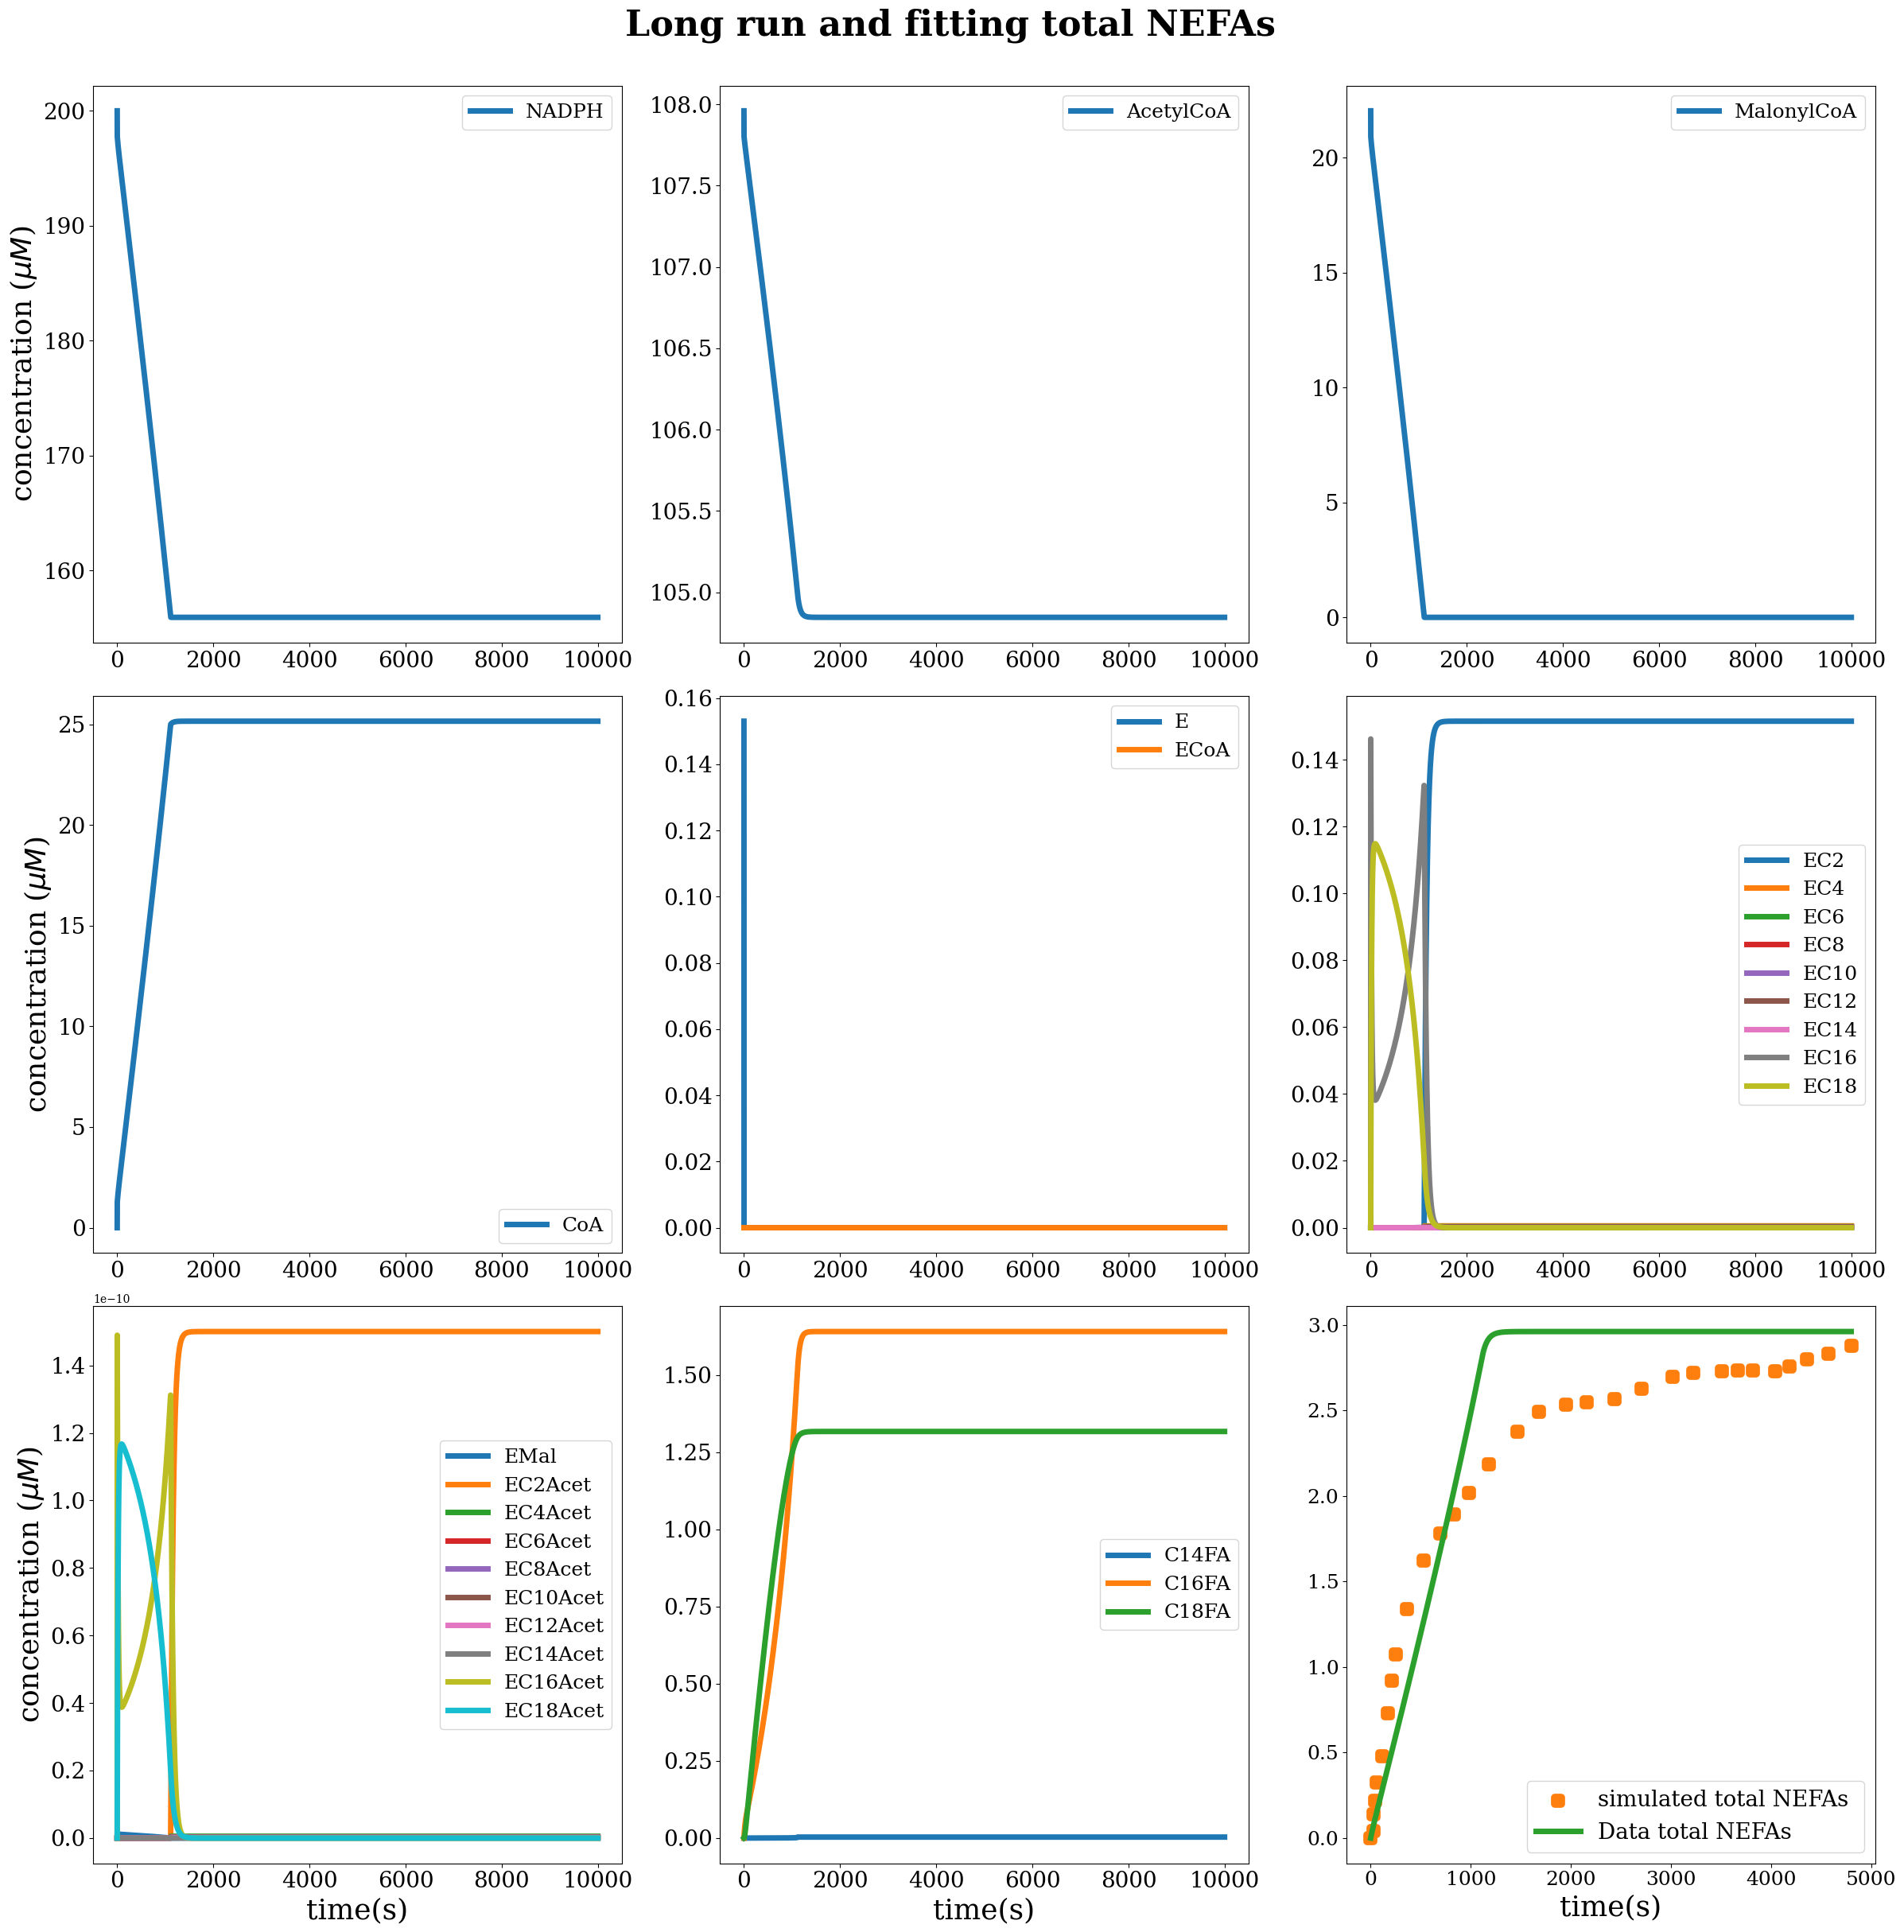

In [187]:
long_run = [
    ["NADPH"],
    ["AcetylCoA"],
    ["MalonylCoA"],
    ["CoA"],
    # ["C14FA"],
    # ["C16FA"],
    # ["C18FA"],
    ["E", "ECoA"],
    ["EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14", "EC16", "EC18"],
    [
        "EMal",
        "EC2Acet",
        "EC4Acet",
        "EC6Acet",
        "EC8Acet",
        "EC10Acet",
        "EC12Acet",
        "EC14Acet",
        "EC16Acet",
        "EC18Acet",
    ],
    [
        "C14FA",
        "C16FA",
        "C18FA",
    ],
]

fig, axs = multi_plot_time_course(
    groups=long_run,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time3,
    ncp_list=ncp_list3,
    par=optimal_params,
    compounds=compounds,
    ncols=3,
    resizer=8,
    sharey=False,
    title="Long run and fitting total NEFAs",
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
# adding data to a particular graph
all_fatty_acids = total_long_fatty_acid(
    system, optimal_params, y0, max_time=time_nefas1_simulation, ncp_list=ncp_list2
)

axs[2, 2].scatter(
    time_nefas1_simulation, total_nefas1, marker="s", linewidths=7, color=cols[1]
)
axs[2, 2].plot(ncp_list2, all_fatty_acids, color=cols[2], linewidth=5)
axs[2, 2].legend(
    [
        "simulated total NEFAs ",
        "Data total NEFAs",
    ],
    prop={"size": 20},
)
plt.tick_params(axis="both", labelsize=18)
plt.savefig(RESULTS_DIR / "long_run_new.pdf", dpi=300, bbox_inches="tight")


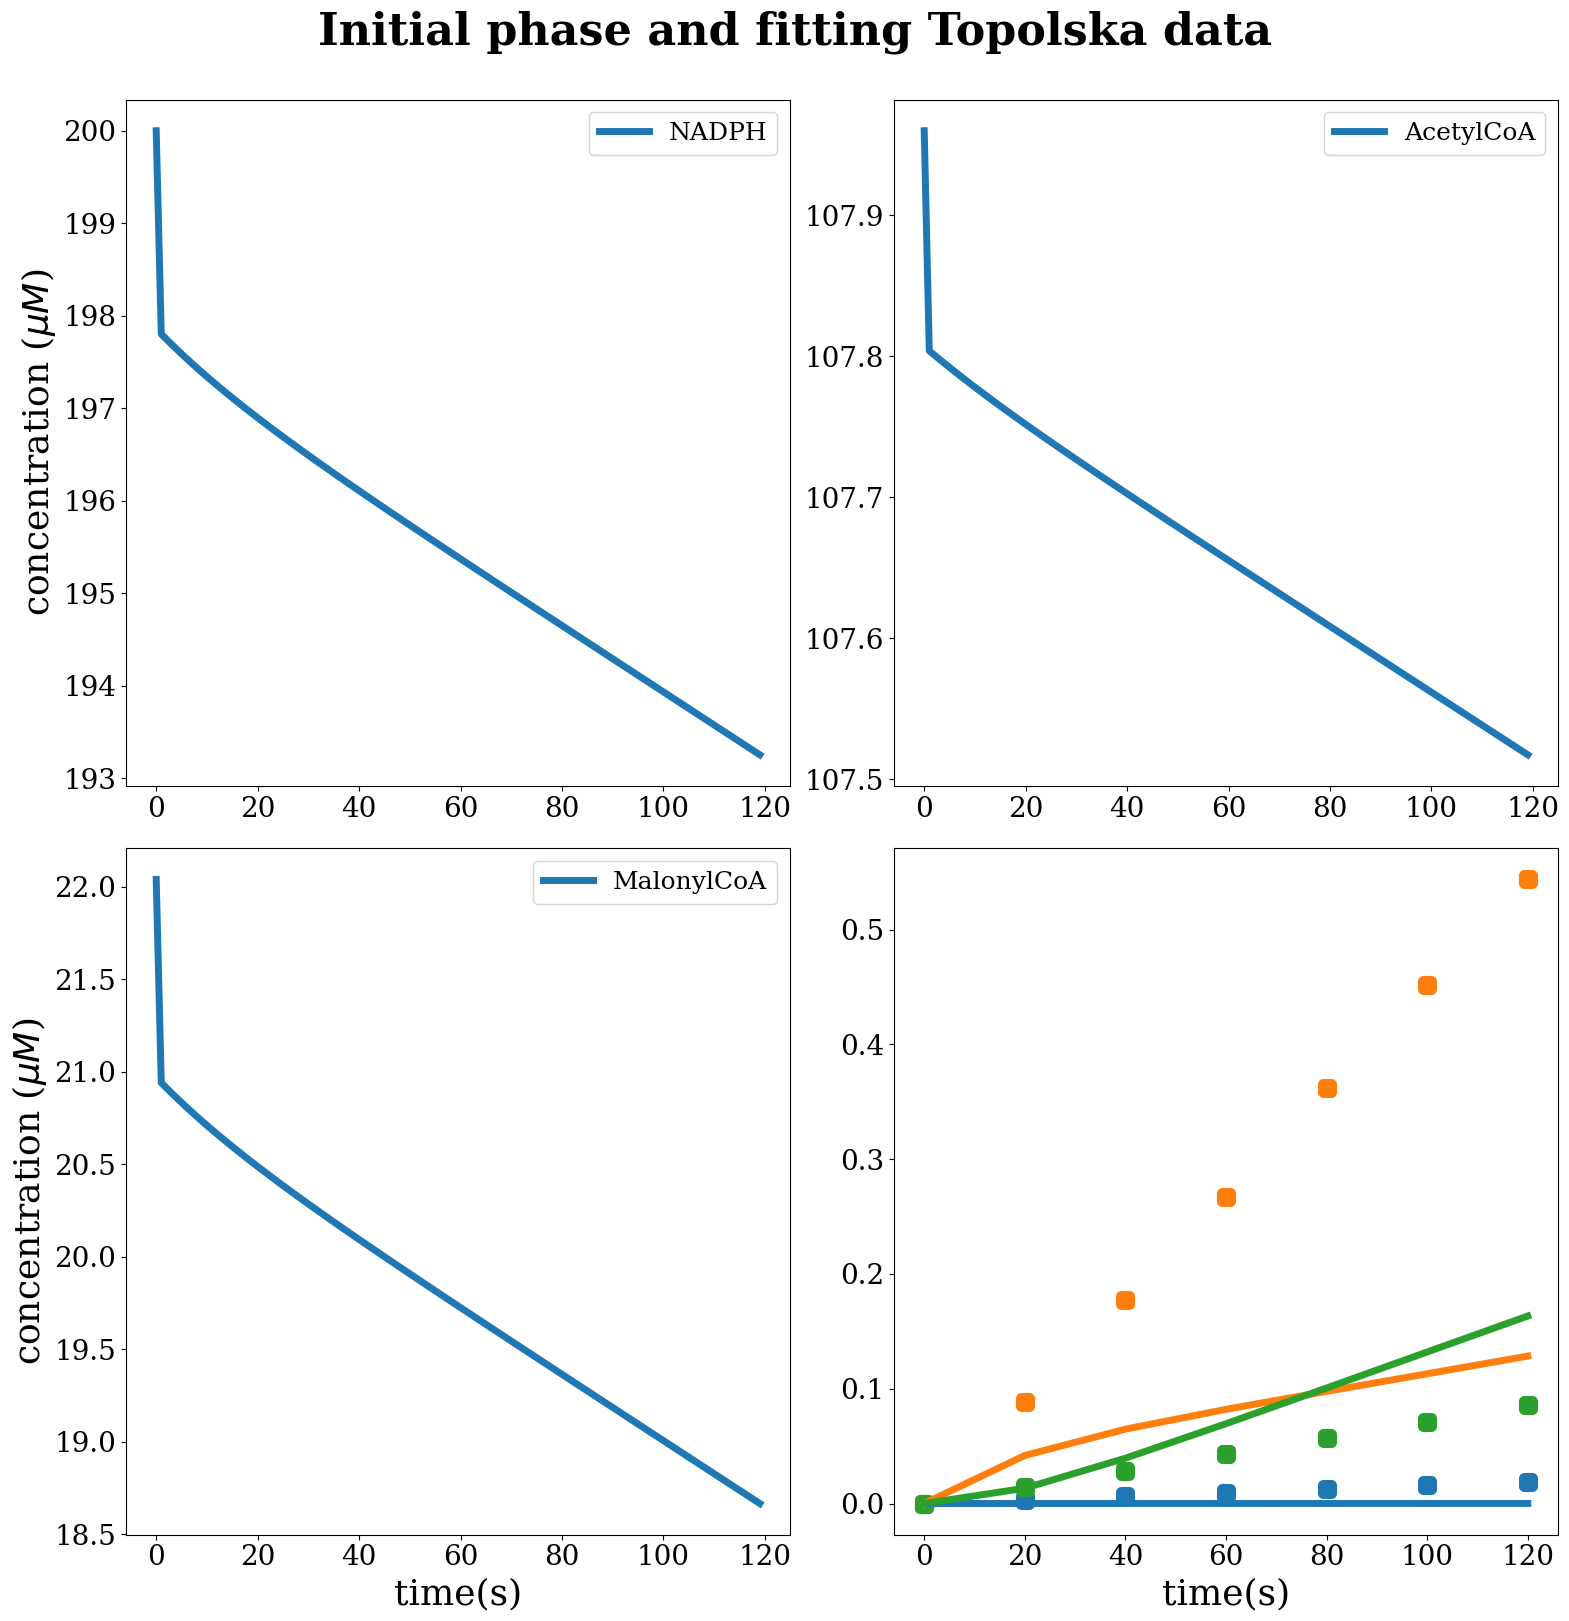

In [188]:
initial_comp = [
    ["NADPH"],
    ["AcetylCoA"],
    ["MalonylCoA"],
    # ["C14FA"],
    # ["C16FA"],
    # ["C18FA"],
    # ["EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14", "EC16", "EC18"],
    # [
    #     "C14FA",
    #      "C16FA",
    #  "C18FA",
    # ],
]

fig, axs = multi_plot_time_course(
    groups=initial_comp,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time1,
    ncp_list=ncp_list1,
    par=par_fitting_two,
    compounds=compounds,
    ncols=2,
    resizer=8,
    sharey=False,
    title="Initial phase and fitting Topolska data",
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
# adding data to a particular graph
fatty_acids = fatty_acid_of_interest(
    system,
    par_fitting_two,
    y0,
    max_time=time_initial_phase[-1],
    ncp_list=time_initial_phase,
)
for i in range(3):
    axs[1, 1].scatter(
        time_initial_phase,
        data_initial_phase[:, i],
        marker="s",
        linewidths=8,
        color=cols[i],
    )
axs[1, 1].plot(time_initial_phase, fatty_acids, linewidth=5)
# axs[1, 1].legend(
#     [

#     "simulated",
#     "Data total NEFAs",
#     ],
# prop={'size': 20}
# )
plt.tick_params(axis="both", labelsize=20)

plt.savefig(RESULTS_DIR / "initial_new.pdf", dpi=300, bbox_inches="tight")


# Design  experiment 

Here we would like to get the Kcat and the Km values of as if our model was an experiment.

In [189]:
acetyl_concentration = [i for i in range(0, 200, 10)]
malonyl_concentration = [i for i in range(0, 200, 10)]
Nadph_concentration = [i for i in range(0, 200, 10)]


# Measuring the Michaelis Menten parameters for acetyl-CoA


In [190]:
def specific_fatty_acid(
    specific_compound: str,
    compounds: list[str],
    system,
    par: dict[str, float],
    y0: float,
    max_time: float,
    ncp_list=None,
):
    time, y = simulate_time_course(
        model=system, par=par, y0=y0, max_time=max_time, ncp_list=ncp_list
    )
    y = y.T
    y_dict = dict(zip(compounds, y))
    expr = y_dict[specific_compound]

    return expr


In [191]:
specific_fatty_acid(
    "NADPH", compounds, system, par_fitting_two, y0, max_time2, ncp_list2
)


array([200.        , 197.80153858, 197.74634141, ..., 155.92      ,
       155.92      , 155.92      ])

In [192]:
def time_course_production(
    var_substrate: str,
    prod: str,
    compounds: list[str],
    system,
    y0_dict: dict[str, float],
    par: dict[str, float],
    lower_val: float,
    upper_val: float,
    number_of_values: int,
    max_time: float,
    ncp_list: list,
):
    """
    The function   help to build a family of curve of time couse
    by varying a specific substrates

    Returns:
        _type_: _description_
    """
    y0_dict1 = y0_dict.copy()
    list_substrate_values = np.linspace(lower_val, upper_val, number_of_values)
    data_dict = {}
    fig, ax = plt.subplots(figsize=(8, 6))
    for i in list_substrate_values:
        y0_dict1[var_substrate] = i

        z0 = np.array(list(y0_dict1.values()))

        time_course_prod = specific_fatty_acid(
            prod, compounds, system, par, z0, max_time, ncp_list
        )
        data_dict[f"{i}"] = time_course_prod

        ax.plot(
            ncp_list,
            data_dict[f"{i}"],
            "-o",
            label=var_substrate + " =" + f"{i}",
        )

    ax.set_xlabel("time (s)")
    ax.set_ylabel(f"concentration of {prod} ($\mu M$)")
    ax.set_title(
        f" Time course of {prod} at different concentration of  {var_substrate} "
    )
    ax.legend(loc="upper left", bbox_to_anchor=(1, 0.5))

    return data_dict


In [193]:
def steady_state_kinetics(
    var_substrate: str,
    prod: str,
    compounds: list[str],
    system,
    y0_dict: dict[str, float],
    par: dict[str, float],
    lower_val: float,
    upper_val: float,
    number_of_values: int,
    max_time: float,
    ncp_list: list,
):
    """
    The function   help to build  steady state kinetics of a particular product
    base onn the variation of a particular substrate

    Returns:
        _type_: _description_
    """
    y0_dict1 = y0_dict.copy()
    list_substrate_values = np.linspace(lower_val, upper_val, number_of_values)
    # data_dict = {}
    rate_kinetics = []
    Delta_t = ncp_list[-1] - ncp_list[0]
    for i in list_substrate_values:
        y0_dict1[var_substrate] = i

        z0 = np.array(list(y0_dict1.values()))

        time_course_prod = specific_fatty_acid(
            prod, compounds, system, par, z0, max_time, ncp_list
        )
        # data_dict[f"{i}"] = time_course_prod

        Delta_p = time_course_prod[-1] - time_course_prod[0]
        rate_of_change = Delta_p / Delta_t
        rate_kinetics.append(rate_of_change)
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.scatter(list_substrate_values, rate_kinetics)
    ax.plot(list_substrate_values, rate_kinetics)
    ax.set_xlabel(f"{var_substrate} ($\mu M$)")
    ax.set_ylabel(f"rate kinetics of {prod} ($\mu M \cdot s^{-1}$)")
    ax.set_title(f"Steady state kinetics of {prod} as function of {var_substrate} ")

    return ax


In [194]:
compounds


['AcetylCoA',
 'MalonylCoA',
 'C14FA',
 'C16FA',
 'C18FA',
 'CoA',
 'E',
 'EC2',
 'EC4',
 'EC6',
 'EC8',
 'EC10',
 'EC12',
 'EC14',
 'EC16',
 'EC18',
 'ECoA',
 'EMal',
 'EC2Acet',
 'EC4Acet',
 'EC6Acet',
 'EC8Acet',
 'EC10Acet',
 'EC12Acet',
 'EC14Acet',
 'EC16Acet',
 'EC18Acet',
 'NADPH']

In [195]:
# list of time points to be considered by the integrator
ncp_list1 = [i for i in range(0, 120, 1)]
ncp_list2 = [i for i in range(0, 4800)]
max_time1 = ncp_list1[-1]
max_time2 = ncp_list2[-1]
init = np.zeros(n_compounds)
# init = 10*np.random.uniform(0,1,n_compounds)
time_initial_phase = initial_phase_data[:, 0]
y1_dict = dict(zip(compounds, init))

# modifying initial conditions
y1_dict["E"] = 0.153
y1_dict["AcetylCoA"] = 50 + (80 - 22.04)
y1_dict["NADPH"] = 200
y1_dict["MalonylCoA"] = 22.04
# y0_dict["C4FA"] = 0.0
# y0_dict["C6FA"] = 0.0
# y0_dict["C8FA"] = 0.0
# y0_dict["C10FA"] = 0.0
# y0_dict["C12FA"] = 0.0
y1_dict["C14FA"] = 0.0
y1_dict["C16FA"] = 0.0
y1_dict["C18FA"] = 0.0
y1 = np.fromiter(y1_dict.values(), dtype=float)


In [196]:
y1_dict["AcetylCoA"] = 50
y1_dict["MalonylCoA"] = 100
y1_dict["NADPH"] = 200


In [197]:
ncp_lista = [i for i in range(0, 100, 1)]
max_timea = ncp_lista[-1]


{'1.0': array([0.        , 0.00250373, 0.00497429, 0.00739577, 0.00976913,
        0.01209535, 0.01437534, 0.01661004, 0.01880034, 0.02094712,
        0.02305125, 0.02511357, 0.02713492, 0.02911611, 0.03105794,
        0.03296119, 0.03482662, 0.036655  , 0.03844704, 0.04020349,
        0.04192503, 0.04361237, 0.04526619, 0.04688715, 0.04847591,
        0.0500331 , 0.05155935, 0.05305528, 0.05452149, 0.05595857,
        0.05736709, 0.05874763, 0.06010074, 0.06142697, 0.06272685,
        0.06400091, 0.06524965, 0.06647358, 0.06767319, 0.06884897,
        0.0700014 , 0.07113092, 0.072238  , 0.07332309, 0.07438662,
        0.07542902, 0.07645071, 0.0774521 , 0.07843359, 0.07939559,
        0.08033847, 0.08126261, 0.0821684 , 0.08305619, 0.08392635,
        0.08477921, 0.08561513, 0.08643444, 0.08723748, 0.08802456,
        0.088796  , 0.08955211, 0.09029321, 0.09101957, 0.09173151,
        0.0924293 , 0.09311323, 0.09378357, 0.0944406 , 0.09508457,
        0.09571574, 0.09633437, 0.0969407

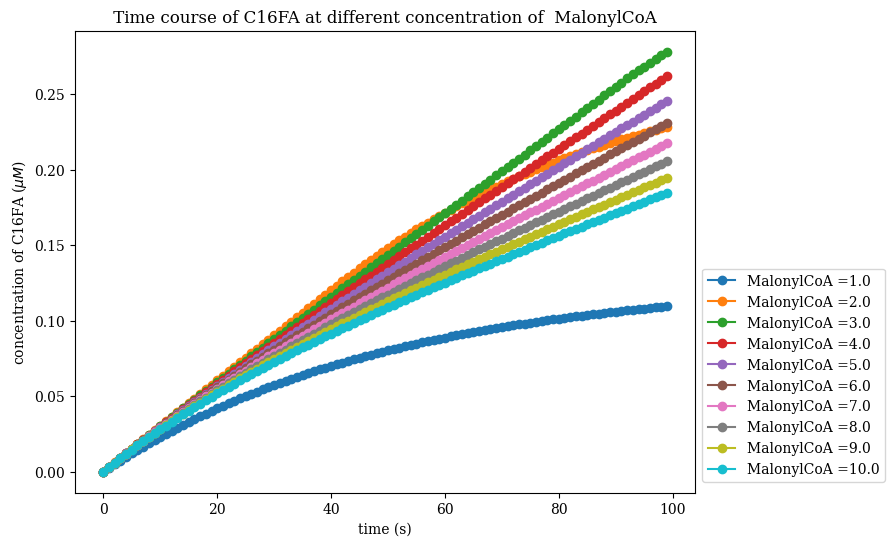

In [198]:
time_course_production(
    "MalonylCoA",
    "C16FA",
    compounds,
    system,
    y1_dict,
    par_fitting_two,
    1,
    10,
    10,
    max_timea,
    ncp_lista,
)


<AxesSubplot:title={'center':'Steady state kinetics of C16FA as function of AcetylCoA '}, xlabel='AcetylCoA ($\\mu M$)', ylabel='rate kinetics of C16FA ($\\mu M \\cdot s^-1$)'>

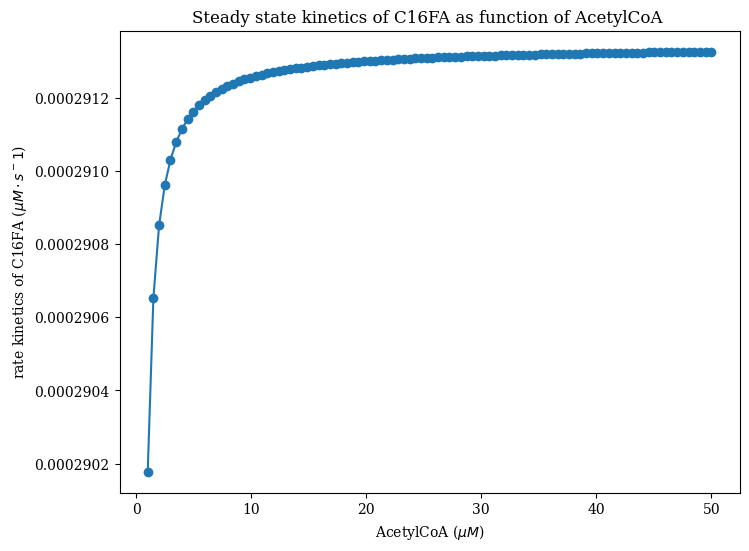

In [199]:
steady_state_kinetics(
    "AcetylCoA",
    "C16FA",
    compounds,
    system,
    y1_dict,
    par_fitting_two,
    1,
    50,
    100,
    max_time1,
    ncp_list1,
)


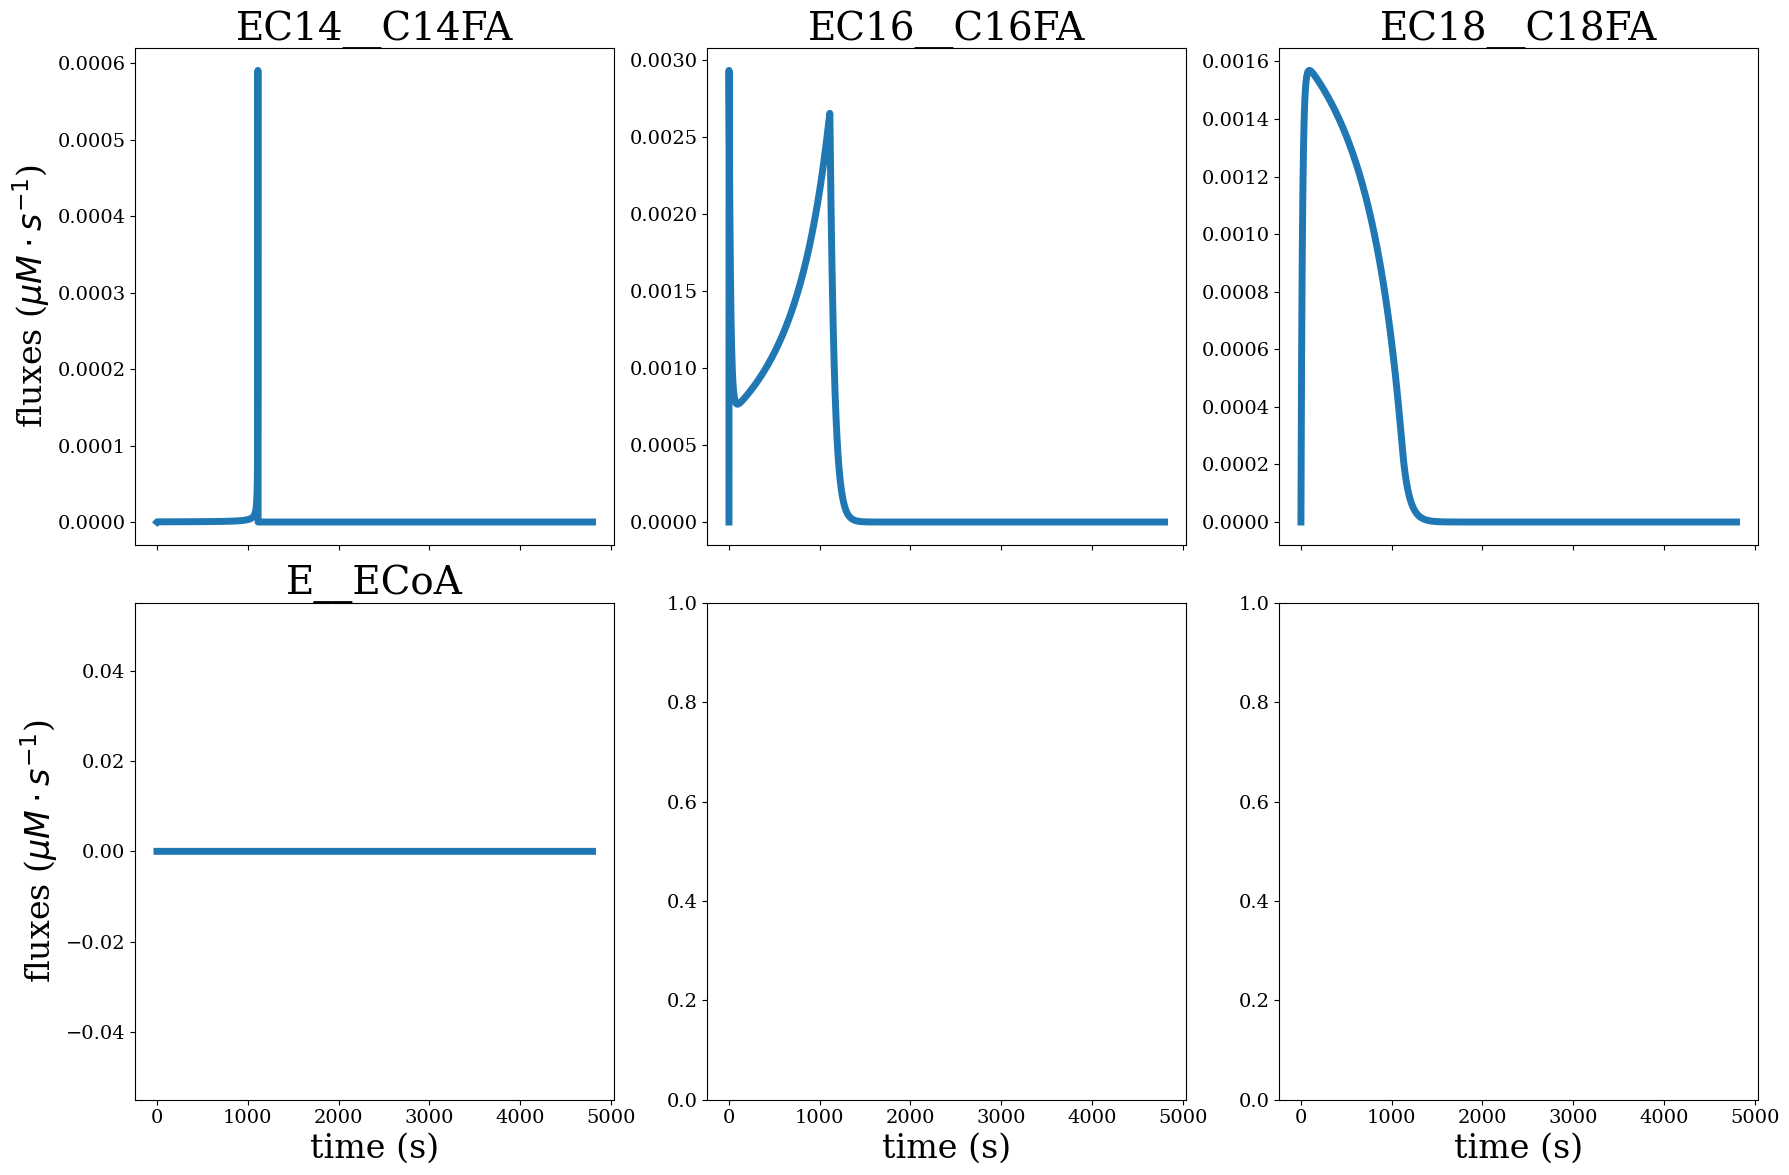

In [200]:
elongation_fluxes = [
    "AcetylCoA__EC2",
    "EC2__EC4",
    "EC4__EC6",
    "EC6__EC8",
    "EC8__EC10",
    "EC10__EC12",
    "EC12__EC14",
    "EC14__EC16",
    "EC16__EC18",
]


production_fluxes = [
   
  
    "EC14__C14FA",
    "EC16__C16FA",
    "EC18__C18FA",
    "E__ECoA",
]

fig, axs = plot_fluxes_individually(
    list_fluxes=production_fluxes,
    model=system,
    rates=rates,
    y0=y0,
    par=par_fitting_two,
    max_time=max_time2,
    ncp_list=ncp_list2,
    ncols=3,
    resizer=6,
    sharey=False,
    #         title: str = None,
    xlabel="time (s)",
    ylabel="fluxes ($\mu M \cdot s^{-1}$)",
)


In [201]:
base_line_parameters = par_fitting_two.copy()
param = pd.DataFrame(
    {"Name ": par_fitting_two.keys(), " value": par_fitting_two.values()}
)
param


,Name,value
0,beta,7.214132e+00
1,kappa,2.050593e+01
2,delta,1.108073e-05
3,kd6,8.385661e+00
4,kd7,2.006791e-02
5,kd8,1.365850e-02
6,kf_CoA,0.000000e+00
7,kb_CoA,0.000000e+00
8,kf_mal,3.196259e-03
9,kb_mal,1.694329e+05


In [202]:
from cProfile import label


fat_track =[
    ["C14FA"],
    ["C16FA"],
    ["C18FA"],
  
]

def fititing_var(par,par_interest, n_instance, var_percent, transp =0.02): 
    par1 =  par.copy()

    best_par =  par1[par_interest]
    lower_bound = best_par - best_par*var_percent
    upper_bound = best_par + best_par*var_percent
    par_range = np.linspace(lower_bound, upper_bound, n_instance)
    best_line = fatty_acid_of_interest(system,  par1  , y0, max_time = time_nefas1_simulation, ncp_list = time_nefas1_simulation)


    fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(10, 8))

    for j in par_range:
        par1[par_interest] = j
        y = fatty_acid_of_interest(system, par1  , y0, max_time = time_nefas1_simulation, ncp_list = time_nefas1_simulation)
        axs.plot(time_nefas1_simulation, y,  linewidth = 6,  alpha=transp, label = f"{par_interest} = {j}")
        
    axs.plot(time_nefas1_simulation, best_line,  linewidth = 6, label = f"baseline ({par_interest}= {par[par_interest]})", color ="b")
    axs.scatter(time_nefas1_simulation, total_nefas1, marker="s", color = "k", linewidth = 6, label = "data")
    axs.legend(loc="upper left", bbox_to_anchor=(1, 0.5))

    fig.suptitle(f'Impact  of the {par_interest} on the dynamics (x={var_percent *100}%)', fontsize=32.0, fontname="serif", fontweight="bold", y =1.01)

    axs.tick_params(axis="both", labelsize=20)
    fig.patch.set_alpha(0.0)
        
        
    fig.tight_layout()
        

In [203]:
base_line_parameters = par_fitting_two.copy()
param = pd.DataFrame(
    {"Name ": par_fit_intial_phase.keys(), " value": par_fit_intial_phase.values()}
)
param


,Name,value
0,beta,9.999969e-01
1,kappa,3.176220e-02
2,delta,1.254962e-06
3,kd6,2.695361e+00
4,kd7,2.900000e-02
5,kd8,4.866152e+00
6,kf_CoA,5.851668e+01
7,kb_CoA,5.040681e+02
8,kf_mal,7.252255e-07
9,kb_mal,1.309460e+03


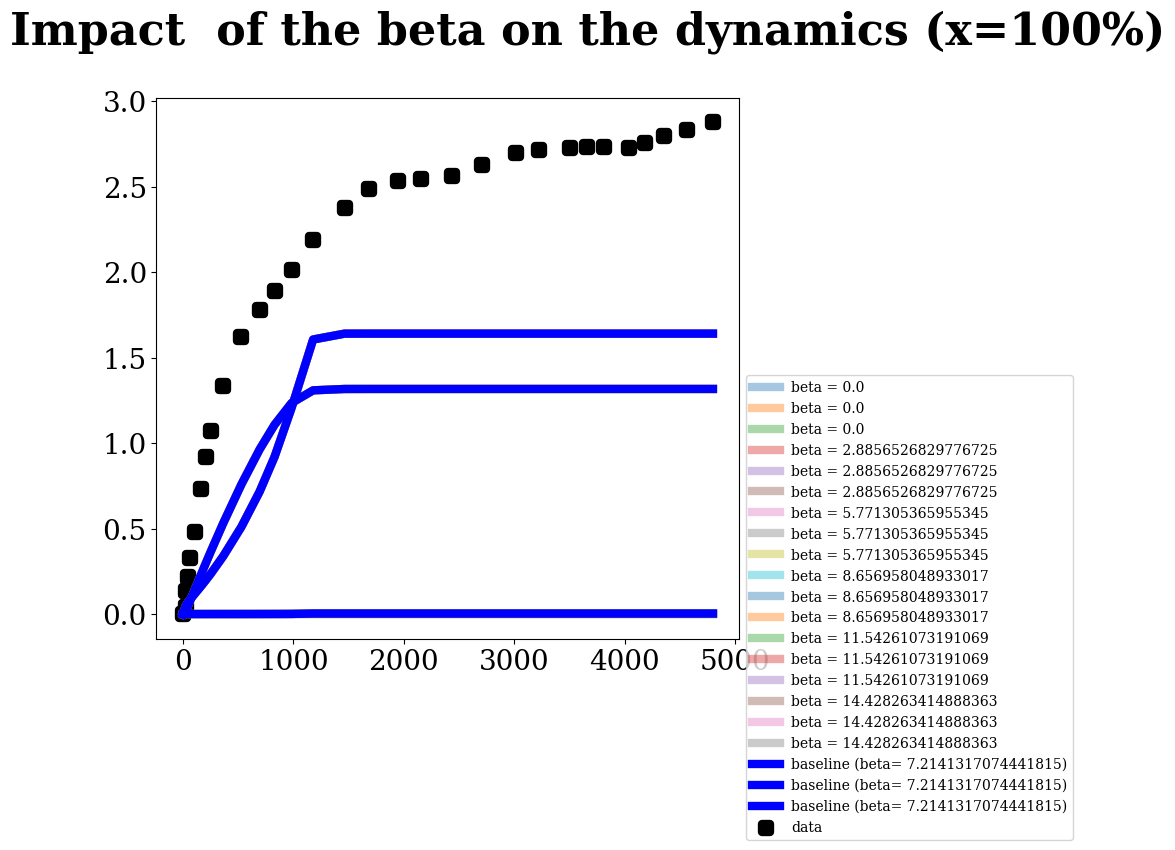

In [204]:
fititing_var(
    par=base_line_parameters,
    par_interest="beta",
    n_instance=6,
    var_percent=1,
    transp=0.4,
)
plt.savefig(RESULTS_DIR / "beta_var", dpi=300, bbox_inches="tight")


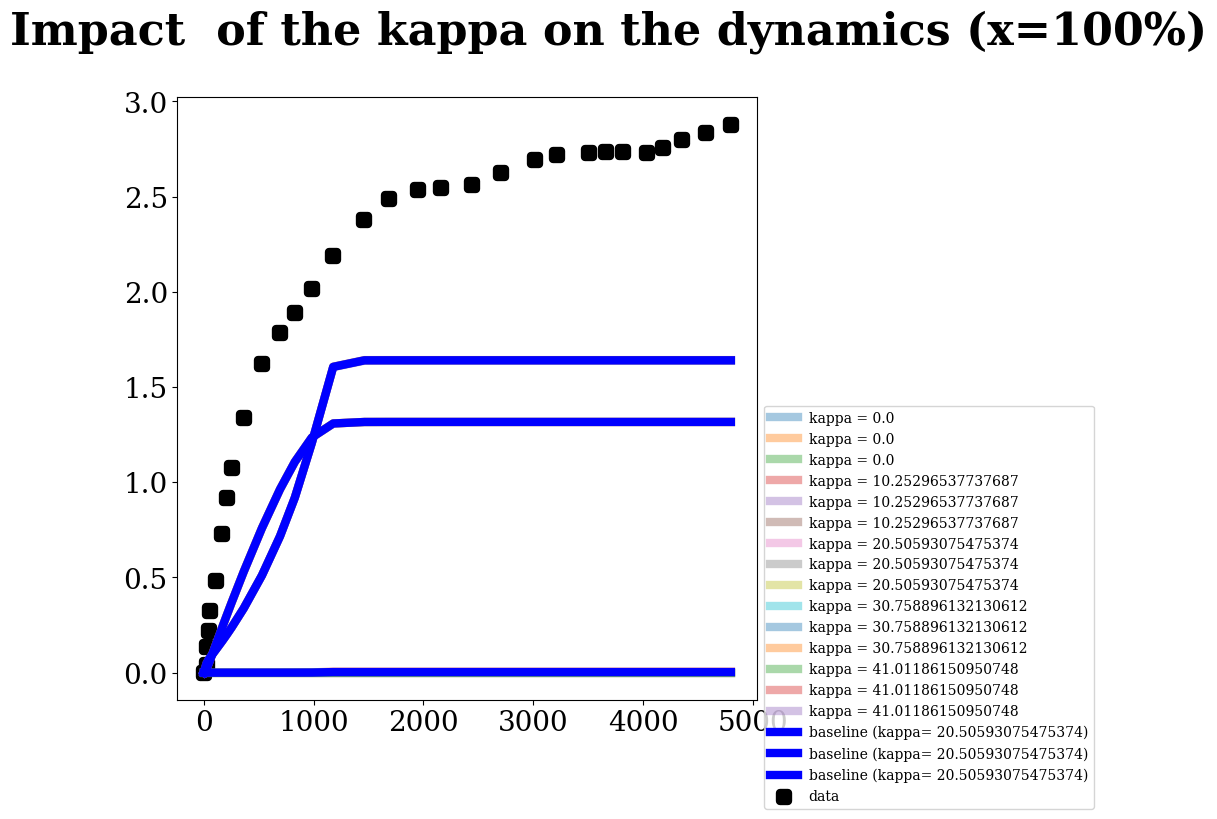

In [205]:
fititing_var(
    par=base_line_parameters,
    par_interest="kappa",
    n_instance=5,
    var_percent=1,
    transp=0.4,
)
plt.savefig(RESULTS_DIR / "kappa_var", dpi=300, bbox_inches="tight")


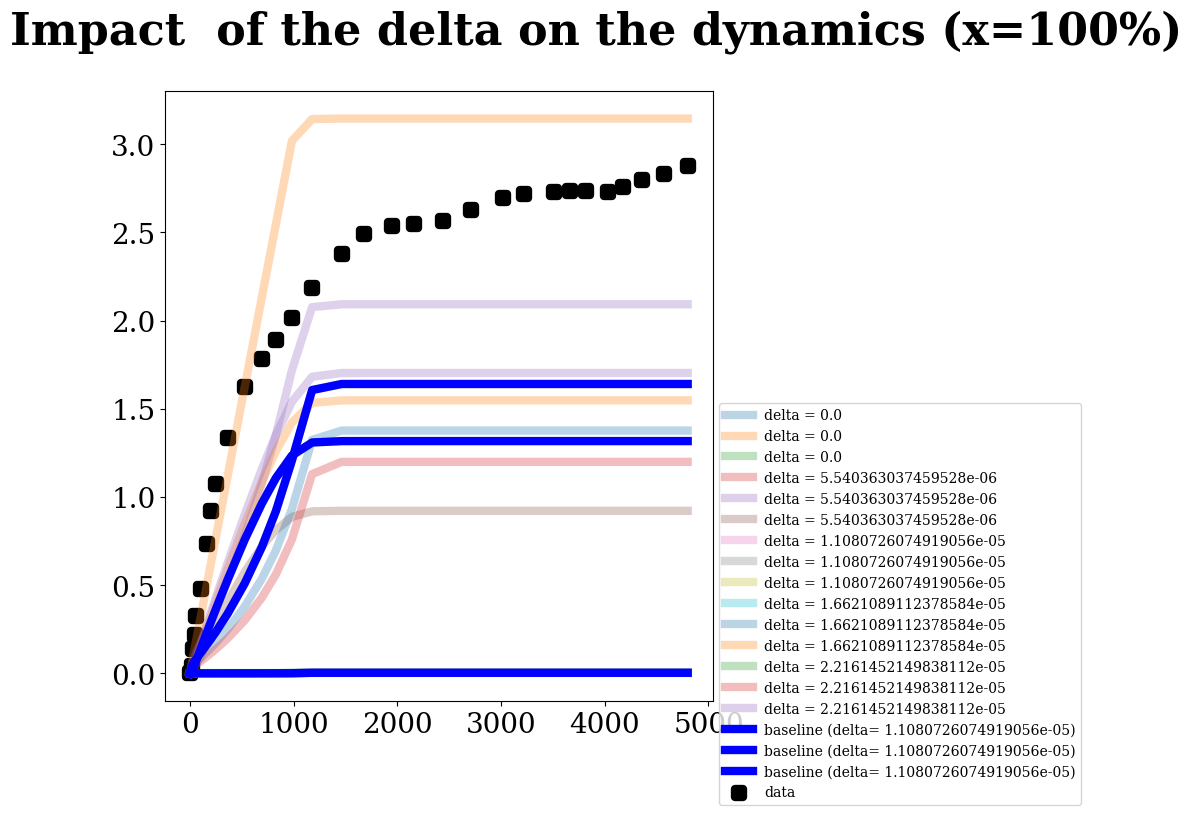

In [206]:
fititing_var(
    par=base_line_parameters,
    par_interest="delta",
    n_instance=5,
    var_percent=1,
    transp=0.3,
)
plt.savefig(RESULTS_DIR / "delta_var", dpi=300, bbox_inches="tight")


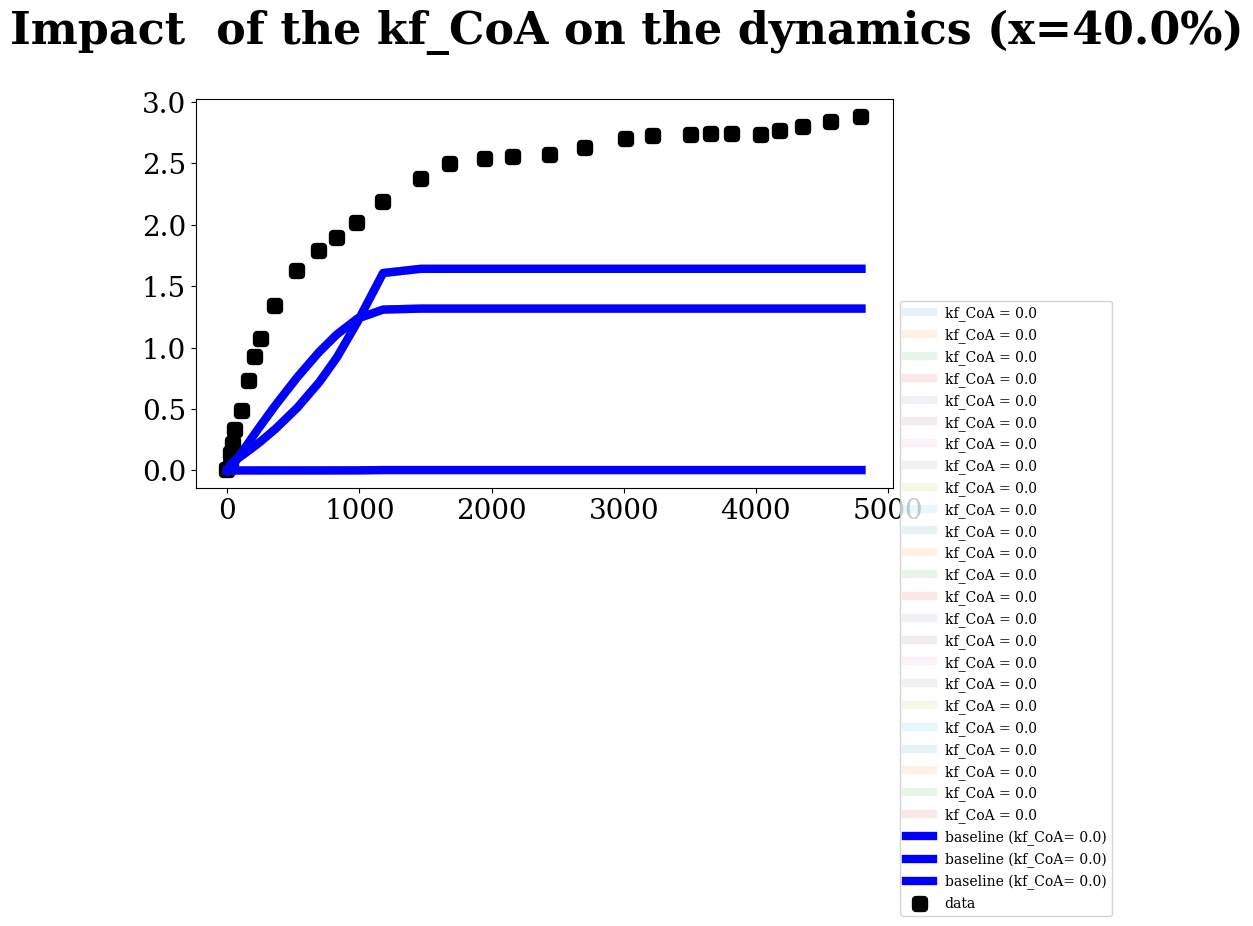

In [207]:
fititing_var(
    par=base_line_parameters,
    par_interest="kf_CoA",
    n_instance=8,
    var_percent=0.4,
    transp=0.1,
)
plt.savefig(RESULTS_DIR / "kfcoA_var", dpi=300, bbox_inches="tight")


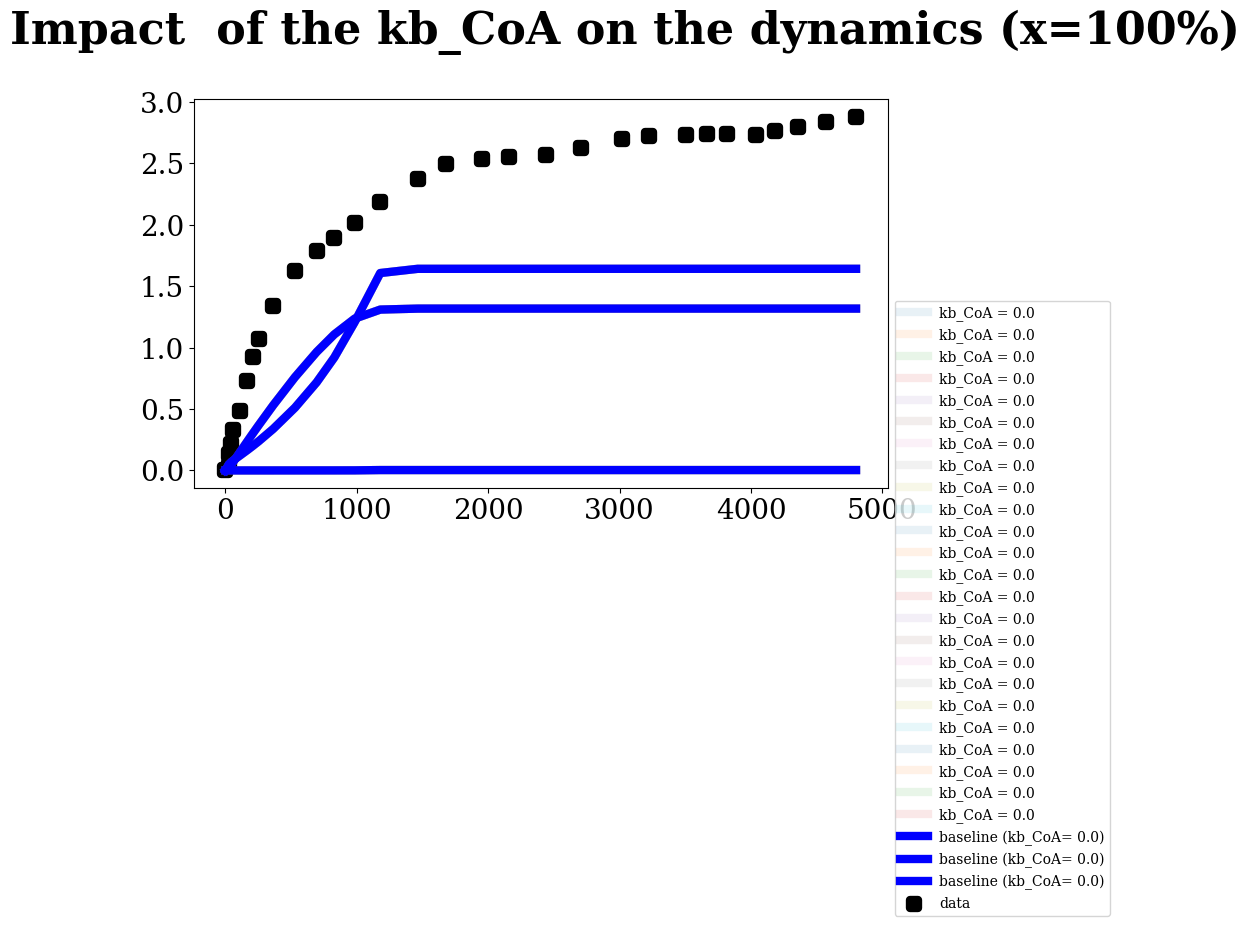

In [208]:
fititing_var(
    par=base_line_parameters,
    par_interest="kb_CoA",
    n_instance=8,
    var_percent=1,
    transp=0.1,
)
plt.savefig(RESULTS_DIR / "kb_CoA_var", dpi=300, bbox_inches="tight")


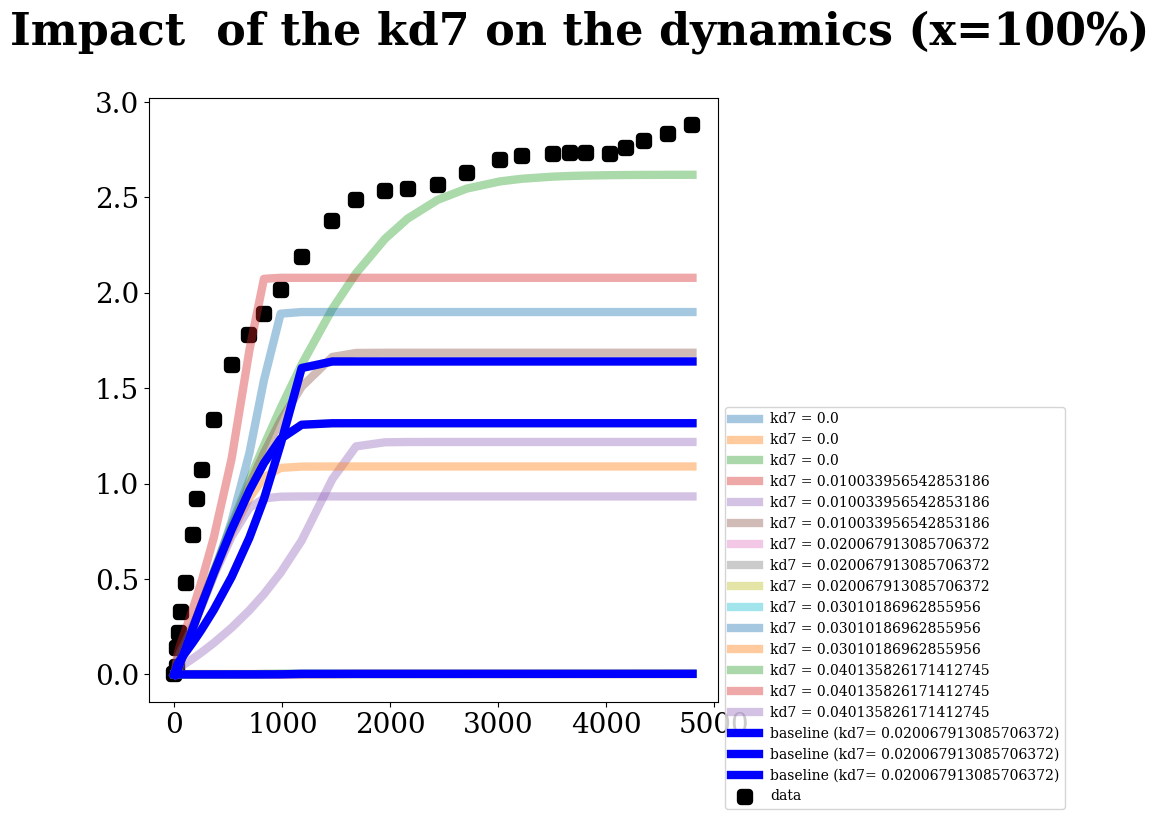

In [209]:
fititing_var(
    par=base_line_parameters,
    par_interest="kd7",
    n_instance=5,
    var_percent=1,
    transp=0.4,
)
plt.savefig(RESULTS_DIR / "kd7_var", dpi=300, bbox_inches="tight")


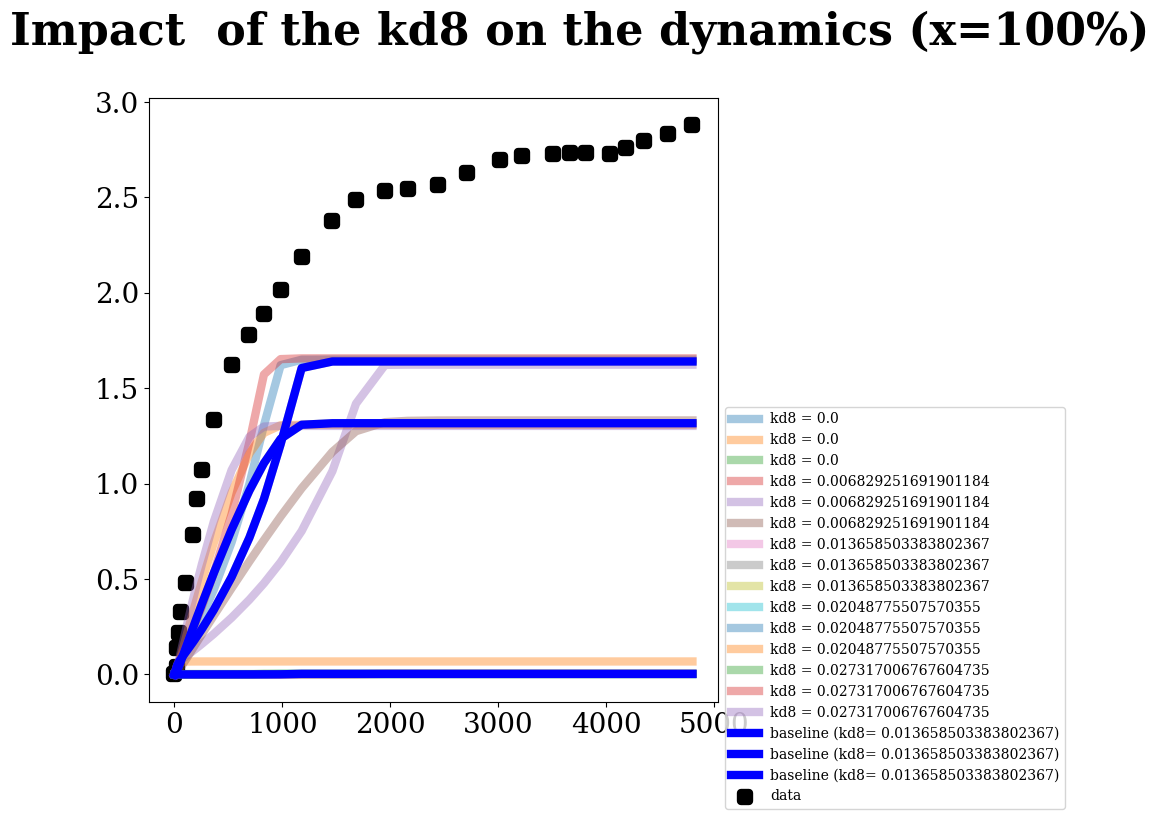

In [210]:
fititing_var(
    par=base_line_parameters,
    par_interest="kd8",
    n_instance=5,
    var_percent=1,
    transp=0.4,
)
plt.savefig(RESULTS_DIR / "kd8_var", dpi=300, bbox_inches="tight")


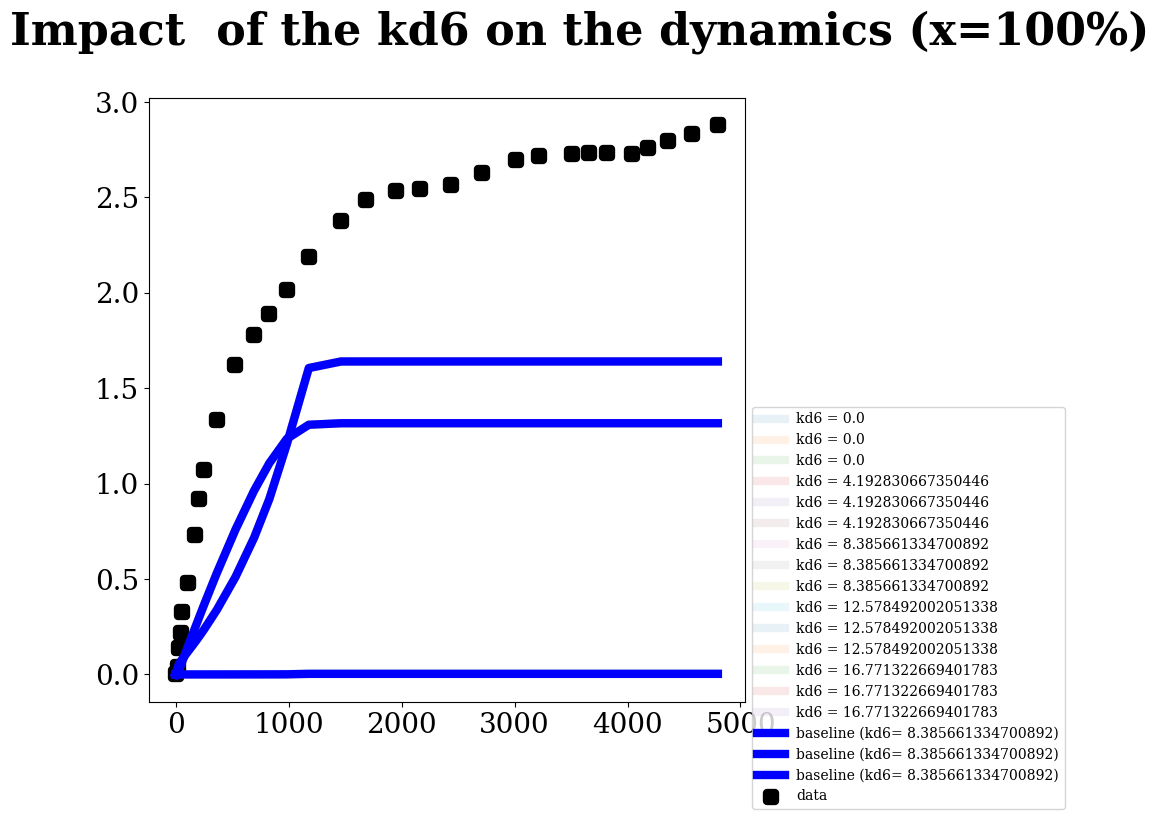

In [211]:
fititing_var(
    par=base_line_parameters,
    par_interest="kd6",
    n_instance=5,
    var_percent=1,
    transp=0.1,
)
plt.savefig(RESULTS_DIR / "kd6_var", dpi=300, bbox_inches="tight")


In [212]:
perc = 1
problem = {
    "num_vars": 12,
    "names": [
        "beta",
        "kappa",
        "delta",
        # "kd1",
        # "kd2",
        # "kd3",
        # "kd4",
        # "kd5",
        "kd6",
        "kd7",
        "kd8",
        "kf_CoA",
        "kb_CoA",
        "kf_mal",
        "kb_mal",
        "kf_acet",
        "kb_acet",
    ],
    "bounds": [
        [
            base_line_parameters["beta"] - perc * base_line_parameters["beta"],
            base_line_parameters["beta"] + perc * base_line_parameters["beta"],
        ],
        [
            base_line_parameters["kappa"] - perc * base_line_parameters["kappa"],
            base_line_parameters["kappa"] + perc * base_line_parameters["kappa"],
        ],
        [
            base_line_parameters["delta"] - perc * base_line_parameters["delta"],
            base_line_parameters["delta"] + perc * base_line_parameters["delta"],
        ],
        # [
        #     base_line_parameters["kd1"] - perc * base_line_parameters["kd1"],
        #     base_line_parameters["kd1"] + perc * base_line_parameters["kd1"] + 1e-25,
        # ],
        # [
        #     base_line_parameters["kd2"] - perc * base_line_parameters["kd2"],
        #     base_line_parameters["kd2"] + perc * base_line_parameters["kd2"] + 1e-25,
        # ],
        # [
        #     base_line_parameters["kd3"] - perc * base_line_parameters["kd3"],
        #     base_line_parameters["kd3"] + perc * base_line_parameters["kd3"] + 1e-25,
        # ],
        # [
        #     base_line_parameters["kd4"] - perc * base_line_parameters["kd4"],
        #     base_line_parameters["kd4"] + perc * base_line_parameters["kd4"] + 1e-25,
        # ],
        # [
        #     base_line_parameters["kd5"] - perc * base_line_parameters["kd5"],
        #     base_line_parameters["kd5"] + perc * base_line_parameters["kd5"] + 1e-25,
        # ],
        [
            base_line_parameters["kd6"] - perc * base_line_parameters["kd6"],
            base_line_parameters["kd6"] + perc * base_line_parameters["kd6"],
        ],
        [
            base_line_parameters["kd7"] - perc * base_line_parameters["kd7"],
            base_line_parameters["kd7"] + perc * base_line_parameters["kd7"],
        ],
        [
            base_line_parameters["kd8"] - perc * base_line_parameters["kd8"],
            base_line_parameters["kd8"] + perc * base_line_parameters["kd8"],
        ],
        [
            base_line_parameters["kf_CoA"] - perc * base_line_parameters["kf_CoA"],
            base_line_parameters["kf_CoA"]
            + perc * base_line_parameters["kf_CoA"]
            + 1e-25,
        ],
        [
            base_line_parameters["kb_CoA"] - perc * base_line_parameters["kb_CoA"],
            base_line_parameters["kb_CoA"]
            + perc * base_line_parameters["kb_CoA"]
            + 1e-25,
        ],
        [
            base_line_parameters["kf_mal"] - perc * base_line_parameters["kf_mal"],
            base_line_parameters["kf_mal"] + perc * base_line_parameters["kf_mal"],
        ],
        [
            base_line_parameters["kb_mal"] - perc * base_line_parameters["kb_mal"],
            base_line_parameters["kb_mal"] + perc * base_line_parameters["kb_mal"],
        ],
        [
            base_line_parameters["kf_acet"] - perc * base_line_parameters["kf_acet"],
            base_line_parameters["kf_acet"] + perc * base_line_parameters["kf_acet"],
        ],
        [
            base_line_parameters["kb_acet"] - perc * base_line_parameters["kb_acet"],
            base_line_parameters["kb_acet"] + perc * base_line_parameters["kb_acet"],
        ],
    ],
}
print(problem["bounds"])
param_values = saltelli.sample(problem, 5, calc_second_order=True)

N = len(param_values)  # number of parameter samples
Y = []
for i in range(N):
    param_dict = dict(zip(problem["names"], param_values[i]))
    Y.append(
        (
            fatty_acid_of_interest(
                system,
                param_dict,
                y0,
                max_time=time_nefas1_simulation,
                ncp_list=time_nefas1_simulation,
            )
        )
    )
a = np.concatenate(Y, axis=None)

Si = sobol.analyze(problem, a, print_to_console=False)

print(Si["S1"])


[[0.0, 14.428263414888363], [0.0, 41.01186150950748], [0.0, 2.2161452149838112e-05], [0.0, 16.771322669401783], [0.0, 0.040135826171412745], [0.0, 0.027317006767604735], [0.0, 1e-25], [0.0, 1e-25], [0.0, 0.006392517170018319], [0.0, 338865.7730413479], [0.0, 1.8621610919922205e-09], [0.0, 197.14923051451476]]


/home/chilperic/mambaforge/envs/fatty-acids/lib/python3.10/site-packages/SALib/sample/saltelli.py:94: UserWarning: 
        Convergence properties of the Sobol' sequence is only valid if
        `N` (5) is equal to `2^n`.
        
  warnings.warn(msg)


[0.77581101 0.04558451 0.02507582 0.8458954  0.06405306 0.04667809
 0.91958471 0.0868558  0.06498638 0.99511105 0.1073565  0.09184206]


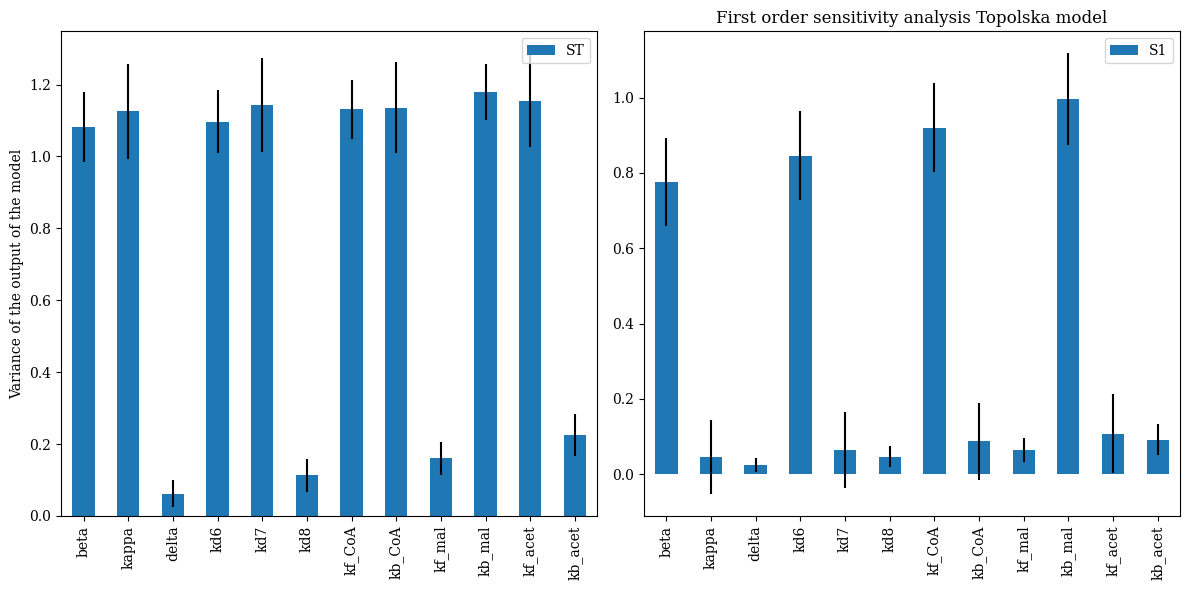

In [213]:
Saltelli_T, Saltelli_1st, Saltelli_2st = Si.to_df()

# More direct control by manually specifying figure attributes
# See Figure 2 below
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

ax1 = barplot(Saltelli_T, ax=ax1)
ax2 = barplot(Saltelli_1st, ax=ax2)
ax1.set_ylabel("Variance of the output of the model")
# ax3 = barplot(Saltelli_2st, ax=ax3)
plt.title("First order sensitivity analysis Topolska model")
plt.tight_layout()


,S2,S2_conf
"(beta, kappa)",-0.706568,0.128507
"(beta, delta)",-0.696613,0.118581
"(beta, kd6)",-0.503380,0.182638
"(beta, kd7)",-0.709701,0.128554
"(beta, kd8)",-0.694525,0.119723
...,...,...
"(kf_mal, kf_acet)",-0.057999,0.099534
"(kf_mal, kb_acet)",0.882104,0.125714
"(kb_mal, kf_acet)",-0.975679,0.124582
"(kb_mal, kb_acet)",-0.970711,0.122725


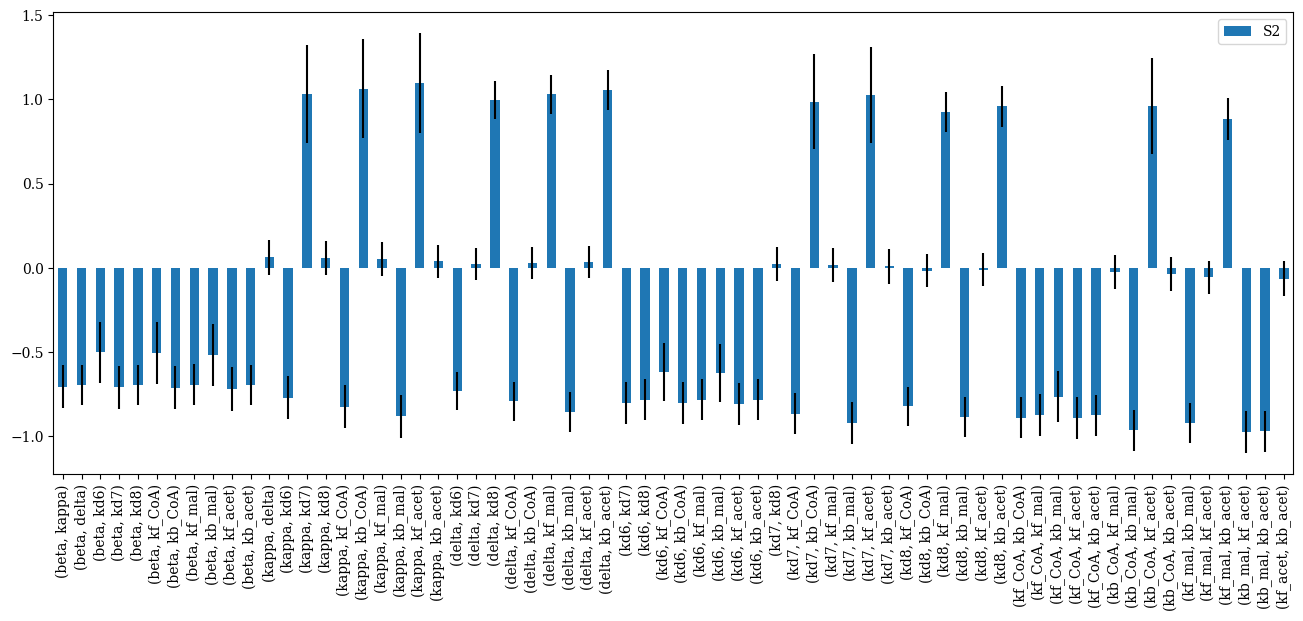

In [214]:
fig, (ax1) = plt.subplots(1, 1, figsize=(16, 6))
barplot(Saltelli_2st, ax=ax1)
Saltelli_2st
